Notebook demonstrating how ODE simulations and linear framework solutions can have similar outputs for the Kinetic proofreading model (STAT1)

In [2]:
from pysb import Model, Parameter, Compartment, Monomer, Parameter, Rule, Initial, Observable
from pysb.simulator import ScipyOdeSimulator
import numpy as np
import cython
import matplotlib.pyplot as plt
import sympy as sp
import pickle
from collections import Counter
import sys, os
from src.PySBtoLF_func import generate_graphs,adapt_graph_get_rhos
from time import time
from scipy.optimize import least_squares

In [3]:
def func_time(IL10):
    if IL10 > 1e-7:
        return 0.1*5,1e4
    else:
        IL10 = abs(np.log10(IL10)) - 3
        return 10**(IL10)/(1e4)*5,10**(IL10)

PA={
    "vol_EC" : 1.0E-10, # In dm # OG: 1.0E-10
    "surf_cell" : 1.11545244e-07, # OG: 1.4e-08 Mut_noSOCS: 1.4e-7
    "vol_cell" : 3.0E-12, # In dm
    "k_ILM_f" : 6.97E+05,
    "k_ILM_b" : 3.07214605e+00, #4.34 # OG: 4.34e-02 Mut_noSOCS: 8.34e-02
    "k_IL_RA_f" : 6.97E+05,
    "k_IL_RA_b" : 5.94742574e-04, # OG: 1.42E-04 Mut_noSOCS: 1.42E-03
    "k_IL_RB_f" : 6.97E+05,
    "k_IL_RB_b" : 1394, # OG: 1394
    "k_IL_RA_RB_f" : 6.97E+05,
    "k_IL_RA_RB_b" : 1.32365577e+00, # OG: 243.95
    "k_STAT1_f" : 6.55E+06*10,
    "k_STAT1_b" : 0.678,
    "k_M_f" : 6.55E+06*1000,
    "k_M_b" : 0.678,
    "k_STAT3_f" : 6.55E+06*1000,
    "k_STAT3_b" : 0.678,
    "k_PHOS" : 3.16E-03,
    "k_DEPHOS" : 0.000664996232095083
}

IC = {
    "IL0":1e-7,
    "RA0":750,
    "RB0":2323,
    "STAT10" : 477858.2479731492,
    "M0" : 477858.2479731492,
    "STAT30" : 477858.2479731492
    }

First we generate the full model with a protein M binding to RA and STAT1 binding to protein M to generate more dependancy on RB binding (Kinetic proofreading)

In [6]:
PA_WT={
    "vol_EC" : 1.0E-10, # In dm # OG: 1.0E-10
    "surf_cell" : 1.11545244e-07, # OG: 1.4e-08 Mut_noSOCS: 1.4e-7
    "vol_cell" : 3.0E-12, # In dm
    "k_ILM_f" : 6.97E+05,
    "k_ILM_b" : 3.07214605e+00, #4.34 # OG: 4.34e-02 Mut_noSOCS: 8.34e-02
    "k_IL_RA_f" : 6.97E+05,
    "k_IL_RA_b" : 5.94742574e-04, # OG: 1.42E-04 Mut_noSOCS: 1.42E-03
    "k_IL_RB_f" : 6.97E+05*10000,
    "k_IL_RB_b" : 1394*1000, # OG: 1394
    "k_IL_RA_RB_f" : 6.97E+05*10000,
    "k_IL_RA_RB_b" : 1.32365577e+00*1000, # OG: 243.95
    "k_STAT1_f" : 6.55E+06*1000/10,
    "k_STAT1_b" : 0.678/1000000,
    "k_M_f" : 6.55E+06*10/10,
    "k_M_b" : 0.678/1000000,
    "k_STAT3_f" : 6.55E+06*10000,
    "k_STAT3_b" : 0.678*1000,
    "k_PHOS" : 3.16E-03*5000,
    "k_DEPHOS" : 0.000664996232095083
}
PA_mut={
    "vol_EC" : 1.0E-10, # In dm # OG: 1.0E-10
    "surf_cell" : 1.11545244e-07, # OG: 1.4e-08 Mut_noSOCS: 1.4e-7
    "vol_cell" : 3.0E-12, # In dm
    "k_ILM_f" : 6.97E+05,
    "k_ILM_b" : 3.07214605e+00, #4.34 # OG: 4.34e-02 Mut_noSOCS: 8.34e-02
    "k_IL_RA_f" : 6.97E+05,
    "k_IL_RA_b" : 5.94742574e-04, # OG: 1.42E-04 Mut_noSOCS: 1.42E-03
    "k_IL_RB_f" : 6.97E+05*100000,
    "k_IL_RB_b" : 1394*1000, # OG: 1394
    "k_IL_RA_RB_f" : 6.97E+05*100000,
    "k_IL_RA_RB_b" : 1.32365577e+00*1000, # OG: 243.95
    "k_STAT1_f" : 6.55E+06*1000/10,
    "k_STAT1_b" : 0.678/1000000,
    "k_M_f" : 6.55E+06*10/10,
    "k_M_b" : 0.678/1000000,
    "k_STAT3_f" : 6.55E+06*10000,
    "k_STAT3_b" : 0.678*1000,
    "k_PHOS" : 3.16E-03*5000,
    "k_DEPHOS" : 0.000664996232095083
}

In [7]:
def model_func_full(PA,IC):
    Na=6.023e23
    Width_PM = 1e-7 # In dm
    # Initialize model
    Model()
    
    # Compartment
    Compartment(name='EC', parent=None, dimension=3, size=None)
    Compartment(name='Cell_PM', parent=EC, dimension=2, size=None)
    Compartment(name='Cell_CP', parent=Cell_PM, dimension=3, size=None)
    
    # Monomers
    Monomer('ILM')
    Monomer('IL', ['bA1', 'bA2', 'bB1', 'bB2','B_t'], {'B_t': ['QB','TB','DB','SB','U']})
    Monomer('RA', ['bA', 'bM'])
    Monomer('RB', ['bB'])
    Monomer('M', ['bRA','bSTAT1'])
    Monomer('STAT1', ['b1','P'], {'P': ['u', 'p']})
    
    # Parameters (We put whatever number)
    Parameter('K_ILM_f', PA["k_ILM_f"]/(Na*PA["vol_EC"])*2)
    Parameter('K_ILM_b', PA["k_ILM_b"])
    
    Parameter('K_IL_RA_f', PA["k_IL_RA_f"]/(Na*PA["vol_EC"]))
    Parameter('K_IL_RA_b', PA["k_IL_RA_b"])
    Parameter('K_IL_RB_f', PA["k_IL_RB_f"]/(Na*PA["vol_EC"]))
    Parameter('K_IL_RB_b', PA["k_IL_RB_b"])
    
    Parameter('K_IL_RA2_f', PA["k_IL_RA_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RA2_b', PA["k_IL_RA_b"])
    Parameter('K_IL_RB2_f', PA["k_IL_RB_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RB2_b', PA["k_IL_RB_b"])
    Parameter('K_IL_RA_RB_f', PA["k_IL_RA_RB_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RA_RB_b', PA["k_IL_RA_RB_b"])

    Parameter('K_M_f', PA["k_M_f"]/(Na*PA["vol_cell"]))
    Parameter('K_M_b', PA["k_M_b"])
    Parameter('K_STAT1_f', PA["k_STAT1_f"]/(Na*PA["vol_cell"]))
    Parameter('K_STAT1_b', PA["k_STAT1_b"])
    Parameter('K_PHOS', PA["k_PHOS"])   
    Parameter('K_DEPHOS', PA["k_DEPHOS"])
    
    # Complexes and reactions (binding of receptors)
    IL_free = IL(bA1=None, bA2=None, bB1=None, bB2=None, B_t='U')
    ILM_free = ILM()
    Rule('IL_binding', ILM_free + ILM_free | IL_free, *[K_ILM_f, K_ILM_b])
    
    # Binding of 1st receptor
    IL_RA1_alone = IL(bA1=1, bA2=None, bB1=None, bB2=None, B_t='SB') % RA(bA=1, bM=None)
    Rule('IL_RA1_alone_binding', IL_free + RA(bA=None, bM=None)| IL_RA1_alone, *[K_IL_RA_f, K_IL_RA_b])
    IL_RA2_alone = IL(bA1=None, bA2=2, bB1=None, bB2=None, B_t='SB') % RA(bA=2, bM=None)
    Rule('IL_RA2_alone_binding', IL_free + RA(bA=None, bM=None) | IL_RA2_alone, *[K_IL_RA_f, K_IL_RA_b])
    IL_RB1_alone = IL(bA1=None, bA2=None, bB1=3, bB2=None, B_t='SB') % RB(bB=3)
    Rule('IL_RB1_binding_alone', IL_free + RB(bB=None) | IL_RB1_alone, *[K_IL_RB_f, K_IL_RB_b])
    IL_RB2_alone = IL(bA1=None, bA2=None, bB1=None, bB2=4, B_t='SB') % RB(bB=4)
    Rule('IL_RB2_binding_alone', IL_free + RB(bB=None) | IL_RB2_alone, *[K_IL_RB_f, K_IL_RB_b])
    
    # Binding of 2nd receptor
    IL_RA1_RB1_DB = IL(bA1=1, bA2=None, bB1=3, bB2=None, B_t='DB') % RA(bA=1, bM=None) % RB(bB=3)
    Rule('IL_RA1_wRB1_binding_DB', IL_RB1_alone + RA(bA=None, bM=None) | IL_RA1_RB1_DB, *[K_IL_RA2_f, K_IL_RA2_b])
    IL_RA1_RB1_M1_DB = IL(bA1=1, bA2=None, bB1=2, bB2=None, B_t='DB') % RA(bA=1, bM=5) % RB(bB=2) % M(bRA=5, bSTAT1=None)
    IL_RA1_RB1_MS1_DB = IL(bA1=1, bA2=None, bB1=2, bB2=None, B_t='DB') % RA(bA=1, bM=5) % RB(bB=2) % M(bRA=5, bSTAT1=7) % STAT1(b1=7, P='u')
    Rule('IL_RA1_wRB1_unbinding_DB', IL_RA1_RB1_M1_DB >> IL_RB1_alone + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b) 
    Rule('IL_RA1_wRB1_unbinding_DB2', IL_RA1_RB1_MS1_DB >> IL_RB1_alone + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    IL_noRA1_noRB1_SB = IL(bA1=None, bB1=None, B_t='SB')
    IL_RA1_noRB1_DB = IL(bA1=1, bB1=None, B_t='DB') % RA(bA=1, bM=None) 
    Rule('IL_RA1_noRB1_binding_DB', IL_noRA1_noRB1_SB + RA(bA=None, bM=None) | IL_RA1_noRB1_DB, *[K_IL_RA2_f, K_IL_RA2_b])
    
    IL_RA2_RB2_DB = IL(bA1=None, bA2=2, bB1=None, bB2=4, B_t='DB') % RA(bA=2, bM=None) % RB(bB=4)
    Rule('IL_RA2_wRB2_binding_DB', IL_RB2_alone + RA(bA=None, bM=None) | IL_RA2_RB2_DB, *[K_IL_RA2_f, K_IL_RA2_b])
    IL_RA2_RB2_M2_DB = IL(bA1=None, bA2=2, bB1=None, bB2=4, B_t='DB') % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=None)
    IL_RA2_RB2_MS2_DB = IL(bA1=None, bA2=2, bB1=None, bB2=4, B_t='DB') % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=8) % STAT1(b1=8, P='u')
    Rule('IL_RA2_wRB2_unbinding_DB', IL_RA2_RB2_M2_DB >> IL_RB2_alone + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA2_wRB2_unbinding_DB2', IL_RA2_RB2_MS2_DB >> IL_RB2_alone + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    IL_noRA2_noRB2_SB = IL(bA2=None, bB2=None, B_t='SB')
    IL_RA2_noRB2_DB = IL(bA2=2, bB2=None, B_t='DB') % RA(bA=2, bM=None) 
    Rule('IL_RA2_noRB2_binding_DB', IL_noRA2_noRB2_SB + RA(bA=None, bM=None) | IL_RA2_noRB2_DB, *[K_IL_RA2_f, K_IL_RA2_b])
    
    IL_noRA1_RB1_DB = IL(bA1=None, bB1=3, B_t='DB') % RB(bB=3)
    Rule('IL_noRA1_RB1_binding_DB', IL_noRA1_noRB1_SB + RB(bB=None) | IL_noRA1_RB1_DB, *[K_IL_RB2_f, K_IL_RB2_b])
    Rule('IL_wRA1_RB1_binding_DB', IL_RA1_alone + RB(bB=None) | IL_RA1_RB1_DB, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_wRA1_RB1_unbinding_DB', IL_RA1_RB1_M1_DB >> IL_RA1_alone + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_wRA1_RB1_unbinding_DB2', IL_RA1_RB1_MS1_DB >> IL_RA1_alone + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)

    IL_noRA2_RB2_DB = IL(bA2=None, bB2=4, B_t='DB') % RB(bB=4)
    Rule('IL_noRA2_RB2_binding_DB', IL_noRA2_noRB2_SB + RB(bB=None) | IL_noRA2_RB2_DB, *[K_IL_RB2_f, K_IL_RB2_b])
    Rule('IL_wRA2_RB2_binding_DB', IL_RA2_alone + RB(bB=None) | IL_RA2_RB2_DB, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_wRA2_RB2_unbinding_DB', IL_RA2_RB2_M2_DB >> IL_RA2_alone + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_wRA2_RB2_unbinding_DB2', IL_RA2_RB2_MS2_DB >> IL_RA2_alone + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    
    # Binding of 3rd receptor
    IL_noRA1_RB1_DB = IL(bA1=None, bB1=3, B_t='DB') % RB(bB=3)
    IL_RA1_RB1_TB = IL(bA1=1, bB1=3, B_t='TB') % RA(bA=1, bM=None) % RB(bB=3)
    Rule('IL_RA1_wRB1_binding_TB', IL_noRA1_RB1_DB + RA(bA=None, bM=None) | IL_RA1_RB1_TB, *[K_IL_RA2_f, K_IL_RA2_b])
    IL_RA1_RB1_M1_TB = IL(bA1=1, bB1=2, B_t='TB') % RA(bA=1, bM=5) % RB(bB=2) % M(bRA=5, bSTAT1=None)
    IL_RA1_RB1_MS1_TB = IL(bA1=1, bB1=2, B_t='TB') % RA(bA=1, bM=5) % RB(bB=2) % M(bRA=5, bSTAT1=7) % STAT1(b1=7, P='u')
    Rule('IL_RA1_wRB1_unbinding_TB', IL_RA1_RB1_M1_TB >> IL_noRA1_RB1_DB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA1_wRB1_unbinding_TB2', IL_RA1_RB1_MS1_TB >> IL_noRA1_RB1_DB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    IL_noRA1_noRB1_DB = IL(bA1=None, bB1=None, B_t='DB')
    IL_RA1_noRB1_TB = IL(bA1=1, bB1=None, B_t='TB') % RA(bA=1, bM=None) 
    Rule('IL_RA1_noRB1_binding_TB', IL_noRA1_noRB1_DB + RA(bA=None, bM=None) | IL_RA1_noRB1_TB, *[K_IL_RA2_f, K_IL_RA2_b])
    
    IL_noRA2_RB2_DB = IL(bA2=None, bB2=4, B_t='DB') % RB(bB=4)
    IL_RA2_RB2_TB = IL(bA2=2, bB2=4, B_t='TB') % RA(bA=2, bM=None) % RB(bB=4)
    Rule('IL_RA2_wRB2_binding_TB', IL_noRA2_RB2_DB + RA(bA=None, bM=None) | IL_RA2_RB2_TB, *[K_IL_RA2_f, K_IL_RA2_b])
    IL_RA2_RB2_M2_TB = IL(bA2=2, bB2=4, B_t='TB') % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=None)
    IL_RA2_RB2_MS2_TB = IL(bA2=2, bB2=4, B_t='TB') % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=8) % STAT1(b1=8, P='u')
    Rule('IL_RA2_wRB2_unbinding_TB', IL_RA2_RB2_M2_TB >> IL_noRA2_RB2_DB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA2_wRB2_unbinding_TB2', IL_RA2_RB2_MS2_TB >> IL_noRA2_RB2_DB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    IL_noRA2_noRB2_DB = IL(bA2=None, bB2=None, B_t='DB')
    IL_RA2_noRB2_TB = IL(bA2=2, bB2=None, B_t='TB') % RA(bA=2, bM=None) 
    Rule('IL_RA2_noRB2_binding_TB', IL_noRA2_noRB2_DB + RA(bA=None, bM=None) | IL_RA2_noRB2_TB, *[K_IL_RA2_f, K_IL_RA2_b])

    IL_noRA1_RB1_TB = IL(bA1=None, bB1=3, B_t='TB') % RB(bB=3)
    Rule('IL_noRA1_RB1_binding_TB', IL_noRA1_noRB1_DB + RB(bB=None) | IL_noRA1_RB1_TB, *[K_IL_RB2_f, K_IL_RB2_b])
    IL_RA1_noRB1_DB = IL(bA1=1, bB1=None, B_t='DB') % RA(bA=1, bM=None)
    Rule('IL_wRA1_RB1_binding_TB', IL_RA1_noRB1_DB + RB(bB=None) | IL_RA1_RB1_TB, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_wRA1_RB1_unbinding_TB', IL_RA1_RB1_M1_TB >> IL_RA1_noRB1_DB + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_wRA1_RB1_unbinding_TB2', IL_RA1_RB1_MS1_TB >> IL_RA1_noRB1_DB + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    
    IL_noRA2_RB2_TB = IL(bA2=None, bB2=4, B_t='TB') % RB(bB=4)
    Rule('IL_noRA2_RB2_binding_TB', IL_noRA2_noRB2_DB + RB(bB=None) | IL_noRA2_RB2_TB, *[K_IL_RB2_f, K_IL_RB2_b])
    IL_RA2_noRB2_DB = IL(bA2=2, bB2=None, B_t='DB') % RA(bA=2, bM=None)
    Rule('IL_wRA2_RB2_binding_TB', IL_RA2_noRB2_DB + RB(bB=None) | IL_RA2_RB2_TB, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_wRA2_RB2_unbinding_TB', IL_RA2_RB2_M2_TB >> IL_RA2_noRB2_DB + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_wRA2_RB2_unbinding_TB2', IL_RA2_RB2_MS2_TB >> IL_RA2_noRB2_DB + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    
    # Binding of 4th receptor
    IL_RA1_RA2_RB1_RB2 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=None) % RA(bA=2, bM=None) % RB(bB=3) % RB(bB=4)
    IL_RA1_RA2_RB1_RB2_M1 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=5) % RA(bA=2, bM=None) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=None)
    IL_RA1_RA2_RB1_RB2_M2 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=None) % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=6, bSTAT1=None)
    IL_RA1_RA2_RB1_RB2_MS1 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=5) % RA(bA=2, bM=None) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=7) % STAT1(b1=7, P='u')
    IL_RA1_RA2_RB1_RB2_MS2 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=None) % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=6, bSTAT1=8) % STAT1(b1=8, P='u')
    IL_RA1_RA2_RB1_RB2_M1_M2 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=5) % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=None) % M(bRA=6, bSTAT1=None)
    IL_RA1_RA2_RB1_RB2_MS1_M2 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=5) % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=7) % M(bRA=6, bSTAT1=None) % STAT1(b1=7, P='u')
    IL_RA1_RA2_RB1_RB2_M1_MS2 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=5) % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=None) % M(bRA=6, bSTAT1=8) % STAT1(b1=8, P='u')
    IL_RA1_RA2_RB1_RB2_MS1_MS2 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=5) % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=7) % M(bRA=6, bSTAT1=8) % STAT1(b1=7, P='u') % STAT1(b1=8, P='u')

    
    IL_noRA1_TB = IL(bA1=None, bA2=2, bB1=3, bB2=4, B_t='TB') % RA(bA=2, bM=None) % RB(bB=3) % RB(bB=4)
    IL_noRA1_TB_M2 = IL(bA1=None, bA2=2, bB1=3, bB2=4, B_t='TB') % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=6, bSTAT1=None)
    IL_noRA1_TB_MS2 = IL(bA1=None, bA2=2, bB1=3, bB2=4, B_t='TB') % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=6, bSTAT1=8) % STAT1(b1=8, P='u')
    Rule('IL_RA1_binding_fin', IL_noRA1_TB + RA(bA=None, bM=None) | IL_RA1_RA2_RB1_RB2, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA1_unbinding_fin1', IL_RA1_RA2_RB1_RB2_M1 >> IL_noRA1_TB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA1_binding_fin2', IL_noRA1_TB_M2 + RA(bA=None, bM=None) | IL_RA1_RA2_RB1_RB2_M2, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA1_unbinding_fin2', IL_RA1_RA2_RB1_RB2_MS1 >> IL_noRA1_TB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    Rule('IL_RA1_binding_fin3', IL_noRA1_TB_MS2 + RA(bA=None, bM=None) | IL_RA1_RA2_RB1_RB2_MS2, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA1_unbinding_fin3', IL_RA1_RA2_RB1_RB2_M1_M2 >> IL_noRA1_TB_M2 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA1_unbinding_fin4', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_noRA1_TB_M2 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    Rule('IL_RA1_unbinding_fin5', IL_RA1_RA2_RB1_RB2_M1_MS2 >> IL_noRA1_TB_MS2 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA1_unbinding_fin6', IL_RA1_RA2_RB1_RB2_MS1_MS2 >> IL_noRA1_TB_MS2 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    
    IL_noRA2_TB = IL(bA1=1, bA2=None, bB1=3, bB2=4, B_t='TB') % RA(bA=1, bM=None) % RB(bB=3) % RB(bB=4)
    IL_noRA2_TB_M1 = IL(bA1=1, bA2=None, bB1=3, bB2=4, B_t='TB') % RA(bA=1, bM=5) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=None)
    IL_noRA2_TB_MS1 = IL(bA1=1, bA2=None, bB1=3, bB2=4, B_t='TB') % RA(bA=1, bM=5) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=7) % STAT1(b1=7, P='u')
    Rule('IL_RA2_binding_fin', IL_noRA2_TB + RA(bA=None, bM=None) | IL_RA1_RA2_RB1_RB2, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA2_binding_fin2', IL_noRA2_TB_M1 + RA(bA=None, bM=None) | IL_RA1_RA2_RB1_RB2_M1, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA2_unbinding_fin1', IL_RA1_RA2_RB1_RB2_M2 >> IL_noRA2_TB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA2_binding_fin3', IL_noRA2_TB_MS1 + RA(bA=None, bM=None) | IL_RA1_RA2_RB1_RB2_MS1, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA2_unbinding_fin2', IL_RA1_RA2_RB1_RB2_MS2 >> IL_noRA2_TB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    Rule('IL_RA2_unbinding_fin3', IL_RA1_RA2_RB1_RB2_M1_M2 >> IL_noRA2_TB_M1 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA2_unbinding_fin4', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_noRA2_TB_MS1 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA2_unbinding_fin5', IL_RA1_RA2_RB1_RB2_M1_MS2 >> IL_noRA2_TB_M1 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    Rule('IL_RA2_unbinding_fin6', IL_RA1_RA2_RB1_RB2_MS1_MS2 >> IL_noRA2_TB_MS1 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    
    IL_noRB1_TB = IL(bA1=1, bA2=2, bB1=None, bB2=4, B_t='TB') % RA(bA=1, bM=None) % RA(bA=2, bM=None) % RB(bB=4)
    IL_noRB1_TB_M2 = IL(bA1=1, bA2=2, bB1=None, bB2=4, B_t='TB') % RA(bA=1, bM=None) % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=None)
    IL_noRB1_TB_MS2 = IL(bA1=1, bA2=2, bB1=None, bB2=4, B_t='TB') % RA(bA=1, bM=None) % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=8) % STAT1(b1=8, P='u')
    Rule('IL_RB1_binding_fin', IL_noRB1_TB + RB(bB=None) | IL_RA1_RA2_RB1_RB2, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_RB1_unbinding_fin1', IL_RA1_RA2_RB1_RB2_M1 >> IL_noRB1_TB + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_RB1_binding_fin2', IL_noRB1_TB_M2 + RB(bB=None) | IL_RA1_RA2_RB1_RB2_M2, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_RB1_unbinding_fin2', IL_RA1_RA2_RB1_RB2_MS1 >> IL_noRB1_TB + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    Rule('IL_RB1_binding_fin3', IL_noRB1_TB_MS2 + RB(bB=None) | IL_RA1_RA2_RB1_RB2_MS2, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_RB1_unbinding_fin3', IL_RA1_RA2_RB1_RB2_M1_M2 >> IL_noRB1_TB_M2 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_RB1_unbinding_fin4', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_noRB1_TB_M2 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    Rule('IL_RB1_unbinding_fin5', IL_RA1_RA2_RB1_RB2_M1_MS2 >> IL_noRB1_TB_MS2 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_RB1_unbinding_fin6', IL_RA1_RA2_RB1_RB2_MS1_MS2 >> IL_noRB1_TB_MS2 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)

    IL_noRB2_TB = IL(bA1=1, bA2=2, bB1=3, bB2=None, B_t='TB') % RA(bA=1, bM=None) % RA(bA=2, bM=None) % RB(bB=3)
    IL_noRB2_TB_M1 = IL(bA1=1, bA2=2, bB1=3, bB2=None, B_t='TB') % RA(bA=1, bM=5) % RA(bA=2, bM=None) % RB(bB=3) % M(bRA=5, bSTAT1=None)
    IL_noRB2_TB_MS1 = IL(bA1=1, bA2=2, bB1=3, bB2=None, B_t='TB') % RA(bA=1, bM=5) % RA(bA=2, bM=None) % RB(bB=3) % M(bRA=5, bSTAT1=7) % STAT1(b1=7, P='u')
    Rule('IL_RB2_binding_fin', IL_noRB2_TB + RB(bB=None) | IL_RA1_RA2_RB1_RB2, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_RB2_binding_fin2', IL_noRB2_TB_M1 + RB(bB=None) | IL_RA1_RA2_RB1_RB2_M1, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_RB2_unbinding_fin1', IL_RA1_RA2_RB1_RB2_M2 >> IL_noRB2_TB + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_RB2_binding_fin3', IL_noRB2_TB_MS1 + RB(bB=None) | IL_RA1_RA2_RB1_RB2_MS1, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_RB2_unbinding_fin2', IL_RA1_RA2_RB1_RB2_MS2 >> IL_noRB2_TB + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    Rule('IL_RB2_unbinding_fin3', IL_RA1_RA2_RB1_RB2_M1_M2 >> IL_noRB2_TB_M1 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_RB2_unbinding_fin4', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_noRB2_TB_MS1 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_RB2_unbinding_fin5', IL_RA1_RA2_RB1_RB2_M1_MS2 >> IL_noRB2_TB_M1 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    Rule('IL_RB2_unbinding_fin6', IL_RA1_RA2_RB1_RB2_MS1_MS2 >> IL_noRB2_TB_MS1 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
        
    # Binding of STAT
    IL_RA1_RB1 = IL(bA1=1, bB1=3) % RA(bA=1, bM=None) % RB(bB=3)
    IL_RA1_RB1_M1 = IL(bA1=1, bB1=3) % RA(bA=1, bM=5) % RB(bB=3) % M(bRA=5, bSTAT1=None)
    IL_RA1_RB1_MS1 = IL(bA1=1, bB1=3) % RA(bA=1, bM=5) % RB(bB=3) % M(bRA=5, bSTAT1=7) % STAT1(b1=7, P='u')
    Rule('IL_RA1_RB1_M1_binding', IL_RA1_RB1 + M(bRA=None, bSTAT1=None) | IL_RA1_RB1_M1, *[K_M_f, K_M_b])
    Rule('IL_RA1_RB1_MS1_binding', IL_RA1_RB1_M1 + STAT1(b1=None, P='u') | IL_RA1_RB1_MS1, *[K_STAT1_f, K_STAT1_b])
    Rule('IL_RA1_RB1_MS1_unbinding', IL_RA1_RB1_MS1 >> IL_RA1_RB1 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    
    IL_RA2_RB2 = IL(bA2=2, bB2=4) % RA(bA=2, bM=None) % RB(bB=4)
    IL_RA2_RB2_M2 = IL(bA2=2, bB2=4) % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=None)
    IL_RA2_RB2_MS2 = IL(bA2=2, bB2=4) % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=8) % STAT1(b1=8, P='u')
    Rule('IL_RA2_RB2_M2_binding', IL_RA2_RB2 + M(bRA=None, bSTAT1=None) | IL_RA2_RB2_M2, *[K_M_f, K_M_b])
    Rule('IL_RA2_RB2_MS2_binding', IL_RA2_RB2_M2 + STAT1(b1=None, P='u') | IL_RA2_RB2_MS2, *[K_STAT1_f, K_STAT1_b])
    Rule('IL_RA2_RB2_MS2_unbinding', IL_RA2_RB2_MS2 >> IL_RA2_RB2 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)

    Rule('IL_RA1_RB1_S1_phosphorylation', IL_RA1_RB1_MS1 >> IL_RA1_RB1_M1 + STAT1(b1=None, P='p'), K_PHOS)
    Rule('IL_RA2_RB2_S2_phosphorylation', IL_RA2_RB2_MS2 >> IL_RA2_RB2_M2 + STAT1(b1=None, P='p'), K_PHOS)
    Rule('STAT1_dephosphorilation', STAT1(b1=None, P='p') >> STAT1(b1=None, P='u'), K_DEPHOS)
    
    # Initial conditions
    Kd_IL = PA["k_ILM_b"]/(PA["k_ILM_f"]/(Na*PA["vol_EC"]))
    ILM_eq = (-Kd_IL/2 + (Kd_IL**2/4 + 2*Kd_IL*IC["IL0"]*Na*PA["vol_EC"])**(1/2))/2
    ILD_eq = (IC["IL0"]*Na*PA["vol_EC"]-ILM_eq)/2
    Parameter('ILM_0', ILM_eq)
    Initial(ILM() ** EC , ILM_0)
    Parameter('ILD_0', ILD_eq) #IC["IL0"]*Na*PA["vol_EC"])
    Initial(IL(bA1=None, bA2=None, bB1=None, bB2=None, B_t='U') ** EC, ILD_0)
    
    Parameter('RA_0',IC["RA0"])
    Parameter('RB_0',IC["RB0"])
    Initial(RA(bA=None, bM=None) ** Cell_PM, RA_0)
    Initial(RB(bB=None) ** Cell_PM, RB_0)

    Parameter('STAT_1_0', IC["STAT10"])
    Initial(STAT1(b1=None, P='u') ** Cell_CP, STAT_1_0)
    Parameter('M_0', IC["M0"])
    Initial(M(bRA=None,bSTAT1=None) ** Cell_CP, M_0)
    
    # Simulation
    Observable('ILM_free', ILM() ** EC)
    Observable('IL_free', IL(bA1=None, bA2=None, bB1=None, bB2=None, B_t='U') ** EC)
    Observable('RA_free', RA(bA=None, bM=None) ** Cell_PM)
    Observable('RB_free', RB(bB=None) ** Cell_PM)
    Observable('M_free', M(bRA=None, bSTAT1=None) ** Cell_CP)
    
    Observable('IL_RA1', IL(bA1=1, bA2=None, bB1=None, bB2=None, B_t='SB') ** EC % RA(bA=1, bM=None) ** Cell_PM)
    Observable('IL_RA2', IL(bA1=None, bA2=1, bB1=None, bB2=None, B_t='SB') ** EC % RA(bA=1, bM=None) ** Cell_PM)
    Observable('IL_RB1', IL(bA1=None, bA2=None, bB1=1, bB2=None, B_t='SB') ** EC % RB(bB=1) ** Cell_PM)
    Observable('IL_RB2', IL(bA1=None, bA2=None, bB1=None, bB2=1, B_t='SB') ** EC % RB(bB=1) ** Cell_PM)
    
    Observable('IL_RA1_RA2', IL(bA1=1, bA2=2, bB1=None, bB2=None, B_t='DB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM)
    Observable('IL_RA1_RB1', IL(bA1=1, bA2=None, bB1=2, bB2=None, B_t='DB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RB(bB=2) ** Cell_PM)
    Observable('IL_RA1_RB2', IL(bA1=1, bA2=None, bB1=None, bB2=2, B_t='DB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RB(bB=2) ** Cell_PM)
    Observable('IL_RA2_RB1', IL(bA1=None, bA2=1, bB1=2, bB2=None, B_t='DB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RB(bB=2) ** Cell_PM)
    Observable('IL_RA2_RB2', IL(bA1=None, bA2=1, bB1=None, bB2=2, B_t='DB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RB(bB=2) ** Cell_PM)
    Observable('IL_RB1_RB2', IL(bA1=None, bA2=None, bB1=1, bB2=2, B_t='DB') ** EC % RB(bB=1) ** Cell_PM % RB(bB=2) ** Cell_PM)

    Observable('IL_RA1_RA2_RB1', IL(bA1=1, bA2=2, bB1=3, bB2=None, B_t='TB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM % RB(bB=3) ** Cell_PM)
    Observable('IL_RA1_RA2_RB2', IL(bA1=1, bA2=2, bB1=None, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM % RB(bB=3) ** Cell_PM)
    Observable('IL_RA1_RB1_RB2', IL(bA1=1, bA2=None, bB1=2, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM)
    Observable('IL_RA2_RB1_RB2', IL(bA1=None, bA2=1, bB1=2, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM)

    Observable('IL_RA1_RA2_RB1_RB2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM)
    
    Observable('IL_RA1_RB1_P1', IL(bA1=1, bA2=None, bB1=2, bB2=None, B_t='DB') ** EC % RA(bA=1, bM=5) ** Cell_PM % RB(bB=2) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RB1_PS1', IL(bA1=1, bA2=None, bB1=2, bB2=None, B_t='DB') ** EC % RA(bA=1, bM=5) ** Cell_PM % RB(bB=2) ** Cell_PM % M(bRA=5, bSTAT1=7) ** Cell_CP % STAT1(b1=7, P='u') ** Cell_CP)
    Observable('IL_RA2_RB2_P2', IL(bA1=None, bA2=1, bB1=None, bB2=2, B_t='DB') ** EC % RA(bA=1, bM=6) ** Cell_PM % RB(bB=2) ** Cell_PM % M(bRA=6, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA2_RB2_PS2', IL(bA1=None, bA2=1, bB1=None, bB2=2, B_t='DB') ** EC % RA(bA=1, bM=6) ** Cell_PM % RB(bB=2) ** Cell_PM % M(bRA=6, bSTAT1=8) ** Cell_CP % STAT1(b1=8, P='u') ** Cell_CP)
    
    Observable('IL_RA1_RA2_RB1_P1', IL(bA1=1, bA2=2, bB1=3, bB2=None, B_t='TB') ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_PS1', IL(bA1=1, bA2=2, bB1=3, bB2=None, B_t='TB') ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=7) ** Cell_CP % STAT1(b1=7, P='u') ** Cell_CP)
    Observable('IL_RA1_RA2_RB2_P2', IL(bA1=1, bA2=2, bB1=None, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=6, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB2_PS2', IL(bA1=1, bA2=2, bB1=None, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=6, bSTAT1=8) ** Cell_CP % STAT1(b1=8, P='u') ** Cell_CP)
    Observable('IL_RA1_RB1_RB2_P1', IL(bA1=1, bA2=None, bB1=2, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=5) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RB1_RB2_PS1', IL(bA1=1, bA2=None, bB1=2, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=5) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=7) ** Cell_CP % STAT1(b1=7, P='u') ** Cell_CP)
    Observable('IL_RA2_RB1_RB2_P2', IL(bA1=None, bA2=1, bB1=2, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=6) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=6, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA2_RB1_RB2_PS2', IL(bA1=None, bA2=1, bB1=2, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=6) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=6, bSTAT1=8) ** Cell_CP % STAT1(b1=8, P='u') ** Cell_CP)

    Observable('IL_RA1_RA2_RB1_RB2_P1', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_PS1', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=7) ** Cell_CP % STAT1(b1=7, P='u') ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_P2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=6, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_PS2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=6, bSTAT1=8) ** Cell_CP % STAT1(b1=8, P='u') ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_P1_P2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP % M(bRA=6, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_PS1_P2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=7) ** Cell_CP % M(bRA=6, bSTAT1=None) ** Cell_CP % STAT1(b1=7, P='u') ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_P1_PS2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP % M(bRA=6, bSTAT1=8) ** Cell_CP % STAT1(b1=8, P='u') ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_PS1_PS2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=7) ** Cell_CP % M(bRA=6, bSTAT1=8) ** Cell_CP % STAT1(b1=7, P='u') ** Cell_CP % STAT1(b1=8, P='u') ** Cell_CP)

    Observable('STAT1P', STAT1(b1=None, P='p') ** Cell_CP)
    
    dT, Tf = func_time(IC["IL0"])
    t = np.arange(0,Tf,dT/500)
    simulator = ScipyOdeSimulator(model, tspan=t, compiler='python', integrator = 'lsoda').run()
    return simulator.all

In [ ]:
IL_10vec = np.exp(np.linspace(np.log(1e-14), np.log(1e-6), 15))
STAT1_WT = []
STAT1_mut = []
for IL_10 in IL_10vec:
    IC = {
    "IL0":IL_10,
    "RA0":750,
    "RB0":4323,
    "STAT10" : 477858.2479731492,
    "M0" : 477858.2479731492,
    "STAT30" : 477858.2479731492
    }
    simulator = model_func_full(PA_WT,IC)
    STAT1_WT.append(simulator['STAT1P'][-1])
    del(simulator)
    simulator = model_func_full(PA_mut,IC)
    STAT1_mut.append(simulator['STAT1P'][-1])
    del(simulator)

In [ ]:
plt.plot(IL_10vec,STAT1_WT, label="WT")
plt.plot(IL_10vec,STAT1_mut, label="RB Mutant")
plt.legend(loc="best")
plt.xscale("log")
plt.xlabel("IL-10")
plt.ylabel("pSTAT1")

Compared to pSTAT3, pSTAT1 has a higher dependancy to IL10RB binding

Then we compare a model of IL10 where STAT1 binds and phosphorylates to one where STAT1 only binds to possibly simplify the model

In [7]:
def model_func_full_bind(PA,IC):
    Na=6.023e23
    Width_PM = 1e-7 # In dm
    # Initialize model
    Model()
    
    # Compartment
    Compartment(name='EC', parent=None, dimension=3, size=None)
    Compartment(name='Cell_PM', parent=EC, dimension=2, size=None)
    Compartment(name='Cell_CP', parent=Cell_PM, dimension=3, size=None)
    
    # Monomers
    Monomer('ILM')
    Monomer('IL', ['bA1', 'bA2', 'bB1', 'bB2','B_t'], {'B_t': ['QB','TB','DB','SB','U']})
    Monomer('RA', ['bA', 'bM'])
    Monomer('RB', ['bB'])
    Monomer('M', ['bRA','bSTAT1'])
    Monomer('STAT1', ['b1','P'], {'P': ['u', 'p']})
    
    # Parameters (We put whatever number)
    Parameter('K_ILM_f', PA["k_ILM_f"]/(Na*PA["vol_EC"])*2)
    Parameter('K_ILM_b', PA["k_ILM_b"])
    
    Parameter('K_IL_RA_f', PA["k_IL_RA_f"]/(Na*PA["vol_EC"]))
    Parameter('K_IL_RA_b', PA["k_IL_RA_b"])
    Parameter('K_IL_RB_f', PA["k_IL_RB_f"]/(Na*PA["vol_EC"]))
    Parameter('K_IL_RB_b', PA["k_IL_RB_b"])
    
    Parameter('K_IL_RA2_f', PA["k_IL_RA_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RA2_b', PA["k_IL_RA_b"])
    Parameter('K_IL_RB2_f', PA["k_IL_RB_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RB2_b', PA["k_IL_RB_b"])
    Parameter('K_IL_RA_RB_f', PA["k_IL_RA_RB_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RA_RB_b', PA["k_IL_RA_RB_b"])

    Parameter('K_M_f', PA["k_M_f"]/(Na*PA["vol_cell"]))
    Parameter('K_M_b', PA["k_M_b"])
    Parameter('K_STAT1_f', PA["k_STAT1_f"]/(Na*PA["vol_cell"]))
    Parameter('K_STAT1_b', PA["k_STAT1_b"])
    
    # Complexes and reactions (binding of receptors)
    IL_free = IL(bA1=None, bA2=None, bB1=None, bB2=None, B_t='U')
    ILM_free = ILM()
    Rule('IL_binding', ILM_free + ILM_free | IL_free, *[K_ILM_f, K_ILM_b])
    
    # Binding of 1st receptor
    IL_RA1_alone = IL(bA1=1, bA2=None, bB1=None, bB2=None, B_t='SB') % RA(bA=1, bM=None)
    Rule('IL_RA1_alone_binding', IL_free + RA(bA=None, bM=None)| IL_RA1_alone, *[K_IL_RA_f, K_IL_RA_b])
    IL_RA2_alone = IL(bA1=None, bA2=2, bB1=None, bB2=None, B_t='SB') % RA(bA=2, bM=None)
    Rule('IL_RA2_alone_binding', IL_free + RA(bA=None, bM=None) | IL_RA2_alone, *[K_IL_RA_f, K_IL_RA_b])
    IL_RB1_alone = IL(bA1=None, bA2=None, bB1=3, bB2=None, B_t='SB') % RB(bB=3)
    Rule('IL_RB1_binding_alone', IL_free + RB(bB=None) | IL_RB1_alone, *[K_IL_RB_f, K_IL_RB_b])
    IL_RB2_alone = IL(bA1=None, bA2=None, bB1=None, bB2=4, B_t='SB') % RB(bB=4)
    Rule('IL_RB2_binding_alone', IL_free + RB(bB=None) | IL_RB2_alone, *[K_IL_RB_f, K_IL_RB_b])
    
    # Binding of 2nd receptor
    IL_RA1_RB1_DB = IL(bA1=1, bA2=None, bB1=3, bB2=None, B_t='DB') % RA(bA=1, bM=None) % RB(bB=3)
    Rule('IL_RA1_wRB1_binding_DB', IL_RB1_alone + RA(bA=None, bM=None) | IL_RA1_RB1_DB, *[K_IL_RA2_f, K_IL_RA2_b])
    IL_RA1_RB1_M1_DB = IL(bA1=1, bA2=None, bB1=2, bB2=None, B_t='DB') % RA(bA=1, bM=5) % RB(bB=2) % M(bRA=5, bSTAT1=None)
    IL_RA1_RB1_MS1_DB = IL(bA1=1, bA2=None, bB1=2, bB2=None, B_t='DB') % RA(bA=1, bM=5) % RB(bB=2) % M(bRA=5, bSTAT1=7) % STAT1(b1=7, P='u')
    Rule('IL_RA1_wRB1_unbinding_DB', IL_RA1_RB1_M1_DB >> IL_RB1_alone + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b) 
    Rule('IL_RA1_wRB1_unbinding_DB2', IL_RA1_RB1_MS1_DB >> IL_RB1_alone + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    IL_noRA1_noRB1_SB = IL(bA1=None, bB1=None, B_t='SB')
    IL_RA1_noRB1_DB = IL(bA1=1, bB1=None, B_t='DB') % RA(bA=1, bM=None) 
    Rule('IL_RA1_noRB1_binding_DB', IL_noRA1_noRB1_SB + RA(bA=None, bM=None) | IL_RA1_noRB1_DB, *[K_IL_RA2_f, K_IL_RA2_b])
    
    IL_RA2_RB2_DB = IL(bA1=None, bA2=2, bB1=None, bB2=4, B_t='DB') % RA(bA=2, bM=None) % RB(bB=4)
    Rule('IL_RA2_wRB2_binding_DB', IL_RB2_alone + RA(bA=None, bM=None) | IL_RA2_RB2_DB, *[K_IL_RA2_f, K_IL_RA2_b])
    IL_RA2_RB2_M2_DB = IL(bA1=None, bA2=2, bB1=None, bB2=4, B_t='DB') % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=None)
    IL_RA2_RB2_MS2_DB = IL(bA1=None, bA2=2, bB1=None, bB2=4, B_t='DB') % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=8) % STAT1(b1=8, P='u')
    Rule('IL_RA2_wRB2_unbinding_DB', IL_RA2_RB2_M2_DB >> IL_RB2_alone + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA2_wRB2_unbinding_DB2', IL_RA2_RB2_MS2_DB >> IL_RB2_alone + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    IL_noRA2_noRB2_SB = IL(bA2=None, bB2=None, B_t='SB')
    IL_RA2_noRB2_DB = IL(bA2=2, bB2=None, B_t='DB') % RA(bA=2, bM=None) 
    Rule('IL_RA2_noRB2_binding_DB', IL_noRA2_noRB2_SB + RA(bA=None, bM=None) | IL_RA2_noRB2_DB, *[K_IL_RA2_f, K_IL_RA2_b])
    
    IL_noRA1_RB1_DB = IL(bA1=None, bB1=3, B_t='DB') % RB(bB=3)
    Rule('IL_noRA1_RB1_binding_DB', IL_noRA1_noRB1_SB + RB(bB=None) | IL_noRA1_RB1_DB, *[K_IL_RB2_f, K_IL_RB2_b])
    Rule('IL_wRA1_RB1_binding_DB', IL_RA1_alone + RB(bB=None) | IL_RA1_RB1_DB, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_wRA1_RB1_unbinding_DB', IL_RA1_RB1_M1_DB >> IL_RA1_alone + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_wRA1_RB1_unbinding_DB2', IL_RA1_RB1_MS1_DB >> IL_RA1_alone + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)

    IL_noRA2_RB2_DB = IL(bA2=None, bB2=4, B_t='DB') % RB(bB=4)
    Rule('IL_noRA2_RB2_binding_DB', IL_noRA2_noRB2_SB + RB(bB=None) | IL_noRA2_RB2_DB, *[K_IL_RB2_f, K_IL_RB2_b])
    Rule('IL_wRA2_RB2_binding_DB', IL_RA2_alone + RB(bB=None) | IL_RA2_RB2_DB, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_wRA2_RB2_unbinding_DB', IL_RA2_RB2_M2_DB >> IL_RA2_alone + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_wRA2_RB2_unbinding_DB2', IL_RA2_RB2_MS2_DB >> IL_RA2_alone + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    
    # Binding of 3rd receptor
    IL_noRA1_RB1_DB = IL(bA1=None, bB1=3, B_t='DB') % RB(bB=3)
    IL_RA1_RB1_TB = IL(bA1=1, bB1=3, B_t='TB') % RA(bA=1, bM=None) % RB(bB=3)
    Rule('IL_RA1_wRB1_binding_TB', IL_noRA1_RB1_DB + RA(bA=None, bM=None) | IL_RA1_RB1_TB, *[K_IL_RA2_f, K_IL_RA2_b])
    IL_RA1_RB1_M1_TB = IL(bA1=1, bB1=2, B_t='TB') % RA(bA=1, bM=5) % RB(bB=2) % M(bRA=5, bSTAT1=None)
    IL_RA1_RB1_MS1_TB = IL(bA1=1, bB1=2, B_t='TB') % RA(bA=1, bM=5) % RB(bB=2) % M(bRA=5, bSTAT1=7) % STAT1(b1=7, P='u')
    Rule('IL_RA1_wRB1_unbinding_TB', IL_RA1_RB1_M1_TB >> IL_noRA1_RB1_DB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA1_wRB1_unbinding_TB2', IL_RA1_RB1_MS1_TB >> IL_noRA1_RB1_DB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    IL_noRA1_noRB1_DB = IL(bA1=None, bB1=None, B_t='DB')
    IL_RA1_noRB1_TB = IL(bA1=1, bB1=None, B_t='TB') % RA(bA=1, bM=None) 
    Rule('IL_RA1_noRB1_binding_TB', IL_noRA1_noRB1_DB + RA(bA=None, bM=None) | IL_RA1_noRB1_TB, *[K_IL_RA2_f, K_IL_RA2_b])
    
    IL_noRA2_RB2_DB = IL(bA2=None, bB2=4, B_t='DB') % RB(bB=4)
    IL_RA2_RB2_TB = IL(bA2=2, bB2=4, B_t='TB') % RA(bA=2, bM=None) % RB(bB=4)
    Rule('IL_RA2_wRB2_binding_TB', IL_noRA2_RB2_DB + RA(bA=None, bM=None) | IL_RA2_RB2_TB, *[K_IL_RA2_f, K_IL_RA2_b])
    IL_RA2_RB2_M2_TB = IL(bA2=2, bB2=4, B_t='TB') % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=None)
    IL_RA2_RB2_MS2_TB = IL(bA2=2, bB2=4, B_t='TB') % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=8) % STAT1(b1=8, P='u')
    Rule('IL_RA2_wRB2_unbinding_TB', IL_RA2_RB2_M2_TB >> IL_noRA2_RB2_DB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA2_wRB2_unbinding_TB2', IL_RA2_RB2_MS2_TB >> IL_noRA2_RB2_DB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    IL_noRA2_noRB2_DB = IL(bA2=None, bB2=None, B_t='DB')
    IL_RA2_noRB2_TB = IL(bA2=2, bB2=None, B_t='TB') % RA(bA=2, bM=None) 
    Rule('IL_RA2_noRB2_binding_TB', IL_noRA2_noRB2_DB + RA(bA=None, bM=None) | IL_RA2_noRB2_TB, *[K_IL_RA2_f, K_IL_RA2_b])

    IL_noRA1_RB1_TB = IL(bA1=None, bB1=3, B_t='TB') % RB(bB=3)
    Rule('IL_noRA1_RB1_binding_TB', IL_noRA1_noRB1_DB + RB(bB=None) | IL_noRA1_RB1_TB, *[K_IL_RB2_f, K_IL_RB2_b])
    IL_RA1_noRB1_DB = IL(bA1=1, bB1=None, B_t='DB') % RA(bA=1, bM=None)
    Rule('IL_wRA1_RB1_binding_TB', IL_RA1_noRB1_DB + RB(bB=None) | IL_RA1_RB1_TB, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_wRA1_RB1_unbinding_TB', IL_RA1_RB1_M1_TB >> IL_RA1_noRB1_DB + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_wRA1_RB1_unbinding_TB2', IL_RA1_RB1_MS1_TB >> IL_RA1_noRB1_DB + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    
    IL_noRA2_RB2_TB = IL(bA2=None, bB2=4, B_t='TB') % RB(bB=4)
    Rule('IL_noRA2_RB2_binding_TB', IL_noRA2_noRB2_DB + RB(bB=None) | IL_noRA2_RB2_TB, *[K_IL_RB2_f, K_IL_RB2_b])
    IL_RA2_noRB2_DB = IL(bA2=2, bB2=None, B_t='DB') % RA(bA=2, bM=None)
    Rule('IL_wRA2_RB2_binding_TB', IL_RA2_noRB2_DB + RB(bB=None) | IL_RA2_RB2_TB, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_wRA2_RB2_unbinding_TB', IL_RA2_RB2_M2_TB >> IL_RA2_noRB2_DB + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_wRA2_RB2_unbinding_TB2', IL_RA2_RB2_MS2_TB >> IL_RA2_noRB2_DB + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    
    # Binding of 4th receptor
    IL_RA1_RA2_RB1_RB2 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=None) % RA(bA=2, bM=None) % RB(bB=3) % RB(bB=4)
    IL_RA1_RA2_RB1_RB2_M1 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=5) % RA(bA=2, bM=None) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=None)
    IL_RA1_RA2_RB1_RB2_M2 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=None) % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=6, bSTAT1=None)
    IL_RA1_RA2_RB1_RB2_MS1 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=5) % RA(bA=2, bM=None) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=7) % STAT1(b1=7, P='u')
    IL_RA1_RA2_RB1_RB2_MS2 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=None) % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=6, bSTAT1=8) % STAT1(b1=8, P='u')
    IL_RA1_RA2_RB1_RB2_M1_M2 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=5) % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=None) % M(bRA=6, bSTAT1=None)
    IL_RA1_RA2_RB1_RB2_MS1_M2 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=5) % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=7) % M(bRA=6, bSTAT1=None) % STAT1(b1=7, P='u')
    IL_RA1_RA2_RB1_RB2_M1_MS2 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=5) % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=None) % M(bRA=6, bSTAT1=8) % STAT1(b1=8, P='u')
    IL_RA1_RA2_RB1_RB2_MS1_MS2 = IL(bA1=1, bA2=2, bB1=3, bB2=4, B_t='QB') % RA(bA=1, bM=5) % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=7) % M(bRA=6, bSTAT1=8) % STAT1(b1=7, P='u') % STAT1(b1=8, P='u')

    
    IL_noRA1_TB = IL(bA1=None, bA2=2, bB1=3, bB2=4, B_t='TB') % RA(bA=2, bM=None) % RB(bB=3) % RB(bB=4)
    IL_noRA1_TB_M2 = IL(bA1=None, bA2=2, bB1=3, bB2=4, B_t='TB') % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=6, bSTAT1=None)
    IL_noRA1_TB_MS2 = IL(bA1=None, bA2=2, bB1=3, bB2=4, B_t='TB') % RA(bA=2, bM=6) % RB(bB=3) % RB(bB=4) % M(bRA=6, bSTAT1=8) % STAT1(b1=8, P='u')
    Rule('IL_RA1_binding_fin', IL_noRA1_TB + RA(bA=None, bM=None) | IL_RA1_RA2_RB1_RB2, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA1_unbinding_fin1', IL_RA1_RA2_RB1_RB2_M1 >> IL_noRA1_TB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA1_binding_fin2', IL_noRA1_TB_M2 + RA(bA=None, bM=None) | IL_RA1_RA2_RB1_RB2_M2, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA1_unbinding_fin2', IL_RA1_RA2_RB1_RB2_MS1 >> IL_noRA1_TB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    Rule('IL_RA1_binding_fin3', IL_noRA1_TB_MS2 + RA(bA=None, bM=None) | IL_RA1_RA2_RB1_RB2_MS2, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA1_unbinding_fin3', IL_RA1_RA2_RB1_RB2_M1_M2 >> IL_noRA1_TB_M2 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA1_unbinding_fin4', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_noRA1_TB_M2 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    Rule('IL_RA1_unbinding_fin5', IL_RA1_RA2_RB1_RB2_M1_MS2 >> IL_noRA1_TB_MS2 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA1_unbinding_fin6', IL_RA1_RA2_RB1_RB2_MS1_MS2 >> IL_noRA1_TB_MS2 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    
    IL_noRA2_TB = IL(bA1=1, bA2=None, bB1=3, bB2=4, B_t='TB') % RA(bA=1, bM=None) % RB(bB=3) % RB(bB=4)
    IL_noRA2_TB_M1 = IL(bA1=1, bA2=None, bB1=3, bB2=4, B_t='TB') % RA(bA=1, bM=5) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=None)
    IL_noRA2_TB_MS1 = IL(bA1=1, bA2=None, bB1=3, bB2=4, B_t='TB') % RA(bA=1, bM=5) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=7) % STAT1(b1=7, P='u')
    Rule('IL_RA2_binding_fin', IL_noRA2_TB + RA(bA=None, bM=None) | IL_RA1_RA2_RB1_RB2, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA2_binding_fin2', IL_noRA2_TB_M1 + RA(bA=None, bM=None) | IL_RA1_RA2_RB1_RB2_M1, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA2_unbinding_fin1', IL_RA1_RA2_RB1_RB2_M2 >> IL_noRA2_TB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA2_binding_fin3', IL_noRA2_TB_MS1 + RA(bA=None, bM=None) | IL_RA1_RA2_RB1_RB2_MS1, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA2_unbinding_fin2', IL_RA1_RA2_RB1_RB2_MS2 >> IL_noRA2_TB + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    Rule('IL_RA2_unbinding_fin3', IL_RA1_RA2_RB1_RB2_M1_M2 >> IL_noRA2_TB_M1 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA2_unbinding_fin4', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_noRA2_TB_MS1 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA2_unbinding_fin5', IL_RA1_RA2_RB1_RB2_M1_MS2 >> IL_noRA2_TB_M1 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    Rule('IL_RA2_unbinding_fin6', IL_RA1_RA2_RB1_RB2_MS1_MS2 >> IL_noRA2_TB_MS1 + RA(bA=None, bM=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    
    IL_noRB1_TB = IL(bA1=1, bA2=2, bB1=None, bB2=4, B_t='TB') % RA(bA=1, bM=None) % RA(bA=2, bM=None) % RB(bB=4)
    IL_noRB1_TB_M2 = IL(bA1=1, bA2=2, bB1=None, bB2=4, B_t='TB') % RA(bA=1, bM=None) % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=None)
    IL_noRB1_TB_MS2 = IL(bA1=1, bA2=2, bB1=None, bB2=4, B_t='TB') % RA(bA=1, bM=None) % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=8) % STAT1(b1=8, P='u')
    Rule('IL_RB1_binding_fin', IL_noRB1_TB + RB(bB=None) | IL_RA1_RA2_RB1_RB2, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_RB1_unbinding_fin1', IL_RA1_RA2_RB1_RB2_M1 >> IL_noRB1_TB + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_RB1_binding_fin2', IL_noRB1_TB_M2 + RB(bB=None) | IL_RA1_RA2_RB1_RB2_M2, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_RB1_unbinding_fin2', IL_RA1_RA2_RB1_RB2_MS1 >> IL_noRB1_TB + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    Rule('IL_RB1_binding_fin3', IL_noRB1_TB_MS2 + RB(bB=None) | IL_RA1_RA2_RB1_RB2_MS2, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_RB1_unbinding_fin3', IL_RA1_RA2_RB1_RB2_M1_M2 >> IL_noRB1_TB_M2 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_RB1_unbinding_fin4', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_noRB1_TB_M2 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    Rule('IL_RB1_unbinding_fin5', IL_RA1_RA2_RB1_RB2_M1_MS2 >> IL_noRB1_TB_MS2 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_RB1_unbinding_fin6', IL_RA1_RA2_RB1_RB2_MS1_MS2 >> IL_noRB1_TB_MS2 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)

    IL_noRB2_TB = IL(bA1=1, bA2=2, bB1=3, bB2=None, B_t='TB') % RA(bA=1, bM=None) % RA(bA=2, bM=None) % RB(bB=3)
    IL_noRB2_TB_M1 = IL(bA1=1, bA2=2, bB1=3, bB2=None, B_t='TB') % RA(bA=1, bM=5) % RA(bA=2, bM=None) % RB(bB=3) % M(bRA=5, bSTAT1=None)
    IL_noRB2_TB_MS1 = IL(bA1=1, bA2=2, bB1=3, bB2=None, B_t='TB') % RA(bA=1, bM=5) % RA(bA=2, bM=None) % RB(bB=3) % M(bRA=5, bSTAT1=7) % STAT1(b1=7, P='u')
    Rule('IL_RB2_binding_fin', IL_noRB2_TB + RB(bB=None) | IL_RA1_RA2_RB1_RB2, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_RB2_binding_fin2', IL_noRB2_TB_M1 + RB(bB=None) | IL_RA1_RA2_RB1_RB2_M1, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_RB2_unbinding_fin1', IL_RA1_RA2_RB1_RB2_M2 >> IL_noRB2_TB + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_RB2_binding_fin3', IL_noRB2_TB_MS1 + RB(bB=None) | IL_RA1_RA2_RB1_RB2_MS1, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_RB2_unbinding_fin2', IL_RA1_RA2_RB1_RB2_MS2 >> IL_noRB2_TB + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    Rule('IL_RB2_unbinding_fin3', IL_RA1_RA2_RB1_RB2_M1_M2 >> IL_noRB2_TB_M1 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_RB2_unbinding_fin4', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_noRB2_TB_MS1 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_RB2_unbinding_fin5', IL_RA1_RA2_RB1_RB2_M1_MS2 >> IL_noRB2_TB_M1 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    Rule('IL_RB2_unbinding_fin6', IL_RA1_RA2_RB1_RB2_MS1_MS2 >> IL_noRB2_TB_MS1 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
        
    # Binding of STAT
    IL_RA1_RB1 = IL(bA1=1, bB1=3) % RA(bA=1, bM=None) % RB(bB=3)
    IL_RA1_RB1_M1 = IL(bA1=1, bB1=3) % RA(bA=1, bM=5) % RB(bB=3) % M(bRA=5, bSTAT1=None)
    IL_RA1_RB1_MS1 = IL(bA1=1, bB1=3) % RA(bA=1, bM=5) % RB(bB=3) % M(bRA=5, bSTAT1=7) % STAT1(b1=7, P='u')
    Rule('IL_RA1_RB1_M1_binding', IL_RA1_RB1 + M(bRA=None, bSTAT1=None) | IL_RA1_RB1_M1, *[K_M_f, K_M_b])
    Rule('IL_RA1_RB1_MS1_binding', IL_RA1_RB1_M1 + STAT1(b1=None, P='u') | IL_RA1_RB1_MS1, *[K_STAT1_f, K_STAT1_b])
    Rule('IL_RA1_RB1_MS1_unbinding', IL_RA1_RB1_MS1 >> IL_RA1_RB1 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    
    IL_RA2_RB2 = IL(bA2=2, bB2=4) % RA(bA=2, bM=None) % RB(bB=4)
    IL_RA2_RB2_M2 = IL(bA2=2, bB2=4) % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=None)
    IL_RA2_RB2_MS2 = IL(bA2=2, bB2=4) % RA(bA=2, bM=6) % RB(bB=4) % M(bRA=6, bSTAT1=8) % STAT1(b1=8, P='u')
    Rule('IL_RA2_RB2_M2_binding', IL_RA2_RB2 + M(bRA=None, bSTAT1=None) | IL_RA2_RB2_M2, *[K_M_f, K_M_b])
    Rule('IL_RA2_RB2_MS2_binding', IL_RA2_RB2_M2 + STAT1(b1=None, P='u') | IL_RA2_RB2_MS2, *[K_STAT1_f, K_STAT1_b])
    Rule('IL_RA2_RB2_MS2_unbinding', IL_RA2_RB2_MS2 >> IL_RA2_RB2 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    
    # Initial conditions
    Kd_IL = PA["k_ILM_b"]/(PA["k_ILM_f"]/(Na*PA["vol_EC"]))
    ILM_eq = (-Kd_IL/2 + (Kd_IL**2/4 + 2*Kd_IL*IC["IL0"]*Na*PA["vol_EC"])**(1/2))/2
    ILD_eq = (IC["IL0"]*Na*PA["vol_EC"]-ILM_eq)/2
    Parameter('ILM_0', ILM_eq)
    Initial(ILM() ** EC , ILM_0)
    Parameter('ILD_0', ILD_eq) #IC["IL0"]*Na*PA["vol_EC"])
    Initial(IL(bA1=None, bA2=None, bB1=None, bB2=None, B_t='U') ** EC, ILD_0)
    
    Parameter('RA_0',IC["RA0"])
    Parameter('RB_0',IC["RB0"])
    Initial(RA(bA=None, bM=None) ** Cell_PM, RA_0)
    Initial(RB(bB=None) ** Cell_PM, RB_0)

    Parameter('STAT_1_0', IC["STAT10"])
    Initial(STAT1(b1=None, P='u') ** Cell_CP, STAT_1_0)
    Parameter('M_0', IC["M0"])
    Initial(M(bRA=None,bSTAT1=None) ** Cell_CP, M_0)
    
    
    # Simulation
    Observable('ILM_free', ILM() ** EC)
    Observable('IL_free', IL(bA1=None, bA2=None, bB1=None, bB2=None, B_t='U') ** EC)
    Observable('RA_free', RA(bA=None, bM=None) ** Cell_PM)
    Observable('RB_free', RB(bB=None) ** Cell_PM)
    Observable('M_free', M(bRA=None, bSTAT1=None) ** Cell_CP)
    
    Observable('IL_RA1', IL(bA1=1, bA2=None, bB1=None, bB2=None, B_t='SB') ** EC % RA(bA=1, bM=None) ** Cell_PM)
    Observable('IL_RA2', IL(bA1=None, bA2=1, bB1=None, bB2=None, B_t='SB') ** EC % RA(bA=1, bM=None) ** Cell_PM)
    Observable('IL_RB1', IL(bA1=None, bA2=None, bB1=1, bB2=None, B_t='SB') ** EC % RB(bB=1) ** Cell_PM)
    Observable('IL_RB2', IL(bA1=None, bA2=None, bB1=None, bB2=1, B_t='SB') ** EC % RB(bB=1) ** Cell_PM)
    
    Observable('IL_RA1_RA2', IL(bA1=1, bA2=2, bB1=None, bB2=None, B_t='DB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM)
    Observable('IL_RA1_RB1', IL(bA1=1, bA2=None, bB1=2, bB2=None, B_t='DB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RB(bB=2) ** Cell_PM)
    Observable('IL_RA1_RB2', IL(bA1=1, bA2=None, bB1=None, bB2=2, B_t='DB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RB(bB=2) ** Cell_PM)
    Observable('IL_RA2_RB1', IL(bA1=None, bA2=1, bB1=2, bB2=None, B_t='DB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RB(bB=2) ** Cell_PM)
    Observable('IL_RA2_RB2', IL(bA1=None, bA2=1, bB1=None, bB2=2, B_t='DB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RB(bB=2) ** Cell_PM)
    Observable('IL_RB1_RB2', IL(bA1=None, bA2=None, bB1=1, bB2=2, B_t='DB') ** EC % RB(bB=1) ** Cell_PM % RB(bB=2) ** Cell_PM)

    Observable('IL_RA1_RA2_RB1', IL(bA1=1, bA2=2, bB1=3, bB2=None, B_t='TB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM % RB(bB=3) ** Cell_PM)
    Observable('IL_RA1_RA2_RB2', IL(bA1=1, bA2=2, bB1=None, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM % RB(bB=3) ** Cell_PM)
    Observable('IL_RA1_RB1_RB2', IL(bA1=1, bA2=None, bB1=2, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM)
    Observable('IL_RA2_RB1_RB2', IL(bA1=None, bA2=1, bB1=2, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM)

    Observable('IL_RA1_RA2_RB1_RB2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM)
    
    Observable('IL_RA1_RB1_P1', IL(bA1=1, bA2=None, bB1=2, bB2=None, B_t='DB') ** EC % RA(bA=1, bM=5) ** Cell_PM % RB(bB=2) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RB1_PS1', IL(bA1=1, bA2=None, bB1=2, bB2=None, B_t='DB') ** EC % RA(bA=1, bM=5) ** Cell_PM % RB(bB=2) ** Cell_PM % M(bRA=5, bSTAT1=7) ** Cell_CP % STAT1(b1=7, P='u') ** Cell_CP)
    Observable('IL_RA2_RB2_P2', IL(bA1=None, bA2=1, bB1=None, bB2=2, B_t='DB') ** EC % RA(bA=1, bM=6) ** Cell_PM % RB(bB=2) ** Cell_PM % M(bRA=6, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA2_RB2_PS2', IL(bA1=None, bA2=1, bB1=None, bB2=2, B_t='DB') ** EC % RA(bA=1, bM=6) ** Cell_PM % RB(bB=2) ** Cell_PM % M(bRA=6, bSTAT1=8) ** Cell_CP % STAT1(b1=8, P='u') ** Cell_CP)
    
    Observable('IL_RA1_RA2_RB1_P1', IL(bA1=1, bA2=2, bB1=3, bB2=None, B_t='TB') ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_PS1', IL(bA1=1, bA2=2, bB1=3, bB2=None, B_t='TB') ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=7) ** Cell_CP % STAT1(b1=7, P='u') ** Cell_CP)
    Observable('IL_RA1_RA2_RB2_P2', IL(bA1=1, bA2=2, bB1=None, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=6, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB2_PS2', IL(bA1=1, bA2=2, bB1=None, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=6, bSTAT1=8) ** Cell_CP % STAT1(b1=8, P='u') ** Cell_CP)
    Observable('IL_RA1_RB1_RB2_P1', IL(bA1=1, bA2=None, bB1=2, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=5) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RB1_RB2_PS1', IL(bA1=1, bA2=None, bB1=2, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=5) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=7) ** Cell_CP % STAT1(b1=7, P='u') ** Cell_CP)
    Observable('IL_RA2_RB1_RB2_P2', IL(bA1=None, bA2=1, bB1=2, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=6) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=6, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA2_RB1_RB2_PS2', IL(bA1=None, bA2=1, bB1=2, bB2=3, B_t='TB') ** EC % RA(bA=1, bM=6) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=6, bSTAT1=8) ** Cell_CP % STAT1(b1=8, P='u') ** Cell_CP)

    Observable('IL_RA1_RA2_RB1_RB2_P1', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_PS1', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=7) ** Cell_CP % STAT1(b1=7, P='u') ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_P2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=6, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_PS2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=None) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=6, bSTAT1=8) ** Cell_CP % STAT1(b1=8, P='u') ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_P1_P2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP % M(bRA=6, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_PS1_P2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=7) ** Cell_CP % M(bRA=6, bSTAT1=None) ** Cell_CP % STAT1(b1=7, P='u') ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_P1_PS2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP % M(bRA=6, bSTAT1=8) ** Cell_CP % STAT1(b1=8, P='u') ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_PS1_PS2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bM=5) ** Cell_PM % RA(bA=2, bM=6) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=7) ** Cell_CP % M(bRA=6, bSTAT1=8) ** Cell_CP % STAT1(b1=7, P='u') ** Cell_CP % STAT1(b1=8, P='u') ** Cell_CP)
        
    dT, Tf = func_time(IC["IL0"])
    t = np.arange(0,Tf,dT/500)
    simulator = ScipyOdeSimulator(model, tspan=t, compiler='python', integrator = 'lsoda').run()
    return simulator.all

In [10]:
IL_10vec = np.exp(np.linspace(np.log(1e-14), np.log(1e-6), 15))
STAT1_WT = []
STAT1C_WT = []
for IL_10 in IL_10vec:
    IC = {
    "IL0":IL_10,
    "RA0":750,
    "RB0":4323,
    "STAT10" : 477858.2479731492,
    "M0" : 477858.2479731492,
    "STAT30" : 477858.2479731492
    }
    simulator = model_func_full(PA,IC)
    STAT1_WT.append(simulator['STAT1P'][-1])
    del(simulator)
    simulator = model_func_full_bind(PA,IC)
    STAT1C_WT.append(simulator['IL_RA1_RB1_PS1'][-1]+simulator['IL_RA2_RB2_PS2'][-1]+simulator['IL_RA1_RA2_RB1_PS1'][-1]+simulator['IL_RA1_RA2_RB2_PS2'][-1]+simulator['IL_RA1_RB1_RB2_PS1'][-1]+simulator['IL_RA2_RB1_RB2_PS2'][-1]+simulator['IL_RA1_RA2_RB1_RB2_PS1'][-1]+simulator['IL_RA1_RA2_RB1_RB2_PS2'][-1]+simulator['IL_RA1_RA2_RB1_RB2_PS1_P2'][-1]+simulator['IL_RA1_RA2_RB1_RB2_P1_PS2'][-1]+simulator['IL_RA1_RA2_RB1_RB2_PS1_PS2'][-1]*2)
    del(simulator)

Text(0, 0.5, 'pSTAT1')

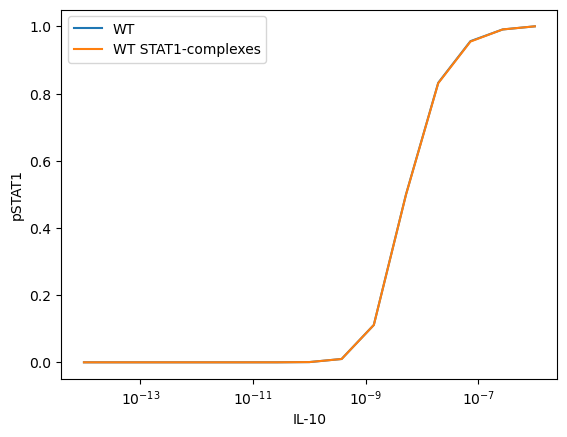

In [11]:
plt.plot(IL_10vec,STAT1_WT/max(STAT1_WT), label="WT")
plt.plot(IL_10vec,STAT1C_WT/max(STAT1C_WT), label="WT STAT1-complexes")
plt.legend(loc="best")
plt.xscale("log")
plt.xlabel("IL-10")
plt.ylabel("pSTAT1")

In [9]:
# Amount of nodes and edges correct
def model_func_simpl_bind(PA,IC):
    Na=6.023e23
    Width_PM = 1e-7 # In dm
    # Initialize model
    Model()
    
    # Compartment
    Compartment(name='EC', parent=None, dimension=3, size=None)
    Compartment(name='Cell_PM', parent=EC, dimension=2, size=None)
    Compartment(name='Cell_CP', parent=Cell_PM, dimension=3, size=None)
    
    # Monomers
    Monomer('ILM')
    Monomer('IL', ['bA1', 'bA2', 'bB1', 'bB2'])
    Monomer('RA', ['bA', 'bMSTAT1'])
    Monomer('RB', ['bB'])
    Monomer('M', ['bRA','bSTAT1'])
    Monomer('STAT1', ['b1','P'], {'P': ['u', 'p']})
    
    # Parameters
    Parameter('K_ILM_f', PA["k_ILM_f"]/(Na*PA["vol_EC"])*2)
    Parameter('K_ILM_b', PA["k_ILM_b"])
    
    Parameter('K_IL_RA_f', 2*PA["k_IL_RA_f"]/(Na*PA["vol_EC"]))
    Parameter('K_IL_RA_b', PA["k_IL_RA_b"])
    Parameter('K_IL_RB_f', 2*PA["k_IL_RB_f"]/(Na*PA["vol_EC"]))
    Parameter('K_IL_RB_b', PA["k_IL_RB_b"])
    
    Parameter('K_IL_RA2_f', PA["k_IL_RA_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RA2_b', PA["k_IL_RA_b"])
    Parameter('K_IL_RB2_f', PA["k_IL_RB_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RB2_b', PA["k_IL_RB_b"])
    Parameter('K_IL_RA_RB_f', PA["k_IL_RA_RB_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RA_RB_b', PA["k_IL_RA_RB_b"])
    
    Parameter('K_IL_RA2_2_f', PA["k_IL_RA_f"]/(Na*PA["surf_cell"]*Width_PM)*(1/2))
    Parameter('K_IL_RB2_2_f', PA["k_IL_RB_f"]/(Na*PA["surf_cell"]*Width_PM)*(1/2))
    
    Parameter('K_IL_RA2_3_b', PA["k_IL_RA_b"]*(1/2))
    Parameter('K_IL_RA_RB_3_b', PA["k_IL_RA_RB_b"]*(1/2))
    
    Parameter('K_IL_RA2_4_b', PA["k_IL_RA_b"]*2)
    Parameter('K_IL_RA_RB_4_b', PA["k_IL_RA_RB_b"]*2)
    
    Parameter('K_M_f', PA["k_M_f"]/(Na*PA["vol_cell"]))
    Parameter('K_M_b', PA["k_M_b"])
    Parameter('K_M_2_f', PA["k_M_f"]/(Na*PA["vol_cell"])*2)
    Parameter('K_M_3_f', PA["k_M_f"]/(Na*PA["vol_cell"])*(1/2))
    
    Parameter('K_STAT1_f', PA["k_STAT1_f"]/(Na*PA["vol_cell"]))
    Parameter('K_STAT1_b', PA["k_STAT1_b"])
    Parameter('K_STAT1_2_f', PA["k_STAT1_f"]/(Na*PA["vol_cell"])*2)
    Parameter('K_STAT1_3_f', PA["k_STAT1_f"]/(Na*PA["vol_cell"])*(1/2))
    
    # Complexes and reactions (binding of receptors)
    IL_free = IL(bA1=None, bA2=None, bB1=None, bB2=None)
    ILM_free = ILM()
    Rule('IL_binding', ILM_free + ILM_free | IL_free, *[K_ILM_f, K_ILM_b])
    
    IL_RA1_alone = IL(bA1=1, bA2=None, bB1=None, bB2=None) % RA(bA=1, bMSTAT1=None)
    Rule('IL_RA1_alone_binding', IL_free + RA(bA=None, bMSTAT1=None)| IL_RA1_alone, *[K_IL_RA_f, K_IL_RA_b])
    IL_RB1_alone = IL(bA1=None, bA2=None, bB1=1, bB2=None) % RB(bB=1)
    Rule('IL_RB1_alone_binding', IL_free + RB(bB=None)| IL_RB1_alone, *[K_IL_RB_f, K_IL_RB_b])
    
    # Binding of second receptors from IL-RA1 complex
    IL_RA1_RA2 = IL(bA1=1, bA2=2, bB1=None, bB2=None) % RA(bA=1, bMSTAT1=None) % RA(bA=2, bMSTAT1=None)
    Rule('IL_RA1_RA2_binding_DB', IL_RA1_alone + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2, *[K_IL_RA2_2_f, K_IL_RA2_b])
    IL_RA1_RB1 = IL(bA1=1, bA2=None, bB1=2, bB2=None) % RA(bA=1, bMSTAT1=None) % RB(bB=2)
    Rule('IL_RA1_RB1_binding_DB', IL_RA1_alone + RB(bB=None) | IL_RA1_RB1, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    IL_RA1_RB1_M1 = IL(bA1=1, bA2=None, bB1=2, bB2=None) % RA(bA=1, bMSTAT1=5) % RB(bB=2) % M(bRA=5, bSTAT1=None) 
    IL_RA1_RB1_MS1 = IL(bA1=1, bA2=None, bB1=2, bB2=None) % RA(bA=1, bMSTAT1=5) % RB(bB=2) % M(bRA=5, bSTAT1=6) % STAT1(b1=6, P='u')
    Rule('IL_RA1_RB1_unbinding_DB', IL_RA1_RB1_M1 >> IL_RA1_alone + RB(bB=None) + M(bRA=None, bSTAT1=None) , K_IL_RA_RB_b)
    Rule('IL_RA1_RB1_unbinding_DB2', IL_RA1_RB1_MS1 >> IL_RA1_alone + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    IL_RA1_RB2 = IL(bA1=1, bA2=None, bB1=None, bB2=2) % RA(bA=1, bMSTAT1=None) % RB(bB=2)
    Rule('IL_RA1_RB2_binding_DB', IL_RA1_alone + RB(bB=None) | IL_RA1_RB2, *[K_IL_RB2_f, K_IL_RB2_b])
    
    # Binding of second receptors from IL-RB1 complex
    Rule('IL_RB1_RA1_binding_DB', IL_RB1_alone + RA(bA=None, bMSTAT1=None) | IL_RA1_RB1, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RB1_RA1_unbinding_DB', IL_RA1_RB1_M1 >> IL_RB1_alone + RA(bA=None, bMSTAT1=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RB1_RA1_unbinding_DB2', IL_RA1_RB1_MS1 >> IL_RB1_alone + RA(bA=None, bMSTAT1=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    Rule('IL_RB2_RA1_binding_DB', IL_RB1_alone + RA(bA=None, bMSTAT1=None) | IL_RA1_RB2, *[K_IL_RA2_f, K_IL_RA2_b])  # IL-RA1-RB2 is the same complex as IL-RA2-RB1
    IL_RB1_RB2 = IL(bA1=None, bA2=None, bB1=1, bB2=2) % RB(bB=1) % RB(bB=2)
    Rule('IL_RB1_RB2_binding_DB', IL_RB1_alone + RB(bB=None) | IL_RB1_RB2, *[K_IL_RB2_2_f, K_IL_RB2_b])
    
    # Binding of third receptors to form IL-RA1-RA2-RB1 complex
    IL_RA1_RA2_RB1 = IL(bA1=1, bA2=2, bB1=3, bB2=None) % RA(bA=1, bMSTAT1=None) % RA(bA=2, bMSTAT1=None) % RB(bB=3)
    IL_RA1_RA2_RB1_M1 = IL(bA1=1, bA2=2, bB1=3, bB2=None) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % M(bRA=5, bSTAT1=None)
    IL_RA1_RA2_RB1_MS1 = IL(bA1=1, bA2=2, bB1=3, bB2=None) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % M(bRA=5, bSTAT1=6) % STAT1(b1=6, P='u')
    
    Rule('IL_RA1RA1_RB1_binding_TB', IL_RA1_RA2 + RB(bB=None) | IL_RA1_RA2_RB1, *[K_IL_RA_RB_f, K_IL_RA_RB_3_b])
    Rule('IL_RA1RA1_RB1_unbinding_TB', IL_RA1_RA2_RB1_M1 >> IL_RA1_RA2 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_3_b)
    Rule('IL_RA1RA1_RB1_unbinding_TB2', IL_RA1_RA2_RB1_MS1 >> IL_RA1_RA2 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_3_b)
    
    Rule('IL_RA1RB1_RA2_binding_TB', IL_RA1_RB1 + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2_RB1, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA1RB1_RA2_binding_TB2', IL_RA1_RB1_M1 + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2_RB1_M1, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA1RB1_RA2_binding_TB3', IL_RA1_RB1_MS1 + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2_RB1_MS1, *[K_IL_RA2_f, K_IL_RA2_b])
    
    Rule('IL_RA1RB2_RA2_binding_TB', IL_RA1_RB2 + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2_RB1, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA1RB2_RA2_unbinding_TB', IL_RA1_RA2_RB1_M1 >> IL_RA1_RB2 + RA(bA=None, bMSTAT1=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_b)
    Rule('IL_RA1RB2_RA2_unbinding_TB2', IL_RA1_RA2_RB1_MS1 >> IL_RA1_RB2 + RA(bA=None, bMSTAT1=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_b)
    
    # Binding of third receptors to form IL-RA1-RB1-RB2 complex
    IL_RA1_RB1_RB2 = IL(bA1=1, bA2=None, bB1=2, bB2=3) % RA(bA=1, bMSTAT1=None) % RB(bB=2) % RB(bB=3)
    IL_RA1_RB1_RB2_M1 = IL(bA1=1, bA2=None, bB1=2, bB2=3) % RA(bA=1, bMSTAT1=5) % RB(bB=2) % RB(bB=3) % M(bRA=5, bSTAT1=None)
    IL_RA1_RB1_RB2_MS1 = IL(bA1=1, bA2=None, bB1=2, bB2=3) % RA(bA=1, bMSTAT1=5) % RB(bB=2) % RB(bB=3) % M(bRA=5, bSTAT1=6) % STAT1(b1=6, P='u')
    Rule('IL_RA1RB1_RB2_binding_TB', IL_RA1_RB1 + RB(bB=None) | IL_RA1_RB1_RB2, *[K_IL_RB2_f, K_IL_RB2_b])
    Rule('IL_RA1RB1_RB2_binding_TB2', IL_RA1_RB1_M1 + RB(bB=None) | IL_RA1_RB1_RB2_M1, *[K_IL_RB2_f, K_IL_RB2_b])
    Rule('IL_RA1RB1_RB2_binding_TB3', IL_RA1_RB1_MS1 + RB(bB=None) | IL_RA1_RB1_RB2_MS1, *[K_IL_RB2_f, K_IL_RB2_b])
    
    Rule('IL_RA1RB2_RB1_binding_TB', IL_RA1_RB2 + RB(bB=None) | IL_RA1_RB1_RB2, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    Rule('IL_RA1RB2_RB1_unbinding_TB', IL_RA1_RB1_RB2_M1 >> IL_RA1_RB2 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_b)
    Rule('IL_RA1RB2_RB1_unbinding_TB2', IL_RA1_RB1_RB2_MS1 >> IL_RA1_RB2 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    
    Rule('IL_RB1RB2_RA2_binding_TB', IL_RB1_RB2 + RA(bA=None, bMSTAT1=None) | IL_RA1_RB1_RB2, *[K_IL_RA2_f, K_IL_RA2_3_b])
    Rule('IL_RB1RB2_RA2_unbinding_TB', IL_RA1_RB1_RB2_M1 >> IL_RB1_RB2 + RA(bA=None, bMSTAT1=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_3_b)
    Rule('IL_RB1RB2_RA2_unbinding_TB2', IL_RA1_RB1_RB2_MS1 >> IL_RB1_RB2 + RA(bA=None, bMSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_3_b)
           
    # Binding of fourth receptor
    IL_RA1_RA2_RB1_RB2 = IL(bA1=1, bA2=2, bB1=3, bB2=4) % RA(bA=1, bMSTAT1=None) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % RB(bB=4)
    IL_RA1_RA2_RB1_RB2_M1 = IL(bA1=1, bA2=2, bB1=3, bB2=4) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=None)
    IL_RA1_RA2_RB1_RB2_M1_M2 = IL(bA1=1, bA2=2, bB1=3, bB2=4) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=7) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=None) % M(bRA=7, bSTAT1=None)
    IL_RA1_RA2_RB1_RB2_MS1 = IL(bA1=1, bA2=2, bB1=3, bB2=4) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=6) % STAT1(b1=6, P='u')
    IL_RA1_RA2_RB1_RB2_MS1_M2 = IL(bA1=1, bA2=2, bB1=3, bB2=4) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=7) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=6) % STAT1(b1=6, P='u') % M(bRA=7, bSTAT1=None)
    IL_RA1_RA2_RB1_RB2_MS1_MS2 = IL(bA1=1, bA2=2, bB1=3, bB2=4) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=7) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=6) % STAT1(b1=6, P='u') % M(bRA=7, bSTAT1=8) % STAT1(b1=8, P='u')
        
    Rule('IL_RA1RA2RB1_RB2_binding_QB', IL_RA1_RA2_RB1 + RB(bB=None) | IL_RA1_RA2_RB1_RB2, *[K_IL_RA_RB_f, K_IL_RA_RB_4_b])
    Rule('IL_RA1RA2RB1_RB2_M1_binding_QB', IL_RA1_RA2_RB1_M1 + RB(bB=None) | IL_RA1_RA2_RB1_RB2_M1, *[K_IL_RA_RB_f, K_IL_RA_RB_4_b])
    Rule('IL_RA1RA2RB1_RB2_M1_unbinding_QB', IL_RA1_RA2_RB1_RB2_M1 >> IL_RA1_RA2_RB1 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_4_b)
    Rule('IL_RA1RA2RB1_RB2_M1_M2_unbinding_QB', IL_RA1_RA2_RB1_RB2_M1_M2 >> IL_RA1_RA2_RB1_M1 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_4_b)
    Rule('IL_RA1RA2RB1_RB2_MS1_binding_QB', IL_RA1_RA2_RB1_MS1 + RB(bB=None) | IL_RA1_RA2_RB1_RB2_MS1, *[K_IL_RA_RB_f, K_IL_RA_RB_4_b])
    Rule('IL_RA1RA2RB1_RB2_MS1_unbinding_QB', IL_RA1_RA2_RB1_RB2_MS1 >> IL_RA1_RA2_RB1 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_4_b)
    Rule('IL_RA1RA2RB1_RB2_MS1_M2_unbinding_QB1', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_RA1_RA2_RB1_M1 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_4_b)
    Rule('IL_RA1RA2RB1_RB2_MS1_M2_unbinding_QB2', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_RA1_RA2_RB1_MS1 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_4_b)
    Rule('IL_RA1RA2RB1_RB2_MS1_MS2_unbinding_QB', IL_RA1_RA2_RB1_RB2_MS1_MS2 >> IL_RA1_RA2_RB1_MS1 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_4_b)
    
    Rule('IL_RA1RB1RB2_RA2_binding_QB', IL_RA1_RB1_RB2 + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2_RB1_RB2, *[K_IL_RA2_f, K_IL_RA2_4_b])
    Rule('IL_RA1RB1RB2_RA2_M1_binding_QB', IL_RA1_RB1_RB2_M1 + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2_RB1_RB2_M1, *[K_IL_RA2_f, K_IL_RA2_4_b])
    Rule('IL_RA1RB1RB2_RA2_M1_unbinding_QB', IL_RA1_RA2_RB1_RB2_M1 >> IL_RA1_RB1_RB2 + RA(bA=None, bMSTAT1=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_4_b)
    Rule('IL_RA1RB1RB2_RA2_M1_M2_unbinding_QB', IL_RA1_RA2_RB1_RB2_M1_M2 >> IL_RA1_RB1_RB2_M1 + RA(bA=None, bMSTAT1=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_4_b)
    Rule('IL_RA1RB1RB2_RA2_MS1_binding_QB', IL_RA1_RB1_RB2_MS1 + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2_RB1_RB2_MS1, *[K_IL_RA2_f, K_IL_RA2_4_b])
    Rule('IL_RA1RB1RB2_RA2_MS1_unbinding_QB', IL_RA1_RA2_RB1_RB2_MS1 >> IL_RA1_RB1_RB2 + RA(bA=None, bMSTAT1=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_4_b)
    Rule('IL_RA1RB1RB2_RA2_MS1_M2_unbinding_QB1', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_RA1_RB1_RB2_M1 + RA(bA=None, bMSTAT1=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_4_b)
    Rule('IL_RA1RB1RB2_RA2_MS1_M2_unbinding_QB2', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_RA1_RB1_RB2_MS1 + RA(bA=None, bMSTAT1=None) + M(bRA=None, bSTAT1=None), K_IL_RA2_4_b)
    Rule('IL_RA1RB1RB2_RA2_MS1_MS2_unbinding_QB', IL_RA1_RA2_RB1_RB2_MS1_MS2 >> IL_RA1_RB1_RB2_MS1 + RA(bA=None, bMSTAT1=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA2_4_b)
    
    # Binding of M and STAT
    Rule('IL_RA1_RB1_M1_binding', IL_RA1_RB1 + M(bRA=None, bSTAT1=None) | IL_RA1_RB1_M1, *[K_M_f, K_M_b])
    Rule('IL_RA1_RB1_MS1_binding', IL_RA1_RB1_M1 + STAT1(b1=None, P='u') | IL_RA1_RB1_MS1, *[K_STAT1_f, K_STAT1_b])
    Rule('IL_RA1_RB1_MS1_unbinding', IL_RA1_RB1_MS1 >> IL_RA1_RB1 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    
    Rule('IL_RA1_RA2_RB1_M1_binding', IL_RA1_RA2_RB1 + M(bRA=None, bSTAT1=None) | IL_RA1_RA2_RB1_M1, *[K_M_f, K_M_b])
    Rule('IL_RA1_RA2_RB1_MS1_binding', IL_RA1_RA2_RB1_M1 + STAT1(b1=None, P='u') | IL_RA1_RA2_RB1_MS1, *[K_STAT1_f, K_STAT1_b])
    Rule('IL_RA1_RA2_RB1_MS1_unbinding', IL_RA1_RA2_RB1_MS1 >> IL_RA1_RA2_RB1 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    Rule('IL_RA1_RB1_RB2_M1_binding', IL_RA1_RB1_RB2 + M(bRA=None, bSTAT1=None) | IL_RA1_RB1_RB2_M1, *[K_M_f, K_M_b])
    Rule('IL_RA1_RB1_RB2_MS1_binding', IL_RA1_RB1_RB2_M1 + STAT1(b1=None, P='u') | IL_RA1_RB1_RB2_MS1, *[K_STAT1_f, K_STAT1_b])
    Rule('IL_RA1_RB1_RB2_MS1_unbinding', IL_RA1_RB1_RB2_MS1 >> IL_RA1_RB1_RB2 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    
    Rule('IL_IL_RA1_RA2_RB1_RB2_M1_binding', IL_RA1_RA2_RB1_RB2 + M(bRA=None, bSTAT1=None) | IL_RA1_RA2_RB1_RB2_M1, *[K_M_2_f, K_M_b])
    Rule('IL_IL_RA1_RA2_RB1_RB2_M1_M2_binding', IL_RA1_RA2_RB1_RB2_M1 + M(bRA=None, bSTAT1=None) | IL_RA1_RA2_RB1_RB2_M1_M2, *[K_M_3_f, K_M_b])
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_binding', IL_RA1_RA2_RB1_RB2_M1 + STAT1(b1=None, P='u') | IL_RA1_RA2_RB1_RB2_MS1, *[K_STAT1_f, K_STAT1_b])
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_unbinding', IL_RA1_RA2_RB1_RB2_MS1 >> IL_RA1_RA2_RB1_RB2 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_M2_binding1', IL_RA1_RA2_RB1_RB2_MS1 + M(bRA=None, bSTAT1=None) | IL_RA1_RA2_RB1_RB2_MS1_M2, *[K_M_3_f, K_M_b])
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_M2_binding2', IL_RA1_RA2_RB1_RB2_M1_M2 + STAT1(b1=None, P='u') | IL_RA1_RA2_RB1_RB2_MS1_M2, *[K_STAT1_2_f, K_STAT1_b])
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_M2_unbinding', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_RA1_RA2_RB1_RB2_M1 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_MS2_binding', IL_RA1_RA2_RB1_RB2_MS1_M2 + STAT1(b1=None, P='u') | IL_RA1_RA2_RB1_RB2_MS1_MS2, *[K_STAT1_3_f, K_STAT1_b])
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_MS2_unbinding', IL_RA1_RA2_RB1_RB2_MS1_MS2 >> IL_RA1_RA2_RB1_RB2_MS1 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    
    # Initial conditions
    Kd_IL = PA["k_ILM_b"]/(PA["k_ILM_f"]/(Na*PA["vol_EC"]))
    ILM_eq = (-Kd_IL/2 + (Kd_IL**2/4 + 2*Kd_IL*IC["IL0"]*Na*PA["vol_EC"])**(1/2))/2
    ILD_eq = (IC["IL0"]*Na*PA["vol_EC"]-ILM_eq)/2
    Parameter('ILM_0', ILM_eq)
    Initial(ILM() ** EC , ILM_0)
    Parameter('ILD_0', ILD_eq) #IC["IL0"]*Na*PA["vol_EC"])
    Initial(IL(bA1=None, bA2=None, bB1=None, bB2=None) ** EC, ILD_0)
    
    Parameter('RA_0',IC["RA0"])
    Parameter('RB_0',IC["RB0"])
    Initial(RA(bA=None, bMSTAT1=None) ** Cell_PM, RA_0)
    Initial(RB(bB=None) ** Cell_PM, RB_0)
    
    Parameter('STAT_1_0', IC["STAT10"])
    Initial(STAT1(b1=None, P='u') ** Cell_CP, STAT_1_0)
    Parameter('M_0', IC["M0"])
    Initial(M(bRA=None,bSTAT1=None) ** Cell_CP, M_0)
    
    # Simulation
    Observable('ILM_free', ILM() ** EC)
    Observable('IL_free', IL(bA1=None, bA2=None, bB1=None, bB2=None) ** EC)
    Observable('RA_free', RA(bA=None, bMSTAT1=None) ** Cell_PM)
    Observable('RB_free', RB(bB=None) ** Cell_PM)
    Observable('S1_free', STAT1(b1=None, P='u') ** Cell_CP)
    
    Observable('IL_RA1', IL(bA1=1, bA2=None, bB1=None, bB2=None) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM)
    Observable('IL_RB1', IL(bA1=None, bA2=None, bB1=1, bB2=None) ** EC % RB(bB=1) ** Cell_PM)
    
    Observable('IL_RA1_RA2', IL(bA1=1, bA2=2, bB1=None, bB2=None) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM)
    Observable('IL_RA1_RB1', IL(bA1=1, bA2=None, bB1=2, bB2=None) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM % RB(bB=2) ** Cell_PM)
    Observable('IL_RA1_RB2', IL(bA1=1, bA2=None, bB1=None, bB2=2) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM % RB(bB=2) ** Cell_PM)
    Observable('IL_RB1_RB2', IL(bA1=None, bA2=None, bB1=1, bB2=2) ** EC % RB(bB=1) ** Cell_PM % RB(bB=2) ** Cell_PM)
    
    Observable('IL_RA1_RA2_RB1', IL(bA1=1, bA2=2, bB1=3, bB2=None) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM)
    Observable('IL_RA1_RB1_RB2', IL(bA1=1, bA2=None, bB1=2, bB2=3) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM)
    
    Observable('IL_RA1_RA2_RB1_RB2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM)
    
    Observable('IL_RA1_RB1_P1', IL(bA1=1, bA2=None, bB1=2, bB2=None) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RB(bB=2) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RB1_PS1', IL(bA1=1, bA2=None, bB1=2, bB2=None) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RB(bB=2) ** Cell_PM % M(bRA=5, bSTAT1=6) ** Cell_CP % STAT1(b1=6, P='u') ** Cell_CP)
    
    Observable('IL_RA1_RA2_RB1_P1', IL(bA1=1, bA2=2, bB1=3, bB2=None) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_PS1', IL(bA1=1, bA2=2, bB1=3, bB2=None) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=6) ** Cell_CP % STAT1(b1=6, P='u') ** Cell_CP)
    Observable('IL_RA1_RB1_RB2_P1', IL(bA1=1, bA2=None, bB1=2, bB2=3) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RB1_RB2_PS1', IL(bA1=1, bA2=None, bB1=2, bB2=3) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RB(bB=2) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=6) ** Cell_CP % STAT1(b1=6, P='u') ** Cell_CP)
    
    Observable('IL_RA1_RA2_RB1_RB2_P1', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_P1_P2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=7) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP % M(bRA=7, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_PS1', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=6) ** Cell_CP % STAT1(b1=6, P='u') ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_PS1_P2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=7) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=6) ** Cell_CP % M(bRA=7, bSTAT1=None) ** Cell_CP % STAT1(b1=6, P='u') ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_PS1_PS2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=7) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=6) ** Cell_CP % M(bRA=7, bSTAT1=8) ** Cell_CP % STAT1(b1=6, P='u') ** Cell_CP % STAT1(b1=8, P='u') ** Cell_CP)
    
    dT, Tf = func_time(IC["IL0"])
    t = np.arange(0,Tf*5,dT/100)
    simulator = ScipyOdeSimulator(model, tspan=t, compiler='python', integrator = 'lsoda').run()
    return simulator.all

In [2]:
def func_time(IL10):
    if IL10 > 1e-7:
        return 0.1*5,1e4
    else:
        IL10 = abs(np.log10(IL10)) - 3
        return 10**(IL10)/(1e4)*5,10**(IL10)

PA={
    "vol_EC" : 1.0E-10, # In dm # OG: 1.0E-10
    "surf_cell" : 1.11545244e-07, # OG: 1.4e-08 Mut_noSOCS: 1.4e-7
    "vol_cell" : 3.0E-12, # In dm
    "k_ILM_f" : 6.97E+05,
    "k_ILM_b" : 3.07214605e+00, #4.34 # OG: 4.34e-02 Mut_noSOCS: 8.34e-02
    "k_IL_RA_f" : 6.97E+05,
    "k_IL_RA_b" : 5.94742574e-04, # OG: 1.42E-04 Mut_noSOCS: 1.42E-03
    "k_IL_RB_f" : 6.97E+05,
    "k_IL_RB_b" : 1394, # OG: 1394
    "k_IL_RA_RB_f" : 6.97E+05,
    "k_IL_RA_RB_b" : 1.32365577e+00, # OG: 243.95
    "k_STAT1_f" : 6.55E+06*10,
    "k_STAT1_b" : 0.678,
    "k_M_f" : 6.55E+06*1000,
    "k_M_b" : 0.678,
    "k_STAT3_f" : 6.55E+06*1000,
    "k_STAT3_b" : 0.678,
    "k_PHOS" : 3.16E-03,
    "k_DEPHOS" : 0.000664996232095083
}

IC = {
    "IL0":1e-7,
    "RA0":750,
    "RB0":2323,
    "STAT10" : 477858.2479731492,
    "M0" : 477858.2479731492,
    "STAT30" : 477858.2479731492
    }

In [11]:
IL_10vec = np.exp(np.linspace(np.log(1e-14), np.log(1e-6), 15))
STAT1C_full = []
STAT1C_simpl = []
for IL_10 in IL_10vec:
    IC = {
    "IL0":IL_10,
    "RA0":750,
    "RB0":4323,
    "STAT10" : 477858.2479731492,
    "M0" : 477858.2479731492,
    "STAT30" : 477858.2479731492
    }
    simulator = model_func_full_bind(PA,IC)
    STAT1C_full.append(simulator['IL_RA1_RB1_PS1'][-1]+simulator['IL_RA2_RB2_PS2'][-1]+simulator['IL_RA1_RA2_RB1_PS1'][-1]+simulator['IL_RA1_RA2_RB2_PS2'][-1]+simulator['IL_RA1_RB1_RB2_PS1'][-1]+simulator['IL_RA2_RB1_RB2_PS2'][-1]+simulator['IL_RA1_RA2_RB1_RB2_PS1'][-1]+simulator['IL_RA1_RA2_RB1_RB2_PS2'][-1]+simulator['IL_RA1_RA2_RB1_RB2_PS1_P2'][-1]+simulator['IL_RA1_RA2_RB1_RB2_P1_PS2'][-1]+simulator['IL_RA1_RA2_RB1_RB2_PS1_PS2'][-1]*2)
    del(simulator)
    simulator = model_func_simpl_bind(PA,IC)
    STAT1C_simpl.append(simulator['IL_RA1_RB1_PS1'][-1]+simulator['IL_RA1_RA2_RB1_PS1'][-1]+simulator['IL_RA1_RB1_RB2_PS1'][-1]+simulator['IL_RA1_RA2_RB1_RB2_PS1'][-1]+simulator['IL_RA1_RA2_RB1_RB2_PS1_P2'][-1]+2*simulator['IL_RA1_RA2_RB1_RB2_PS1_PS2'][-1])
    del(simulator)

Text(0, 0.5, 'pSTAT1')

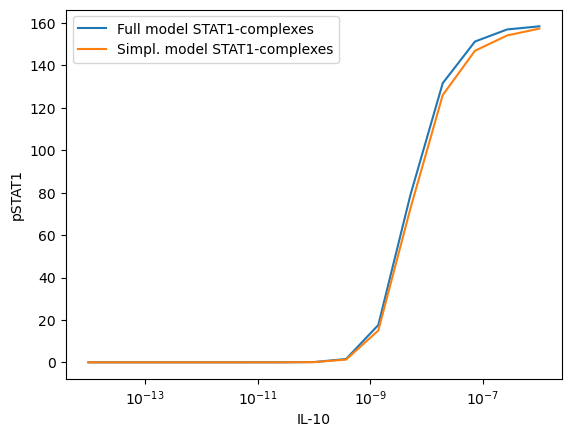

In [12]:
plt.plot(IL_10vec,STAT1C_full, label="Full model STAT1-complexes")
plt.plot(IL_10vec,STAT1C_simpl, label="Simpl. model STAT1-complexes")
plt.legend(loc="best")
plt.xscale("log")
plt.xlabel("IL-10")
plt.ylabel("pSTAT1")

In [11]:
# Amount of nodes and edges correct
def model_func_simpl2_bind(PA,IC):
    Na=6.023e23
    Width_PM = 1e-7 # In dm
    # Initialize model
    Model()
    
    # Compartment
    Compartment(name='EC', parent=None, dimension=3, size=None)
    Compartment(name='Cell_PM', parent=EC, dimension=2, size=None)
    Compartment(name='Cell_CP', parent=Cell_PM, dimension=3, size=None)
    
    # Monomers
    Monomer('ILM')
    Monomer('IL', ['bA1', 'bA2', 'bB1', 'bB2'])
    Monomer('RA', ['bA', 'bMSTAT1'])
    Monomer('RB', ['bB'])
    Monomer('M', ['bRA','bSTAT1'])
    Monomer('STAT1', ['b1','P'], {'P': ['u', 'p']})
    
    # Parameters
    Parameter('K_ILM_f', PA["k_ILM_f"]/(Na*PA["vol_EC"])*2)
    Parameter('K_ILM_b', PA["k_ILM_b"])
    
    Parameter('K_IL_RA_f', 2*PA["k_IL_RA_f"]/(Na*PA["vol_EC"]))
    Parameter('K_IL_RA_b', PA["k_IL_RA_b"])
    Parameter('K_IL_RB_f', 2*PA["k_IL_RB_f"]/(Na*PA["vol_EC"]))
    Parameter('K_IL_RB_b', PA["k_IL_RB_b"])
    
    Parameter('K_IL_RA2_f', PA["k_IL_RA_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RA2_b', PA["k_IL_RA_b"])
    Parameter('K_IL_RB2_f', PA["k_IL_RB_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RB2_b', PA["k_IL_RB_b"])
    Parameter('K_IL_RA_RB_f', PA["k_IL_RA_RB_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RA_RB_b', PA["k_IL_RA_RB_b"])
    
    Parameter('K_IL_RA2_2_f', PA["k_IL_RA_f"]/(Na*PA["surf_cell"]*Width_PM)*(1/2))
    Parameter('K_IL_RB2_2_f', PA["k_IL_RB_f"]/(Na*PA["surf_cell"]*Width_PM)*(1/2))
    
    Parameter('K_IL_RA2_3_b', PA["k_IL_RA_b"]*(1/2))
    Parameter('K_IL_RA_RB_3_b', PA["k_IL_RA_RB_b"]*(1/2))
    
    Parameter('K_IL_RA2_4_b', PA["k_IL_RA_b"]*2)
    Parameter('K_IL_RA_RB_4_b', PA["k_IL_RA_RB_b"]*2)
    
    Parameter('K_M_f', PA["k_M_f"]/(Na*PA["vol_cell"]))
    Parameter('K_M_b', PA["k_M_b"])
    Parameter('K_M_2_f', PA["k_M_f"]/(Na*PA["vol_cell"])*2)
    Parameter('K_M_3_f', PA["k_M_f"]/(Na*PA["vol_cell"])*(1/2))
    
    Parameter('K_STAT1_f', PA["k_STAT1_f"]/(Na*PA["vol_cell"]))
    Parameter('K_STAT1_b', PA["k_STAT1_b"])
    Parameter('K_STAT1_2_f', PA["k_STAT1_f"]/(Na*PA["vol_cell"])*2)
    Parameter('K_STAT1_3_f', PA["k_STAT1_f"]/(Na*PA["vol_cell"])*(1/2))
    
    # Complexes and reactions (binding of receptors)
    IL_free = IL(bA1=None, bA2=None, bB1=None, bB2=None)
    ILM_free = ILM()
    Rule('IL_binding', ILM_free + ILM_free | IL_free, *[K_ILM_f, K_ILM_b])
    
    IL_RA1_alone = IL(bA1=1, bA2=None, bB1=None, bB2=None) % RA(bA=1, bMSTAT1=None)
    Rule('IL_RA1_alone_binding', IL_free + RA(bA=None, bMSTAT1=None)| IL_RA1_alone, *[K_IL_RA_f, K_IL_RA_b])
    
    # Binding of second receptors from IL-RA1 complex
    IL_RA1_RA2 = IL(bA1=1, bA2=2, bB1=None, bB2=None) % RA(bA=1, bMSTAT1=None) % RA(bA=2, bMSTAT1=None)
    Rule('IL_RA1_RA2_binding_DB', IL_RA1_alone + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2, *[K_IL_RA2_2_f, K_IL_RA2_b])
    IL_RA1_RB1 = IL(bA1=1, bA2=None, bB1=2, bB2=None) % RA(bA=1, bMSTAT1=None) % RB(bB=2)
    Rule('IL_RA1_RB1_binding_DB', IL_RA1_alone + RB(bB=None) | IL_RA1_RB1, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    IL_RA1_RB1_M1 = IL(bA1=1, bA2=None, bB1=2, bB2=None) % RA(bA=1, bMSTAT1=5) % RB(bB=2) % M(bRA=5, bSTAT1=None) 
    IL_RA1_RB1_MS1 = IL(bA1=1, bA2=None, bB1=2, bB2=None) % RA(bA=1, bMSTAT1=5) % RB(bB=2) % M(bRA=5, bSTAT1=6) % STAT1(b1=6, P='u')
    Rule('IL_RA1_RB1_unbinding_DB', IL_RA1_RB1_M1 >> IL_RA1_alone + RB(bB=None) + M(bRA=None, bSTAT1=None) , K_IL_RA_RB_b)
    Rule('IL_RA1_RB1_unbinding_DB2', IL_RA1_RB1_MS1 >> IL_RA1_alone + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    
    # Binding of third receptors to form IL-RA1-RA2-RB1 complex
    IL_RA1_RA2_RB1 = IL(bA1=1, bA2=2, bB1=3, bB2=None) % RA(bA=1, bMSTAT1=None) % RA(bA=2, bMSTAT1=None) % RB(bB=3)
    IL_RA1_RA2_RB1_M1 = IL(bA1=1, bA2=2, bB1=3, bB2=None) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % M(bRA=5, bSTAT1=None)
    IL_RA1_RA2_RB1_MS1 = IL(bA1=1, bA2=2, bB1=3, bB2=None) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % M(bRA=5, bSTAT1=6) % STAT1(b1=6, P='u')
    
    Rule('IL_RA1RA1_RB1_binding_TB', IL_RA1_RA2 + RB(bB=None) | IL_RA1_RA2_RB1, *[K_IL_RA_RB_f, K_IL_RA_RB_3_b])
    Rule('IL_RA1RA1_RB1_unbinding_TB', IL_RA1_RA2_RB1_M1 >> IL_RA1_RA2 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_3_b)
    Rule('IL_RA1RA1_RB1_unbinding_TB2', IL_RA1_RA2_RB1_MS1 >> IL_RA1_RA2 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_3_b)
    
    Rule('IL_RA1RB1_RA2_binding_TB', IL_RA1_RB1 + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2_RB1, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA1RB1_RA2_binding_TB2', IL_RA1_RB1_M1 + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2_RB1_M1, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA1RB1_RA2_binding_TB3', IL_RA1_RB1_MS1 + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2_RB1_MS1, *[K_IL_RA2_f, K_IL_RA2_b])
    
           
    # Binding of fourth receptor
    IL_RA1_RA2_RB1_RB2 = IL(bA1=1, bA2=2, bB1=3, bB2=4) % RA(bA=1, bMSTAT1=None) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % RB(bB=4)
    IL_RA1_RA2_RB1_RB2_M1 = IL(bA1=1, bA2=2, bB1=3, bB2=4) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=None)
    IL_RA1_RA2_RB1_RB2_MS1 = IL(bA1=1, bA2=2, bB1=3, bB2=4) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=6) % STAT1(b1=6, P='u')
    #IL_RA1_RA2_RB1_RB2_MS1_M2 = IL(bA1=1, bA2=2, bB1=3, bB2=4) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=7) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=6) % STAT1(b1=6, P='u') % M(bRA=7, bSTAT1=None)
    #IL_RA1_RA2_RB1_RB2_MS1_MS2 = IL(bA1=1, bA2=2, bB1=3, bB2=4) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=7) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=6) % STAT1(b1=6, P='u') % M(bRA=7, bSTAT1=8) % STAT1(b1=8, P='u')
        
    Rule('IL_RA1RA2RB1_RB2_binding_QB', IL_RA1_RA2_RB1 + RB(bB=None) | IL_RA1_RA2_RB1_RB2, *[K_IL_RA_RB_f, K_IL_RA_RB_4_b])
    Rule('IL_RA1RA2RB1_RB2_M1_binding_QB', IL_RA1_RA2_RB1_M1 + RB(bB=None) | IL_RA1_RA2_RB1_RB2_M1, *[K_IL_RA_RB_f, K_IL_RA_RB_4_b])
    Rule('IL_RA1RA2RB1_RB2_M1_unbinding_QB', IL_RA1_RA2_RB1_RB2_M1 >> IL_RA1_RA2_RB1 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_4_b)
    Rule('IL_RA1RA2RB1_RB2_MS1_binding_QB', IL_RA1_RA2_RB1_MS1 + RB(bB=None) | IL_RA1_RA2_RB1_RB2_MS1, *[K_IL_RA_RB_f, K_IL_RA_RB_4_b])
    Rule('IL_RA1RA2RB1_RB2_MS1_unbinding_QB', IL_RA1_RA2_RB1_RB2_MS1 >> IL_RA1_RA2_RB1 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_4_b)
    #Rule('IL_RA1RA2RB1_RB2_MS1_M2_unbinding_QB1', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_RA1_RA2_RB1_M1 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_4_b)
    #Rule('IL_RA1RA2RB1_RB2_MS1_M2_unbinding_QB2', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_RA1_RA2_RB1_MS1 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_4_b)
    #Rule('IL_RA1RA2RB1_RB2_MS1_MS2_unbinding_QB', IL_RA1_RA2_RB1_RB2_MS1_MS2 >> IL_RA1_RA2_RB1_MS1 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_4_b)
    
    
    # Binding of M and STAT
    Rule('IL_RA1_RB1_M1_binding', IL_RA1_RB1 + M(bRA=None, bSTAT1=None) | IL_RA1_RB1_M1, *[K_M_f, K_M_b])
    Rule('IL_RA1_RB1_MS1_binding', IL_RA1_RB1_M1 + STAT1(b1=None, P='u') | IL_RA1_RB1_MS1, *[K_STAT1_f, K_STAT1_b])
    Rule('IL_RA1_RB1_MS1_unbinding', IL_RA1_RB1_MS1 >> IL_RA1_RB1 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    
    Rule('IL_RA1_RA2_RB1_M1_binding', IL_RA1_RA2_RB1 + M(bRA=None, bSTAT1=None) | IL_RA1_RA2_RB1_M1, *[K_M_f, K_M_b])
    Rule('IL_RA1_RA2_RB1_MS1_binding', IL_RA1_RA2_RB1_M1 + STAT1(b1=None, P='u') | IL_RA1_RA2_RB1_MS1, *[K_STAT1_f, K_STAT1_b])
    Rule('IL_RA1_RA2_RB1_MS1_unbinding', IL_RA1_RA2_RB1_MS1 >> IL_RA1_RA2_RB1 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    
    Rule('IL_IL_RA1_RA2_RB1_RB2_M1_binding', IL_RA1_RA2_RB1_RB2 + M(bRA=None, bSTAT1=None) | IL_RA1_RA2_RB1_RB2_M1, *[K_M_2_f, K_M_b])
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_binding', IL_RA1_RA2_RB1_RB2_M1 + STAT1(b1=None, P='u') | IL_RA1_RA2_RB1_RB2_MS1, *[K_STAT1_f, K_STAT1_b])
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_unbinding', IL_RA1_RA2_RB1_RB2_MS1 >> IL_RA1_RA2_RB1_RB2 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    """
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_M2_binding1', IL_RA1_RA2_RB1_RB2_MS1 + M(bRA=None, bSTAT1=None) | IL_RA1_RA2_RB1_RB2_MS1_M2, *[K_M_3_f, K_M_b])
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_M2_unbinding', IL_RA1_RA2_RB1_RB2_MS1_M2 >> IL_RA1_RA2_RB1_RB2_M1 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_MS2_binding', IL_RA1_RA2_RB1_RB2_MS1_M2 + STAT1(b1=None, P='u') | IL_RA1_RA2_RB1_RB2_MS1_MS2, *[K_STAT1_3_f, K_STAT1_b])
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_MS2_unbinding', IL_RA1_RA2_RB1_RB2_MS1_MS2 >> IL_RA1_RA2_RB1_RB2_MS1 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    """
    # Initial conditions
    Kd_IL = PA["k_ILM_b"]/(PA["k_ILM_f"]/(Na*PA["vol_EC"]))
    ILM_eq = (-Kd_IL/2 + (Kd_IL**2/4 + 2*Kd_IL*IC["IL0"]*Na*PA["vol_EC"])**(1/2))/2
    ILD_eq = (IC["IL0"]*Na*PA["vol_EC"]-ILM_eq)/2
    Parameter('ILM_0', ILM_eq)
    Initial(ILM() ** EC , ILM_0)
    Parameter('ILD_0', ILD_eq) #IC["IL0"]*Na*PA["vol_EC"])
    Initial(IL(bA1=None, bA2=None, bB1=None, bB2=None) ** EC, ILD_0)
    
    Parameter('RA_0',IC["RA0"])
    Parameter('RB_0',IC["RB0"])
    Initial(RA(bA=None, bMSTAT1=None) ** Cell_PM, RA_0)
    Initial(RB(bB=None) ** Cell_PM, RB_0)
    
    Parameter('STAT_1_0', IC["STAT10"])
    Initial(STAT1(b1=None, P='u') ** Cell_CP, STAT_1_0)
    Parameter('M_0', IC["M0"])
    Initial(M(bRA=None,bSTAT1=None) ** Cell_CP, M_0)
    
    # Simulation
    Observable('ILM_free', ILM() ** EC)
    Observable('IL_free', IL(bA1=None, bA2=None, bB1=None, bB2=None) ** EC)
    Observable('RA_free', RA(bA=None, bMSTAT1=None) ** Cell_PM)
    Observable('RB_free', RB(bB=None) ** Cell_PM)
    Observable('S1_free', STAT1(b1=None, P='u') ** Cell_CP)
    
    Observable('IL_RA1', IL(bA1=1, bA2=None, bB1=None, bB2=None) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM)
    
    Observable('IL_RA1_RA2', IL(bA1=1, bA2=2, bB1=None, bB2=None) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM)
    Observable('IL_RA1_RB1', IL(bA1=1, bA2=None, bB1=2, bB2=None) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM % RB(bB=2) ** Cell_PM)
    
    Observable('IL_RA1_RA2_RB1', IL(bA1=1, bA2=2, bB1=3, bB2=None) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM)
    
    Observable('IL_RA1_RA2_RB1_RB2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM)
    
    Observable('IL_RA1_RB1_P1', IL(bA1=1, bA2=None, bB1=2, bB2=None) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RB(bB=2) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RB1_PS1', IL(bA1=1, bA2=None, bB1=2, bB2=None) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RB(bB=2) ** Cell_PM % M(bRA=5, bSTAT1=6) ** Cell_CP % STAT1(b1=6, P='u') ** Cell_CP)
    
    Observable('IL_RA1_RA2_RB1_P1', IL(bA1=1, bA2=2, bB1=3, bB2=None) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_PS1', IL(bA1=1, bA2=2, bB1=3, bB2=None) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=6) ** Cell_CP % STAT1(b1=6, P='u') ** Cell_CP)
        
    Observable('IL_RA1_RA2_RB1_RB2_P1', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_PS1', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=6) ** Cell_CP % STAT1(b1=6, P='u') ** Cell_CP)
    #Observable('IL_RA1_RA2_RB1_RB2_PS1_P2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=7) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=6) ** Cell_CP % M(bRA=7, bSTAT1=None) ** Cell_CP % STAT1(b1=6, P='u') ** Cell_CP)
    #Observable('IL_RA1_RA2_RB1_RB2_PS1_PS2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=7) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=6) ** Cell_CP % M(bRA=7, bSTAT1=8) ** Cell_CP % STAT1(b1=6, P='u') ** Cell_CP % STAT1(b1=8, P='u') ** Cell_CP)
    
    dT, Tf = func_time(IC["IL0"])
    t = np.arange(0,Tf*5,dT/100)
    simulator = ScipyOdeSimulator(model, tspan=t, compiler='python', integrator = 'lsoda').run()
    return simulator.all

In [8]:
# Amount of nodes and edges correct
def model_func_simpl2_bind(PA,IC):
    Na=6.023e23
    Width_PM = 1e-7 # In dm
    # Initialize model
    Model()
    
    # Compartment
    Compartment(name='EC', parent=None, dimension=3, size=None)
    Compartment(name='Cell_PM', parent=EC, dimension=2, size=None)
    Compartment(name='Cell_CP', parent=Cell_PM, dimension=3, size=None)
    
    # Monomers
    Monomer('ILM')
    Monomer('IL', ['bA1', 'bA2', 'bB1', 'bB2'])
    Monomer('RA', ['bA', 'bMSTAT1'])
    Monomer('RB', ['bB'])
    Monomer('M', ['bRA','bSTAT1'])
    Monomer('STAT1', ['b1','P'], {'P': ['u', 'p']})
    
    # Parameters
    Parameter('K_ILM_f', PA["k_ILM_f"]/(Na*PA["vol_EC"])*2)
    Parameter('K_ILM_b', PA["k_ILM_b"])
    
    Parameter('K_IL_RA_f', 2*PA["k_IL_RA_f"]/(Na*PA["vol_EC"]))
    Parameter('K_IL_RA_b', PA["k_IL_RA_b"])
    Parameter('K_IL_RB_f', 2*PA["k_IL_RB_f"]/(Na*PA["vol_EC"]))
    Parameter('K_IL_RB_b', PA["k_IL_RB_b"])
    
    Parameter('K_IL_RA2_f', PA["k_IL_RA_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RA2_b', PA["k_IL_RA_b"])
    Parameter('K_IL_RB2_f', PA["k_IL_RB_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RB2_b', PA["k_IL_RB_b"])
    Parameter('K_IL_RA_RB_f', PA["k_IL_RA_RB_f"]/(Na*PA["surf_cell"]*Width_PM))
    Parameter('K_IL_RA_RB_b', PA["k_IL_RA_RB_b"])
    
    Parameter('K_IL_RA2_2_f', PA["k_IL_RA_f"]/(Na*PA["surf_cell"]*Width_PM)*(1/2))
    Parameter('K_IL_RB2_2_f', PA["k_IL_RB_f"]/(Na*PA["surf_cell"]*Width_PM)*(1/2))
    
    Parameter('K_IL_RA2_3_b', PA["k_IL_RA_b"]*(1/2))
    Parameter('K_IL_RA_RB_3_b', PA["k_IL_RA_RB_b"]*(1/2))
    
    Parameter('K_IL_RA2_4_b', PA["k_IL_RA_b"]*2)
    Parameter('K_IL_RA_RB_4_b', PA["k_IL_RA_RB_b"]*2)
    
    Parameter('K_M_f', PA["k_M_f"]/(Na*PA["vol_cell"]))
    Parameter('K_M_b', PA["k_M_b"])
    Parameter('K_M_2_f', PA["k_M_f"]/(Na*PA["vol_cell"])*2)
    Parameter('K_M_3_f', PA["k_M_f"]/(Na*PA["vol_cell"])*(1/2))
    
    Parameter('K_STAT1_f', PA["k_STAT1_f"]/(Na*PA["vol_cell"]))
    Parameter('K_STAT1_b', PA["k_STAT1_b"])
    Parameter('K_STAT1_2_f', PA["k_STAT1_f"]/(Na*PA["vol_cell"])*2)
    Parameter('K_STAT1_3_f', PA["k_STAT1_f"]/(Na*PA["vol_cell"])*(1/2))
    
    # Complexes and reactions (binding of receptors)
    IL_free = IL(bA1=None, bA2=None, bB1=None, bB2=None)
    ILM_free = ILM()
    Rule('IL_binding', ILM_free + ILM_free | IL_free, *[K_ILM_f, K_ILM_b])
    
    IL_RA1_alone = IL(bA1=1, bA2=None, bB1=None, bB2=None) % RA(bA=1, bMSTAT1=None)
    Rule('IL_RA1_alone_binding', IL_free + RA(bA=None, bMSTAT1=None)| IL_RA1_alone, *[K_IL_RA_f, K_IL_RA_b])
    
    # Binding of second receptors from IL-RA1 complex
    IL_RA1_RA2 = IL(bA1=1, bA2=2, bB1=None, bB2=None) % RA(bA=1, bMSTAT1=None) % RA(bA=2, bMSTAT1=None)
    Rule('IL_RA1_RA2_binding_DB', IL_RA1_alone + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2, *[K_IL_RA2_2_f, K_IL_RA2_b])
    IL_RA1_RB1 = IL(bA1=1, bA2=None, bB1=2, bB2=None) % RA(bA=1, bMSTAT1=None) % RB(bB=2)
    Rule('IL_RA1_RB1_binding_DB', IL_RA1_alone + RB(bB=None) | IL_RA1_RB1, *[K_IL_RA_RB_f, K_IL_RA_RB_b])
    IL_RA1_RB1_M1 = IL(bA1=1, bA2=None, bB1=2, bB2=None) % RA(bA=1, bMSTAT1=5) % RB(bB=2) % M(bRA=5, bSTAT1=None) 
    IL_RA1_RB1_MS1 = IL(bA1=1, bA2=None, bB1=2, bB2=None) % RA(bA=1, bMSTAT1=5) % RB(bB=2) % M(bRA=5, bSTAT1=6) % STAT1(b1=6, P='u')
    Rule('IL_RA1_RB1_unbinding_DB', IL_RA1_RB1_M1 >> IL_RA1_alone + RB(bB=None) + M(bRA=None, bSTAT1=None) , K_IL_RA_RB_b)
    Rule('IL_RA1_RB1_unbinding_DB2', IL_RA1_RB1_MS1 >> IL_RA1_alone + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_b)
    
    # Binding of third receptors to form IL-RA1-RA2-RB1 complex
    IL_RA1_RA2_RB1 = IL(bA1=1, bA2=2, bB1=3, bB2=None) % RA(bA=1, bMSTAT1=None) % RA(bA=2, bMSTAT1=None) % RB(bB=3)
    IL_RA1_RA2_RB1_M1 = IL(bA1=1, bA2=2, bB1=3, bB2=None) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % M(bRA=5, bSTAT1=None)
    IL_RA1_RA2_RB1_MS1 = IL(bA1=1, bA2=2, bB1=3, bB2=None) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % M(bRA=5, bSTAT1=6) % STAT1(b1=6, P='u')
    
    Rule('IL_RA1RA1_RB1_binding_TB', IL_RA1_RA2 + RB(bB=None) | IL_RA1_RA2_RB1, *[K_IL_RA_RB_f, K_IL_RA_RB_3_b])
    Rule('IL_RA1RA1_RB1_unbinding_TB', IL_RA1_RA2_RB1_M1 >> IL_RA1_RA2 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_3_b)
    Rule('IL_RA1RA1_RB1_unbinding_TB2', IL_RA1_RA2_RB1_MS1 >> IL_RA1_RA2 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_3_b)
    
    Rule('IL_RA1RB1_RA2_binding_TB', IL_RA1_RB1 + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2_RB1, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA1RB1_RA2_binding_TB2', IL_RA1_RB1_M1 + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2_RB1_M1, *[K_IL_RA2_f, K_IL_RA2_b])
    Rule('IL_RA1RB1_RA2_binding_TB3', IL_RA1_RB1_MS1 + RA(bA=None, bMSTAT1=None) | IL_RA1_RA2_RB1_MS1, *[K_IL_RA2_f, K_IL_RA2_b])
    
           
    # Binding of fourth receptor
    IL_RA1_RA2_RB1_RB2 = IL(bA1=1, bA2=2, bB1=3, bB2=4) % RA(bA=1, bMSTAT1=None) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % RB(bB=4)
    IL_RA1_RA2_RB1_RB2_M1 = IL(bA1=1, bA2=2, bB1=3, bB2=4) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=None)
    IL_RA1_RA2_RB1_RB2_MS1 = IL(bA1=1, bA2=2, bB1=3, bB2=4) % RA(bA=1, bMSTAT1=5) % RA(bA=2, bMSTAT1=None) % RB(bB=3) % RB(bB=4) % M(bRA=5, bSTAT1=6) % STAT1(b1=6, P='u')
        
    Rule('IL_RA1RA2RB1_RB2_binding_QB', IL_RA1_RA2_RB1 + RB(bB=None) | IL_RA1_RA2_RB1_RB2, *[K_IL_RA_RB_f, K_IL_RA_RB_4_b])
    Rule('IL_RA1RA2RB1_RB2_M1_binding_QB', IL_RA1_RA2_RB1_M1 + RB(bB=None) | IL_RA1_RA2_RB1_RB2_M1, *[K_IL_RA_RB_f, K_IL_RA_RB_4_b])
    Rule('IL_RA1RA2RB1_RB2_M1_unbinding_QB', IL_RA1_RA2_RB1_RB2_M1 >> IL_RA1_RA2_RB1 + RB(bB=None) + M(bRA=None, bSTAT1=None), K_IL_RA_RB_4_b)
    Rule('IL_RA1RA2RB1_RB2_MS1_binding_QB', IL_RA1_RA2_RB1_MS1 + RB(bB=None) | IL_RA1_RA2_RB1_RB2_MS1, *[K_IL_RA_RB_f, K_IL_RA_RB_4_b])
    Rule('IL_RA1RA2RB1_RB2_MS1_unbinding_QB', IL_RA1_RA2_RB1_RB2_MS1 >> IL_RA1_RA2_RB1 + RB(bB=None) + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_IL_RA_RB_4_b)
    
    # Binding of M and STAT
    Rule('IL_RA1_RB1_M1_binding', IL_RA1_RB1 + M(bRA=None, bSTAT1=None) | IL_RA1_RB1_M1, *[K_M_f, K_M_b])
    Rule('IL_RA1_RB1_MS1_binding', IL_RA1_RB1_M1 + STAT1(b1=None, P='u') | IL_RA1_RB1_MS1, *[K_STAT1_f, K_STAT1_b])
    Rule('IL_RA1_RB1_MS1_unbinding', IL_RA1_RB1_MS1 >> IL_RA1_RB1 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    
    Rule('IL_RA1_RA2_RB1_M1_binding', IL_RA1_RA2_RB1 + M(bRA=None, bSTAT1=None) | IL_RA1_RA2_RB1_M1, *[K_M_f, K_M_b])
    Rule('IL_RA1_RA2_RB1_MS1_binding', IL_RA1_RA2_RB1_M1 + STAT1(b1=None, P='u') | IL_RA1_RA2_RB1_MS1, *[K_STAT1_f, K_STAT1_b])
    Rule('IL_RA1_RA2_RB1_MS1_unbinding', IL_RA1_RA2_RB1_MS1 >> IL_RA1_RA2_RB1 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    
    Rule('IL_IL_RA1_RA2_RB1_RB2_M1_binding', IL_RA1_RA2_RB1_RB2 + M(bRA=None, bSTAT1=None) | IL_RA1_RA2_RB1_RB2_M1, *[K_M_2_f, K_M_b])
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_binding', IL_RA1_RA2_RB1_RB2_M1 + STAT1(b1=None, P='u') | IL_RA1_RA2_RB1_RB2_MS1, *[K_STAT1_f, K_STAT1_b])
    Rule('IL_IL_RA1_RA2_RB1_RB2_MS1_unbinding', IL_RA1_RA2_RB1_RB2_MS1 >> IL_RA1_RA2_RB1_RB2 + M(bRA=None, bSTAT1=None) + STAT1(b1=None, P='u'), K_M_b)
    
    # Initial conditions
    Kd_IL = PA["k_ILM_b"]/(PA["k_ILM_f"]/(Na*PA["vol_EC"]))
    ILM_eq = (-Kd_IL/2 + (Kd_IL**2/4 + 2*Kd_IL*IC["IL0"]*Na*PA["vol_EC"])**(1/2))/2
    ILD_eq = (IC["IL0"]*Na*PA["vol_EC"]-ILM_eq)/2
    Parameter('ILM_0', ILM_eq)
    Initial(ILM() ** EC , ILM_0)
    Parameter('ILD_0', ILD_eq)
    Initial(IL(bA1=None, bA2=None, bB1=None, bB2=None) ** EC, ILD_0)
    
    Parameter('RA_0',IC["RA0"])
    Parameter('RB_0',IC["RB0"])
    Initial(RA(bA=None, bMSTAT1=None) ** Cell_PM, RA_0)
    Initial(RB(bB=None) ** Cell_PM, RB_0)
    
    Parameter('STAT_1_0', IC["STAT10"])
    Initial(STAT1(b1=None, P='u') ** Cell_CP, STAT_1_0)
    Parameter('M_0', IC["M0"])
    Initial(M(bRA=None,bSTAT1=None) ** Cell_CP, M_0)
    
    # Simulation
    Observable('ILM_free', ILM() ** EC)
    Observable('IL_free', IL(bA1=None, bA2=None, bB1=None, bB2=None) ** EC)
    Observable('RA_free', RA(bA=None, bMSTAT1=None) ** Cell_PM)
    Observable('RB_free', RB(bB=None) ** Cell_PM)
    Observable('S1_free', STAT1(b1=None, P='u') ** Cell_CP)
    
    Observable('IL_RA1', IL(bA1=1, bA2=None, bB1=None, bB2=None) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM)
    
    Observable('IL_RA1_RA2', IL(bA1=1, bA2=2, bB1=None, bB2=None) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM)
    Observable('IL_RA1_RB1', IL(bA1=1, bA2=None, bB1=2, bB2=None) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM % RB(bB=2) ** Cell_PM)
    
    Observable('IL_RA1_RA2_RB1', IL(bA1=1, bA2=2, bB1=3, bB2=None) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM)
    
    Observable('IL_RA1_RA2_RB1_RB2', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bMSTAT1=None) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM)
    
    Observable('IL_RA1_RB1_P1', IL(bA1=1, bA2=None, bB1=2, bB2=None) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RB(bB=2) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RB1_PS1', IL(bA1=1, bA2=None, bB1=2, bB2=None) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RB(bB=2) ** Cell_PM % M(bRA=5, bSTAT1=6) ** Cell_CP % STAT1(b1=6, P='u') ** Cell_CP)
    
    Observable('IL_RA1_RA2_RB1_P1', IL(bA1=1, bA2=2, bB1=3, bB2=None) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_PS1', IL(bA1=1, bA2=2, bB1=3, bB2=None) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % M(bRA=5, bSTAT1=6) ** Cell_CP % STAT1(b1=6, P='u') ** Cell_CP)
        
    Observable('IL_RA1_RA2_RB1_RB2_P1', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=None) ** Cell_CP)
    Observable('IL_RA1_RA2_RB1_RB2_PS1', IL(bA1=1, bA2=2, bB1=3, bB2=4) ** EC % RA(bA=1, bMSTAT1=5) ** Cell_PM % RA(bA=2, bMSTAT1=None) ** Cell_PM % RB(bB=3) ** Cell_PM % RB(bB=4) ** Cell_PM % M(bRA=5, bSTAT1=6) ** Cell_CP % STAT1(b1=6, P='u') ** Cell_CP)
    dT, Tf = func_time(IC["IL0"])
    t = np.arange(0,Tf*5,dT/100)
    simulator = ScipyOdeSimulator(model, tspan=t, compiler='python', integrator = 'lsoda').run()
    return simulator.all

In [9]:
IL_10vec = np.exp(np.linspace(np.log(1e-14), np.log(1e-5), 15))
STAT1C_full = []
STAT1C_simpl = []
for IL_10 in IL_10vec:
    IC = {
    "IL0":IL_10,
    "RA0":750,
    "RB0":4323,
    "STAT10" : 477858.2479731492,
    "M0" : 477858.2479731492,
    "STAT30" : 477858.2479731492
    }
    simulator = model_func_full_bind(PA,IC)
    STAT1C_full.append(simulator['IL_RA1_RB1_PS1'][-1]+simulator['IL_RA2_RB2_PS2'][-1]+simulator['IL_RA1_RA2_RB1_PS1'][-1]+simulator['IL_RA1_RA2_RB2_PS2'][-1]+simulator['IL_RA1_RB1_RB2_PS1'][-1]+simulator['IL_RA2_RB1_RB2_PS2'][-1]+simulator['IL_RA1_RA2_RB1_RB2_PS1'][-1]+simulator['IL_RA1_RA2_RB1_RB2_PS2'][-1]+simulator['IL_RA1_RA2_RB1_RB2_PS1_P2'][-1]+simulator['IL_RA1_RA2_RB1_RB2_P1_PS2'][-1]+simulator['IL_RA1_RA2_RB1_RB2_PS1_PS2'][-1]*2)
    del(simulator)
    simulator = model_func_simpl2_bind(PA,IC)
    STAT1C_simpl.append(simulator['IL_RA1_RB1_PS1'][-1]+simulator['IL_RA1_RA2_RB1_PS1'][-1]+2*simulator['IL_RA1_RA2_RB1_RB2_PS1'][-1]) #+simulator['IL_RA1_RA2_RB1_RB2_PS1_P2'][-1]+2*simulator['IL_RA1_RA2_RB1_RB2_PS1_PS2'][-1])
    del(simulator)

Text(0, 0.5, 'pSTAT3')

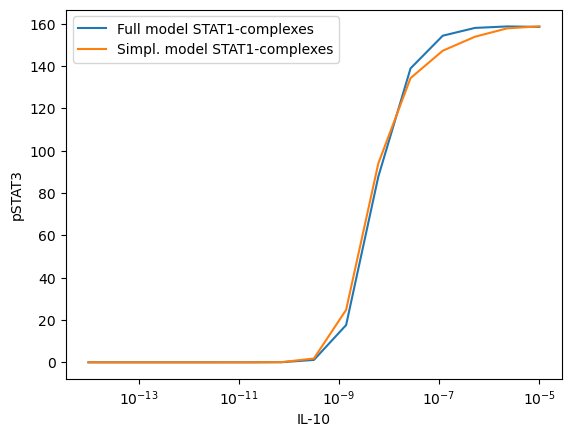

In [10]:
plt.plot(IL_10vec,STAT1C_full, label="Full model STAT1-complexes")
plt.plot(IL_10vec,STAT1C_simpl, label="Simpl. model STAT1-complexes")
plt.legend(loc="best")
plt.xscale("log")
plt.xlabel("IL-10")
plt.ylabel("pSTAT3")

At binding rates around 10/100 times higher than WT measured values the simplified model still behaves very similar to the non-simplified one -> We use it to find the SS 

In [ ]:
def simulate_model_STAT1(PA,IC):
    def STAT1_model(x):
        RA = x[0]
        RB = x[1]
        M = x[2]
        S1 = x[3]
        IL10M = x[4]
        
        RA_expr = -IL10M0*(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_f*RA*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 104*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 544*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 492*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 668*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 440*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 304*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 680*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 180*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 220*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 72*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 168*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 138*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 202*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 60*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 720*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 960*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 1008*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 800*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 816*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 672*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 648*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 1016*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 136*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 566*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 696*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 718*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 414*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 792*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1064*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 520*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 342*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 644*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 640*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 406*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 536*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 40*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 160*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 128*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 60*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 34*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 50*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 20*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 192*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 212*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 52*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 416*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 340*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 245*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 349*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 141*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 284*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 78*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 154*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 346*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 146*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 110*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 148*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 36*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 84*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 272*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 128*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 684*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 500*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 380*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 448*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 504*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 368*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 156*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 288*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 686*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 904*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 966*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 207*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 394*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 227*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 708*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 376*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 211*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 255*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 244*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 276*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 352*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 228*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 628*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 996*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 368*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 74*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 380*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 230*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 250*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 200*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 104*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 20*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 64*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 88*K_IL_RA_RB_b**5*K_M_b + 48*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 36*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 296*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 169*K_IL_RA_RB_b**4*K_M_b**2 + 196*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 205*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 133*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 52*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 272*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 478*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 608*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 594*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 362*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 133*K_IL_RA_RB_b**3*K_M_b**3 + 262*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 248*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 151*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 394*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 246*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 123*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 149*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 156*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 300*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 204*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 612*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 366*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1072*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 440*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 40*K_IL_RA_RB_b**2*K_M_b**4 + 134*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 98*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 62*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 292*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 178*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 76*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 98*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 182*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 226*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 124*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 360*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 600*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 304*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 136*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 672*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 408*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 536*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 20*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 40*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1008*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1080*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 740*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1048*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 920*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1680*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1432*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1968*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 960*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 944*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1504*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 344*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 348*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 536*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 490*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 456*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 246*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 92*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 112*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 524*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1180*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 868*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 800*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1480*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 336*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 632*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 626*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 940*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 632*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 728*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1096*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 620*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 48*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 244*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 784*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 458*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 136*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 264*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 672*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 752*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 396*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 628*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 176*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 840*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1616*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 384*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 154*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 484*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 272*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 752*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 344*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 576*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_f*RA**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3) + 4*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 4*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA**2*RB*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 96*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 36*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 52*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 20*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**3 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 4*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 56*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 384*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 360*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 304*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 228*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 84*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 356*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**4 + 36*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 20*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 88*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 20*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 68*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 84*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 168*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 92*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 69*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 101*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 37*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 18*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 30*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 6*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 344*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 386*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 542*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 230*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 172*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 258*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 366*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 150*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 116*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 119*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 234*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 123*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 532*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 139*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 212*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 44*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 38*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 34*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 50*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 54*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 4*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 68*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 102*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 126*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**5 + 176*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 280*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 196*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 492*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 349*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 473*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 225*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 340*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 132*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 140*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 156*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 456*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 200*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 191*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 370*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 652*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 239*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 36*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 260*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 108*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 140*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 76*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 46*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 70*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 360*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 210*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 90*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 50*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 40*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 152*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 44*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 140*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**5 + 20*K_IL_RA2_b*K_M_b**4*K_M_f*M + 12*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 40*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 26*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 17*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 25*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 9*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 6*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 10*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 2*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**3*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 28*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 174*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 131*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 180*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 187*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 75*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 158*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 162*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 62*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 138*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 58*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 113*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 79*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 41*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 181*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 77*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 47*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 9*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 38*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 14*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 66*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 22*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 2*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**4*RA**2 + 18*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 10*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 44*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 10*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 34*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 42*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 410*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 227*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 268*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 315*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 139*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 390*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 460*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 542*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 380*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 114*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 258*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 222*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 124*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 100*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 258*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 470*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 178*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 25*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 89*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 38*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 202*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 49*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 13*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 137*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 166*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 29*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 50*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 30*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 6*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 90*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**5*RA + 10*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 6*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 30*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 30*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 56*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**5*K_M_b + 32*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 56*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 222*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 104*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 154*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 113*K_IL_RA_RB_b**4*K_M_b**2 + 124*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 153*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 73*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 48*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 88*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 316*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 342*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 422*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 210*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 282*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 130*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 76*K_IL_RA_RB_b**3*K_M_b**3 + 153*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 147*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 81*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 241*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 121*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 79*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 92*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 13*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 20*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 196*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 252*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 194*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 206*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 588*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 202*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 234*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 214*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 21*K_IL_RA_RB_b**2*K_M_b**4 + 71*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 52*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 32*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 158*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 92*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 41*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 11*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 103*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 124*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 21*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 172*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 220*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 156*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 348*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 204*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 228*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 276*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**5 + 10*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 6*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 30*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 30*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 12*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 28*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 28*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 4*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 44*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 12*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**5*RB + 20*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 12*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 60*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 60*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA**2*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 912*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 704*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1092*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 472*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 508*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 744*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1072*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1460*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 496*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 304*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1020*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 734*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1036*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 204*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 160*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1496*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1300*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 560*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1832*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1000*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 888*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1392*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 340*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1080*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 136*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 496*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 308*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 516*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 473*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 436*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 244*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 340*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 428*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1044*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 794*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1386*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 320*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 584*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 605*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 228*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 866*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 576*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 696*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 284*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1032*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 188*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 608*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 124*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 104*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 384*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 32*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 188*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 160*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 636*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 401*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 84*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 592*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1150*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 276*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 377*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 148*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 558*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 748*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 938*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1428*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 280*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 152*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 96*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 472*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 380*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 648*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1056*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 24*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 160*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*M*RA**2*RB**2*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 56*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 8*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 236*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 172*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 132*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 168*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 204*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 248*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 312*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 24*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 120*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 76*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 126*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 492*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 340*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 430*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 540*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 142*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 174*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 316*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 72*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 72*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**5 + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 354*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 438*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 206*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 148*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 234*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 226*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 274*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 158*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 16*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 20*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 35*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 27*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 129*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 93*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 206*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 146*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 142*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 179*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 89*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 45*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 53*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 24*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 153*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 105*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 364*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 244*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 252*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 164*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 408*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 514*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 138*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 170*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 143*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 254*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 262*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 135*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 123*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 87*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 95*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 240*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 216*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 52*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 8*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA_RB_b**6 + 44*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 59*K_IL_RA_RB_b**5*K_M_b + 20*K_IL_RA_RB_b**5*K_M_f*M + 39*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 190*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 122*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 106*K_IL_RA_RB_b**4*K_M_b**2 + 81*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 131*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 81*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 65*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 28*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 33*K_IL_RA_RB_b**4*K_STAT1_b**2 + 41*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 100*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 374*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 186*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 87*K_IL_RA_RB_b**3*K_M_b**3 + 107*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 154*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 107*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 162*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 91*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 73*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 99*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 55*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 63*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 6*K_IL_RA_RB_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 124*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 80*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 76*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 222*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 412*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 254*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 142*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 166*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_b**2*K_M_b**4 + 54*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 74*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 118*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 76*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 74*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 74*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 100*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 8*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*RA**2*RB**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 8*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 24*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 64*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 582*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 712*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 446*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 668*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 464*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 16*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 4*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 12*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 40*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 534*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 261*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 378*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 260*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 8*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 16*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 96*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 320*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 203*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 566*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 181*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 340*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 438*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 716*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 66*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 220*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 8*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 80*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 16*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3))/(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_f*RA*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 104*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 544*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 492*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 668*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 440*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 304*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 680*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 180*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 220*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 72*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 168*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 138*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 202*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 60*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 720*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 960*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 1008*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 800*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 816*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 672*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 648*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 1016*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 136*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 566*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 696*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 718*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 414*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 792*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1064*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 520*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 342*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 644*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 640*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 406*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 536*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 40*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 160*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 128*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 60*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 34*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 50*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 20*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 192*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 212*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 52*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 416*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 340*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 245*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 349*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 141*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 284*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 78*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 154*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 346*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 146*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 110*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 148*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 36*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 84*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 272*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 128*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 684*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 500*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 380*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 448*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 504*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 368*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 156*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 288*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 686*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 904*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 966*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 207*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 394*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 227*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 708*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 376*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 211*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 255*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 244*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 276*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 352*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 228*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 628*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 996*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 368*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 74*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 380*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 230*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 250*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 200*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 104*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 20*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 64*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 88*K_IL_RA_RB_b**5*K_M_b + 48*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 36*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 296*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 169*K_IL_RA_RB_b**4*K_M_b**2 + 196*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 205*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 133*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 52*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 272*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 478*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 608*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 594*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 362*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 133*K_IL_RA_RB_b**3*K_M_b**3 + 262*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 248*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 151*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 394*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 246*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 123*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 149*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 156*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 300*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 204*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 612*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 366*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1072*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 440*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 40*K_IL_RA_RB_b**2*K_M_b**4 + 134*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 98*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 62*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 292*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 178*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 76*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 98*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 182*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 226*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 124*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 360*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 600*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 304*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 136*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 672*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 408*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 536*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 20*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 40*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1008*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1080*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 740*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1048*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 920*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1680*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1432*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1968*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 960*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 944*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1504*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 344*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 348*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 536*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 490*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 456*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 246*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 92*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 112*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 524*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1180*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 868*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 800*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1480*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 336*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 632*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 626*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 940*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 632*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 728*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1096*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 620*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 48*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 244*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 784*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 458*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 136*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 264*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 672*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 752*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 396*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 628*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 176*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 840*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1616*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 384*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 154*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 484*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 272*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 752*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 344*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 576*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_f*RA**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA**2*RB*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 96*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 36*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 52*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 20*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**3 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 4*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 56*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 384*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 360*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 304*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 228*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 84*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 356*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**4 + 36*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 20*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 88*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 20*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 68*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 84*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 168*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 92*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 69*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 101*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 37*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 18*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 30*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 6*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 344*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 386*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 542*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 230*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 172*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 258*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 366*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 150*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 116*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 119*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 234*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 123*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 532*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 139*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 212*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 44*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 38*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 34*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 50*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 54*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 4*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 68*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 102*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 126*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**5 + 176*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 280*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 196*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 492*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 349*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 473*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 225*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 340*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 132*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 140*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 156*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 456*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 200*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 191*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 370*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 652*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 239*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 36*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 260*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 108*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 140*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 76*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 46*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 70*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 360*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 210*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 90*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 50*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 40*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 152*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 44*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 140*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**5 + 20*K_IL_RA2_b*K_M_b**4*K_M_f*M + 12*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 40*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 26*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 17*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 25*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 9*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 6*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 10*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 2*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**3*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 28*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 174*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 131*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 180*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 187*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 75*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 158*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 162*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 62*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 138*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 58*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 113*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 79*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 41*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 181*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 77*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 47*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 9*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 38*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 14*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 66*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 22*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 2*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**4*RA**2 + 18*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 10*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 44*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 10*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 34*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 42*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 410*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 227*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 268*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 315*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 139*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 390*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 460*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 542*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 380*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 114*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 258*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 222*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 124*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 100*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 258*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 470*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 178*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 25*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 89*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 38*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 202*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 49*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 13*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 137*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 166*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 29*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 50*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 30*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 6*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 90*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**5*RA + 10*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 6*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 30*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 30*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 56*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**5*K_M_b + 32*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 56*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 222*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 104*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 154*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 113*K_IL_RA_RB_b**4*K_M_b**2 + 124*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 153*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 73*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 48*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 88*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 316*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 342*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 422*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 210*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 282*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 130*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 76*K_IL_RA_RB_b**3*K_M_b**3 + 153*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 147*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 81*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 241*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 121*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 79*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 92*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 13*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 20*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 196*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 252*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 194*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 206*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 588*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 202*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 234*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 214*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 21*K_IL_RA_RB_b**2*K_M_b**4 + 71*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 52*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 32*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 158*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 92*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 41*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 11*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 103*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 124*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 21*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 172*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 220*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 156*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 348*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 204*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 228*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 276*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**5 + 10*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 6*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 30*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 30*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 12*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 28*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 28*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 4*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 44*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 12*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**5*RB + 20*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 12*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 60*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 60*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA**2*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 912*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 704*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1092*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 472*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 508*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 744*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1072*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1460*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 496*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 304*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1020*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 734*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1036*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 204*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 160*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1496*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1300*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 560*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1832*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1000*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 888*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1392*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 340*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1080*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 136*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 496*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 308*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 516*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 473*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 436*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 244*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 340*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 428*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1044*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 794*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1386*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 320*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 584*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 605*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 228*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 866*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 576*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 696*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 284*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1032*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 188*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 608*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 124*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 104*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 384*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 32*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 188*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 160*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 636*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 401*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 84*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 592*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1150*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 276*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 377*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 148*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 558*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 748*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 938*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1428*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 280*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 152*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 96*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 472*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 380*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 648*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1056*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 24*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 160*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*M*RA**2*RB**2*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 56*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 8*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 236*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 172*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 132*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 168*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 204*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 248*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 312*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 24*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 120*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 76*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 126*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 492*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 340*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 430*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 540*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 142*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 174*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 316*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 72*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 72*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**5 + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 354*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 438*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 206*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 148*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 234*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 226*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 274*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 158*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 16*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 20*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 35*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 27*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 129*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 93*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 206*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 146*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 142*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 179*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 89*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 45*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 53*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 24*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 153*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 105*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 364*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 244*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 252*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 164*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 408*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 514*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 138*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 170*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 143*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 254*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 262*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 135*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 123*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 87*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 95*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 240*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 216*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 52*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 8*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA_RB_b**6 + 44*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 59*K_IL_RA_RB_b**5*K_M_b + 20*K_IL_RA_RB_b**5*K_M_f*M + 39*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 190*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 122*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 106*K_IL_RA_RB_b**4*K_M_b**2 + 81*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 131*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 81*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 65*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 28*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 33*K_IL_RA_RB_b**4*K_STAT1_b**2 + 41*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 100*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 374*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 186*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 87*K_IL_RA_RB_b**3*K_M_b**3 + 107*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 154*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 107*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 162*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 91*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 73*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 99*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 55*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 63*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 6*K_IL_RA_RB_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 124*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 80*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 76*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 222*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 412*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 254*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 142*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 166*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_b**2*K_M_b**4 + 54*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 74*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 118*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 76*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 74*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 74*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 100*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 8*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*RA**2*RB**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 8*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 24*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 64*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 582*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 712*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 446*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 668*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 464*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 16*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 4*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 12*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 40*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 534*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 261*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 378*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 260*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 8*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 16*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 96*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 320*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 203*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 566*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 181*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 340*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 438*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 716*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 66*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 220*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 8*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 80*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 16*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3)/2 + K_ILM_b*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2) - RA + RA0
        RB_expr = -IL10M0*(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 104*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 544*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 492*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 668*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 440*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 304*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 680*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 180*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 220*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 72*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 168*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 138*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 202*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 60*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 720*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 960*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 1008*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 800*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 816*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 672*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 648*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 1016*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 136*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 566*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 696*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 718*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 414*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 792*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1064*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 520*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 342*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 644*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 640*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 406*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 536*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 40*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 160*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 128*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 60*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 34*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 50*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 20*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 192*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 212*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 52*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 416*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 340*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 245*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 349*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 141*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 284*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 78*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 154*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 346*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 146*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 110*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 148*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 36*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 84*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 272*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 128*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 684*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 500*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 380*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 448*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 504*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 368*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 156*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 288*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 686*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 904*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 966*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 207*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 394*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 227*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 708*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 376*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 211*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 255*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 244*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 276*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 352*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 228*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 628*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 996*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 368*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 74*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 380*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 230*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 250*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 200*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 104*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 20*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 64*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 88*K_IL_RA_RB_b**5*K_M_b + 48*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 36*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 296*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 169*K_IL_RA_RB_b**4*K_M_b**2 + 196*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 205*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 133*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 52*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 272*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 478*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 608*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 594*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 362*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 133*K_IL_RA_RB_b**3*K_M_b**3 + 262*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 248*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 151*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 394*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 246*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 123*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 149*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 156*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 300*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 204*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 612*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 366*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1072*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 440*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 40*K_IL_RA_RB_b**2*K_M_b**4 + 134*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 98*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 62*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 292*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 178*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 76*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 98*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 182*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 226*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 124*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 360*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 600*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 304*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 136*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 672*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 408*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 536*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 20*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 40*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1008*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1080*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 740*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1048*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 920*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1680*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1432*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1968*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 960*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 944*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1504*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 344*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 348*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 536*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 490*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 456*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 246*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 92*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 112*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 524*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1180*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 868*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 800*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1480*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 336*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 632*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 626*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 940*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 632*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 728*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1096*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 620*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 48*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 244*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 784*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 458*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 136*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 264*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 672*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 752*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 396*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 628*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 176*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 840*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1616*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 384*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 154*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 484*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 272*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 752*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 344*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 576*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA**2*RB*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 96*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 36*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 52*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 20*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**3 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 4*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 56*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 384*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 360*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 304*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 228*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 84*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 356*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**4 + 36*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 20*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 88*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 20*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 68*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 84*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 168*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 92*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 69*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 101*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 37*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 18*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 30*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 6*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 344*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 386*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 542*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 230*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 172*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 258*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 366*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 150*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 116*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 119*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 234*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 123*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 532*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 139*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 212*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 44*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 38*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 34*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 50*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 54*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 4*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 68*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 102*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 126*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**5 + 176*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 280*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 196*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 492*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 349*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 473*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 225*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 340*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 132*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 140*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 156*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 456*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 200*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 191*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 370*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 652*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 239*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 36*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 260*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 108*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 140*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 76*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 46*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 70*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 360*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 210*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 90*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 50*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 40*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 152*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 44*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 140*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**5 + 20*K_IL_RA2_b*K_M_b**4*K_M_f*M + 12*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 40*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 26*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 17*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 25*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 9*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 6*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 10*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 2*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**3*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 28*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 174*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 131*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 180*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 187*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 75*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 158*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 162*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 62*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 138*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 58*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 113*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 79*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 41*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 181*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 77*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 47*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 9*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 38*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 14*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 66*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 22*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 2*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**4*RA**2 + 18*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 10*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 44*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 10*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 34*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 42*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 410*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 227*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 268*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 315*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 139*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 390*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 460*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 542*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 380*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 114*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 258*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 222*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 124*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 100*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 258*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 470*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 178*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 25*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 89*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 38*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 202*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 49*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 13*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 137*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 166*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 29*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 50*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 30*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 6*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 90*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**5*RA + 10*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 6*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 30*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 30*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 56*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**5*K_M_b + 32*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 56*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 222*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 104*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 154*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 113*K_IL_RA_RB_b**4*K_M_b**2 + 124*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 153*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 73*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 48*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 88*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 316*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 342*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 422*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 210*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 282*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 130*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 76*K_IL_RA_RB_b**3*K_M_b**3 + 153*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 147*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 81*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 241*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 121*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 79*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 92*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 13*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 20*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 196*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 252*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 194*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 206*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 588*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 202*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 234*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 214*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 21*K_IL_RA_RB_b**2*K_M_b**4 + 71*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 52*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 32*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 158*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 92*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 41*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 11*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 103*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 124*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 21*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 172*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 220*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 156*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 348*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 204*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 228*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 276*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**5 + 10*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 6*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 30*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 30*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 12*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 28*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 28*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 4*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 44*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 12*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**5*RB + 20*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 12*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 60*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 60*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA**2*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 912*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 704*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1092*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 472*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 508*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 744*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1072*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1460*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 496*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 304*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1020*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 734*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1036*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 204*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 160*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1496*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1300*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 560*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1832*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1000*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 888*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1392*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 340*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1080*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 136*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 496*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 308*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 516*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 473*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 436*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 244*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 340*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 428*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1044*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 794*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1386*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 320*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 584*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 605*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 228*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 866*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 576*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 696*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 284*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1032*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 188*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 608*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 124*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 104*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 384*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 32*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 188*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 160*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 636*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 401*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 84*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 592*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1150*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 276*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 377*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 148*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 558*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 748*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 938*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1428*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 280*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 152*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 96*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 472*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 380*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 648*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1056*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 24*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 160*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*M*RA**2*RB**2*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 56*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 8*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 236*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 172*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 132*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 168*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 204*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 248*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 312*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 24*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 120*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 76*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 126*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 492*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 340*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 430*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 540*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 142*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 174*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 316*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 72*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 72*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**5 + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 354*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 438*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 206*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 148*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 234*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 226*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 274*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 158*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 16*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 20*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 35*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 27*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 129*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 93*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 206*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 146*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 142*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 179*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 89*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 45*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 53*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 24*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 153*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 105*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 364*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 244*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 252*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 164*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 408*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 514*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 138*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 170*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 143*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 254*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 262*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 135*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 123*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 87*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 95*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 240*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 216*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 52*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 8*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA_RB_b**6 + 44*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 59*K_IL_RA_RB_b**5*K_M_b + 20*K_IL_RA_RB_b**5*K_M_f*M + 39*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 190*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 122*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 106*K_IL_RA_RB_b**4*K_M_b**2 + 81*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 131*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 81*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 65*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 28*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 33*K_IL_RA_RB_b**4*K_STAT1_b**2 + 41*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 100*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 374*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 186*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 87*K_IL_RA_RB_b**3*K_M_b**3 + 107*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 154*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 107*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 162*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 91*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 73*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 99*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 55*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 63*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 6*K_IL_RA_RB_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 124*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 80*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 76*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 222*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 412*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 254*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 142*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 166*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_b**2*K_M_b**4 + 54*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 74*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 118*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 76*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 74*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 74*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 100*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 8*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*RA**2*RB**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 8*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 24*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 64*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 582*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 712*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 446*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 668*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 464*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 16*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 4*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 12*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 40*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 534*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 261*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 378*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 260*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 8*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 16*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 96*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 320*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 203*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 566*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 181*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 340*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 438*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 716*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 66*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 220*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 8*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 80*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 16*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3))/(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_f*RA*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 104*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 544*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 492*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 668*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 440*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 304*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 680*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 180*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 220*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 72*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 168*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 138*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 202*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 60*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 720*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 960*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 1008*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 800*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 816*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 672*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 648*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 1016*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 136*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 566*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 696*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 718*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 414*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 792*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1064*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 520*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 342*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 644*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 640*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 406*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 536*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 40*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 160*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 128*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 60*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 34*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 50*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 20*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 192*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 212*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 52*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 416*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 340*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 245*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 349*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 141*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 284*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 78*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 154*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 346*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 146*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 110*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 148*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 36*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 84*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 272*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 128*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 684*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 500*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 380*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 448*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 504*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 368*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 156*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 288*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 686*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 904*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 966*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 207*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 394*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 227*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 708*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 376*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 211*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 255*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 244*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 276*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 352*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 228*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 628*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 996*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 368*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 74*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 380*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 230*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 250*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 200*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 104*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 20*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 64*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 88*K_IL_RA_RB_b**5*K_M_b + 48*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 36*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 296*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 169*K_IL_RA_RB_b**4*K_M_b**2 + 196*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 205*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 133*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 52*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 272*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 478*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 608*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 594*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 362*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 133*K_IL_RA_RB_b**3*K_M_b**3 + 262*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 248*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 151*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 394*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 246*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 123*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 149*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 156*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 300*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 204*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 612*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 366*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1072*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 440*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 40*K_IL_RA_RB_b**2*K_M_b**4 + 134*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 98*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 62*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 292*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 178*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 76*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 98*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 182*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 226*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 124*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 360*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 600*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 304*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 136*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 672*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 408*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 536*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 20*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 40*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1008*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1080*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 740*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1048*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 920*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1680*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1432*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1968*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 960*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 944*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1504*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 344*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 348*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 536*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 490*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 456*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 246*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 92*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 112*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 524*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1180*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 868*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 800*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1480*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 336*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 632*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 626*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 940*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 632*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 728*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1096*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 620*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 48*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 244*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 784*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 458*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 136*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 264*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 672*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 752*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 396*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 628*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 176*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 840*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1616*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 384*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 154*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 484*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 272*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 752*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 344*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 576*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_f*RA**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA**2*RB*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 96*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 36*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 52*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 20*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**3 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 4*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 56*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 384*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 360*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 304*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 228*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 84*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 356*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**4 + 36*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 20*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 88*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 20*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 68*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 84*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 168*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 92*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 69*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 101*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 37*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 18*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 30*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 6*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 344*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 386*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 542*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 230*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 172*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 258*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 366*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 150*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 116*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 119*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 234*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 123*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 532*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 139*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 212*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 44*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 38*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 34*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 50*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 54*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 4*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 68*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 102*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 126*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**5 + 176*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 280*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 196*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 492*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 349*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 473*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 225*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 340*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 132*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 140*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 156*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 456*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 200*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 191*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 370*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 652*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 239*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 36*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 260*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 108*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 140*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 76*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 46*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 70*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 360*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 210*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 90*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 50*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 40*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 152*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 44*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 140*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**5 + 20*K_IL_RA2_b*K_M_b**4*K_M_f*M + 12*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 40*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 26*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 17*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 25*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 9*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 6*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 10*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 2*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**3*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 28*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 174*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 131*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 180*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 187*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 75*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 158*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 162*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 62*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 138*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 58*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 113*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 79*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 41*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 181*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 77*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 47*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 9*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 38*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 14*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 66*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 22*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 2*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**4*RA**2 + 18*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 10*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 44*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 10*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 34*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 42*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 410*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 227*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 268*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 315*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 139*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 390*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 460*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 542*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 380*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 114*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 258*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 222*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 124*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 100*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 258*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 470*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 178*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 25*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 89*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 38*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 202*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 49*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 13*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 137*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 166*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 29*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 50*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 30*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 6*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 90*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**5*RA + 10*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 6*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 30*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 30*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 56*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**5*K_M_b + 32*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 56*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 222*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 104*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 154*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 113*K_IL_RA_RB_b**4*K_M_b**2 + 124*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 153*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 73*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 48*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 88*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 316*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 342*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 422*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 210*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 282*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 130*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 76*K_IL_RA_RB_b**3*K_M_b**3 + 153*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 147*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 81*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 241*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 121*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 79*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 92*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 13*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 20*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 196*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 252*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 194*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 206*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 588*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 202*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 234*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 214*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 21*K_IL_RA_RB_b**2*K_M_b**4 + 71*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 52*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 32*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 158*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 92*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 41*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 11*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 103*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 124*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 21*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 172*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 220*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 156*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 348*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 204*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 228*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 276*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**5 + 10*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 6*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 30*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 30*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 12*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 28*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 28*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 4*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 44*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 12*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**5*RB + 20*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 12*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 60*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 60*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA**2*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 912*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 704*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1092*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 472*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 508*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 744*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1072*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1460*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 496*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 304*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1020*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 734*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1036*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 204*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 160*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1496*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1300*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 560*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1832*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1000*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 888*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1392*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 340*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1080*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 136*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 496*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 308*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 516*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 473*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 436*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 244*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 340*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 428*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1044*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 794*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1386*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 320*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 584*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 605*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 228*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 866*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 576*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 696*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 284*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1032*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 188*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 608*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 124*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 104*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 384*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 32*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 188*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 160*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 636*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 401*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 84*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 592*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1150*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 276*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 377*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 148*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 558*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 748*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 938*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1428*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 280*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 152*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 96*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 472*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 380*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 648*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1056*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 24*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 160*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*M*RA**2*RB**2*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 56*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 8*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 236*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 172*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 132*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 168*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 204*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 248*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 312*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 24*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 120*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 76*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 126*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 492*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 340*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 430*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 540*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 142*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 174*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 316*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 72*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 72*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**5 + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 354*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 438*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 206*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 148*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 234*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 226*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 274*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 158*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 16*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 20*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 35*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 27*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 129*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 93*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 206*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 146*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 142*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 179*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 89*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 45*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 53*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 24*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 153*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 105*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 364*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 244*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 252*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 164*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 408*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 514*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 138*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 170*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 143*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 254*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 262*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 135*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 123*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 87*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 95*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 240*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 216*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 52*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 8*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA_RB_b**6 + 44*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 59*K_IL_RA_RB_b**5*K_M_b + 20*K_IL_RA_RB_b**5*K_M_f*M + 39*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 190*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 122*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 106*K_IL_RA_RB_b**4*K_M_b**2 + 81*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 131*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 81*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 65*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 28*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 33*K_IL_RA_RB_b**4*K_STAT1_b**2 + 41*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 100*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 374*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 186*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 87*K_IL_RA_RB_b**3*K_M_b**3 + 107*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 154*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 107*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 162*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 91*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 73*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 99*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 55*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 63*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 6*K_IL_RA_RB_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 124*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 80*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 76*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 222*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 412*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 254*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 142*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 166*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_b**2*K_M_b**4 + 54*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 74*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 118*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 76*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 74*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 74*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 100*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 8*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*RA**2*RB**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 8*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 24*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 64*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 582*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 712*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 446*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 668*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 464*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 16*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 4*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 12*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 40*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 534*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 261*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 378*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 260*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 8*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 16*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 96*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 320*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 203*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 566*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 181*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 340*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 438*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 716*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 66*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 220*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 8*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 80*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 16*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3)/2 + K_ILM_b*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2) - RB + RB0
        M_expr = -IL10M0*(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 104*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 544*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 492*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 668*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 440*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 304*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 680*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 180*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 220*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 72*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 168*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 138*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 202*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 60*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 720*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 960*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 1008*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 800*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 816*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 672*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 648*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 1016*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 136*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 566*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 696*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 718*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 414*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 792*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1064*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 520*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 342*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 644*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 640*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 406*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 536*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 40*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 160*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 128*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 60*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 34*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 50*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 20*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 192*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 212*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 52*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 416*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 340*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 245*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 349*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 141*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 284*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 78*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 154*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 346*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 146*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 110*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 148*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 36*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 84*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 272*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 128*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 684*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 500*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 380*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 448*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 504*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 368*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 156*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 288*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 686*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 904*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 966*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 207*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 394*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 227*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 708*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 376*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 211*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 255*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 244*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 276*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 352*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 228*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 628*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 996*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 368*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 74*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 380*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 230*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 250*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 200*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 104*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 20*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 64*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 88*K_IL_RA_RB_b**5*K_M_b + 48*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 36*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 296*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 169*K_IL_RA_RB_b**4*K_M_b**2 + 196*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 205*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 133*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 52*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 272*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 478*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 608*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 594*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 362*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 133*K_IL_RA_RB_b**3*K_M_b**3 + 262*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 248*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 151*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 394*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 246*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 123*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 149*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 156*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 300*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 204*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 612*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 366*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1072*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 440*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 40*K_IL_RA_RB_b**2*K_M_b**4 + 134*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 98*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 62*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 292*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 178*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 76*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 98*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 182*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 226*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 124*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 360*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 600*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 304*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 136*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 672*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 408*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 536*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 20*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 40*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA**2*RB*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 96*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 36*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 52*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 20*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**3 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 4*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 56*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 384*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 360*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 304*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 228*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 84*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 356*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**4 + 36*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 20*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 88*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 20*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 68*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 84*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 168*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 92*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 69*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 101*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 37*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 18*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 30*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 6*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 344*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 386*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 542*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 230*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 172*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 258*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 366*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 150*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 116*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 119*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 234*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 123*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 532*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 139*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 212*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 44*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 38*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 34*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 50*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 54*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 4*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 68*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 102*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 126*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**5 + 176*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 280*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 196*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 492*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 349*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 473*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 225*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 340*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 132*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 140*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 156*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 456*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 200*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 191*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 370*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 652*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 239*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 36*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 260*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 108*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 140*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 76*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 46*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 70*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 360*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 210*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 90*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 50*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 40*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 152*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 44*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 140*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**5 + 20*K_IL_RA2_b*K_M_b**4*K_M_f*M + 12*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 40*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 26*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 17*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 25*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 9*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 6*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 10*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 2*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**3*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 28*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 174*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 131*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 180*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 187*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 75*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 158*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 162*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 62*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 138*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 58*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 113*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 79*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 41*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 181*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 77*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 47*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 9*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 38*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 14*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 66*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 22*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 2*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**4*RA**2 + 18*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 10*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 44*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 10*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 34*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 42*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 410*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 227*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 268*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 315*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 139*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 390*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 460*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 542*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 380*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 114*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 258*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 222*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 124*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 100*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 258*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 470*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 178*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 25*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 89*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 38*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 202*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 49*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 13*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 137*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 166*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 29*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 50*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 30*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 6*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 90*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**5*RA + 10*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 6*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 30*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 30*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 56*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**5*K_M_b + 32*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 56*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 222*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 104*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 154*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 113*K_IL_RA_RB_b**4*K_M_b**2 + 124*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 153*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 73*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 48*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 88*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 316*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 342*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 422*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 210*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 282*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 130*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 76*K_IL_RA_RB_b**3*K_M_b**3 + 153*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 147*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 81*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 241*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 121*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 79*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 92*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 13*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 20*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 196*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 252*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 194*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 206*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 588*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 202*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 234*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 214*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 21*K_IL_RA_RB_b**2*K_M_b**4 + 71*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 52*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 32*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 158*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 92*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 41*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 11*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 103*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 124*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 21*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 172*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 220*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 156*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 348*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 204*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 228*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 276*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**5 + 10*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 6*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 30*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 30*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 12*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 28*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 28*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 4*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 44*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 12*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**5*RB + 20*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 12*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 60*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 60*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*M*RA**2*RB**2*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 56*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 8*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 236*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 172*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 132*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 168*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 204*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 248*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 312*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 24*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 120*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 76*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 126*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 492*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 340*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 430*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 540*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 142*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 174*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 316*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 72*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 72*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**5 + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 354*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 438*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 206*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 148*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 234*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 226*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 274*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 158*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 16*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 20*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 35*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 27*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 129*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 93*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 206*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 146*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 142*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 179*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 89*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 45*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 53*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 24*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 153*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 105*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 364*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 244*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 252*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 164*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 408*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 514*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 138*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 170*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 143*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 254*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 262*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 135*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 123*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 87*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 95*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 240*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 216*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 52*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 8*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA_RB_b**6 + 44*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 59*K_IL_RA_RB_b**5*K_M_b + 20*K_IL_RA_RB_b**5*K_M_f*M + 39*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 190*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 122*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 106*K_IL_RA_RB_b**4*K_M_b**2 + 81*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 131*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 81*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 65*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 28*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 33*K_IL_RA_RB_b**4*K_STAT1_b**2 + 41*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 100*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 374*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 186*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 87*K_IL_RA_RB_b**3*K_M_b**3 + 107*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 154*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 107*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 162*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 91*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 73*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 99*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 55*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 63*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 6*K_IL_RA_RB_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 124*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 80*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 76*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 222*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 412*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 254*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 142*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 166*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_b**2*K_M_b**4 + 54*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 74*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 118*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 76*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 74*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 74*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 100*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 8*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2))/(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_f*RA*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 104*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 544*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 492*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 668*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 440*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 304*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 680*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 180*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 220*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 72*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 168*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 138*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 202*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 60*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 720*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 960*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 1008*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 800*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 816*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 672*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 648*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 1016*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 136*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 566*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 696*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 718*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 414*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 792*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1064*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 520*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 342*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 644*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 640*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 406*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 536*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 40*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 160*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 128*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 60*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 34*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 50*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 20*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 192*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 212*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 52*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 416*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 340*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 245*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 349*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 141*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 284*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 78*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 154*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 346*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 146*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 110*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 148*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 36*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 84*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 272*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 128*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 684*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 500*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 380*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 448*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 504*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 368*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 156*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 288*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 686*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 904*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 966*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 207*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 394*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 227*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 708*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 376*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 211*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 255*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 244*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 276*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 352*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 228*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 628*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 996*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 368*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 74*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 380*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 230*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 250*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 200*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 104*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 20*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 64*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 88*K_IL_RA_RB_b**5*K_M_b + 48*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 36*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 296*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 169*K_IL_RA_RB_b**4*K_M_b**2 + 196*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 205*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 133*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 52*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 272*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 478*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 608*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 594*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 362*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 133*K_IL_RA_RB_b**3*K_M_b**3 + 262*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 248*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 151*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 394*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 246*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 123*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 149*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 156*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 300*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 204*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 612*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 366*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1072*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 440*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 40*K_IL_RA_RB_b**2*K_M_b**4 + 134*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 98*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 62*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 292*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 178*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 76*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 98*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 182*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 226*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 124*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 360*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 600*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 304*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 136*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 672*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 408*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 536*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 20*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 40*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1008*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1080*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 740*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1048*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 920*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1680*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1432*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1968*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 960*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 944*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1504*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 344*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 348*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 536*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 490*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 456*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 246*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 92*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 112*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 524*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1180*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 868*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 800*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1480*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 336*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 632*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 626*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 940*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 632*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 728*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1096*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 620*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 48*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 244*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 784*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 458*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 136*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 264*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 672*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 752*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 396*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 628*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 176*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 840*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1616*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 384*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 154*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 484*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 272*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 752*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 344*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 576*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_f*RA**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA**2*RB*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 96*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 36*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 52*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 20*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**3 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 4*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 56*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 384*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 360*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 304*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 228*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 84*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 356*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**4 + 36*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 20*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 88*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 20*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 68*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 84*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 168*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 92*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 69*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 101*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 37*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 18*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 30*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 6*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 344*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 386*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 542*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 230*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 172*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 258*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 366*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 150*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 116*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 119*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 234*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 123*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 532*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 139*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 212*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 44*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 38*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 34*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 50*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 54*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 4*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 68*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 102*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 126*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**5 + 176*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 280*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 196*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 492*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 349*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 473*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 225*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 340*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 132*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 140*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 156*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 456*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 200*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 191*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 370*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 652*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 239*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 36*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 260*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 108*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 140*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 76*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 46*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 70*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 360*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 210*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 90*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 50*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 40*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 152*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 44*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 140*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**5 + 20*K_IL_RA2_b*K_M_b**4*K_M_f*M + 12*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 40*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 26*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 17*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 25*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 9*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 6*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 10*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 2*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**3*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 28*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 174*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 131*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 180*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 187*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 75*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 158*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 162*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 62*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 138*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 58*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 113*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 79*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 41*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 181*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 77*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 47*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 9*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 38*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 14*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 66*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 22*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 2*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**4*RA**2 + 18*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 10*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 44*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 10*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 34*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 42*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 410*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 227*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 268*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 315*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 139*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 390*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 460*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 542*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 380*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 114*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 258*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 222*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 124*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 100*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 258*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 470*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 178*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 25*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 89*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 38*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 202*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 49*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 13*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 137*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 166*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 29*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 50*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 30*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 6*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 90*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**5*RA + 10*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 6*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 30*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 30*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 56*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**5*K_M_b + 32*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 56*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 222*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 104*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 154*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 113*K_IL_RA_RB_b**4*K_M_b**2 + 124*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 153*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 73*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 48*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 88*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 316*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 342*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 422*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 210*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 282*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 130*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 76*K_IL_RA_RB_b**3*K_M_b**3 + 153*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 147*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 81*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 241*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 121*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 79*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 92*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 13*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 20*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 196*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 252*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 194*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 206*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 588*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 202*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 234*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 214*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 21*K_IL_RA_RB_b**2*K_M_b**4 + 71*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 52*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 32*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 158*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 92*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 41*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 11*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 103*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 124*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 21*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 172*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 220*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 156*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 348*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 204*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 228*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 276*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**5 + 10*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 6*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 30*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 30*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 12*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 28*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 28*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 4*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 44*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 12*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**5*RB + 20*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 12*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 60*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 60*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA**2*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 912*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 704*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1092*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 472*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 508*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 744*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1072*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1460*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 496*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 304*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1020*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 734*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1036*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 204*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 160*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1496*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1300*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 560*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1832*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1000*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 888*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1392*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 340*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1080*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 136*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 496*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 308*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 516*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 473*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 436*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 244*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 340*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 428*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1044*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 794*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1386*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 320*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 584*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 605*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 228*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 866*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 576*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 696*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 284*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1032*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 188*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 608*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 124*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 104*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 384*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 32*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 188*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 160*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 636*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 401*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 84*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 592*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1150*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 276*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 377*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 148*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 558*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 748*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 938*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1428*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 280*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 152*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 96*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 472*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 380*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 648*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1056*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 24*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 160*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*M*RA**2*RB**2*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 56*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 8*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 236*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 172*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 132*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 168*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 204*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 248*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 312*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 24*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 120*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 76*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 126*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 492*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 340*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 430*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 540*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 142*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 174*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 316*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 72*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 72*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**5 + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 354*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 438*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 206*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 148*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 234*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 226*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 274*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 158*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 16*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 20*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 35*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 27*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 129*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 93*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 206*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 146*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 142*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 179*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 89*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 45*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 53*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 24*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 153*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 105*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 364*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 244*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 252*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 164*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 408*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 514*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 138*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 170*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 143*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 254*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 262*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 135*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 123*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 87*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 95*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 240*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 216*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 52*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 8*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA_RB_b**6 + 44*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 59*K_IL_RA_RB_b**5*K_M_b + 20*K_IL_RA_RB_b**5*K_M_f*M + 39*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 190*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 122*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 106*K_IL_RA_RB_b**4*K_M_b**2 + 81*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 131*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 81*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 65*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 28*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 33*K_IL_RA_RB_b**4*K_STAT1_b**2 + 41*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 100*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 374*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 186*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 87*K_IL_RA_RB_b**3*K_M_b**3 + 107*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 154*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 107*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 162*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 91*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 73*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 99*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 55*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 63*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 6*K_IL_RA_RB_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 124*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 80*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 76*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 222*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 412*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 254*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 142*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 166*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_b**2*K_M_b**4 + 54*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 74*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 118*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 76*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 74*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 74*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 100*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 8*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*RA**2*RB**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 8*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 24*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 64*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 582*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 712*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 446*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 668*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 464*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 16*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 4*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 12*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 40*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 534*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 261*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 378*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 260*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 8*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 16*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 96*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 320*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 203*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 566*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 181*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 340*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 438*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 716*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 66*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 220*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 8*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 80*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 16*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3)/2 + K_ILM_b*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2) - M + M0
        S1_expr = -IL10M0*(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2))/(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_f*RA*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 104*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 544*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 492*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 668*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 440*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 304*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 680*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 180*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 220*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 72*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 168*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 138*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 202*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 60*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 720*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 960*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 1008*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 800*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 816*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 672*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 648*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 1016*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 136*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 566*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 696*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 718*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 414*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 792*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1064*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 520*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 342*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 644*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 640*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 406*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 536*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 40*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 160*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 128*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 60*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 34*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 50*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 20*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 192*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 212*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 52*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 416*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 340*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 245*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 349*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 141*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 284*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 78*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 154*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 346*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 146*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 110*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 148*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 36*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 84*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 272*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 128*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 684*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 500*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 380*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 448*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 504*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 368*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 156*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 288*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 686*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 904*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 966*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 207*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 394*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 227*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 708*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 376*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 211*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 255*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 244*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 276*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 352*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 228*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 628*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 996*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 368*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 74*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 380*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 230*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 250*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 200*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 104*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 20*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 64*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 88*K_IL_RA_RB_b**5*K_M_b + 48*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 36*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 296*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 169*K_IL_RA_RB_b**4*K_M_b**2 + 196*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 205*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 133*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 52*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 272*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 478*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 608*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 594*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 362*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 133*K_IL_RA_RB_b**3*K_M_b**3 + 262*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 248*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 151*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 394*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 246*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 123*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 149*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 156*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 300*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 204*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 612*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 366*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1072*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 440*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 40*K_IL_RA_RB_b**2*K_M_b**4 + 134*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 98*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 62*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 292*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 178*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 76*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 98*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 182*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 226*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 124*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 360*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 600*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 304*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 136*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 672*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 408*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 536*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 20*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 40*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1008*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1080*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 740*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1048*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 920*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1680*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1432*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1968*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 960*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 944*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1504*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 344*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 348*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 536*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 490*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 456*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 246*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 92*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 112*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 524*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1180*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 868*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 800*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1480*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 336*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 632*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 626*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 940*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 632*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 728*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1096*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 620*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 48*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 244*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 784*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 458*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 136*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 264*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 672*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 752*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 396*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 628*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 176*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 840*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1616*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 384*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 154*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 484*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 272*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 752*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 344*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 576*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_f*RA**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA**2*RB*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 96*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 36*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 52*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 20*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**3 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 4*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 56*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 384*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 360*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 304*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 228*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 84*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 356*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**4 + 36*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 20*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 88*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 20*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 68*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 84*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 168*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 92*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 69*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 101*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 37*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 18*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 30*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 6*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 344*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 386*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 542*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 230*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 172*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 258*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 366*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 150*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 116*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 119*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 234*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 123*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 532*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 139*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 212*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 44*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 38*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 34*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 50*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 54*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 4*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 68*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 102*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 126*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**5 + 176*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 280*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 196*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 492*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 349*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 473*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 225*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 340*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 132*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 140*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 156*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 456*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 200*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 191*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 370*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 652*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 239*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 36*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 260*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 108*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 140*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 76*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 46*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 70*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 360*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 210*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 90*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 50*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 40*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 152*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 44*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 140*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**5 + 20*K_IL_RA2_b*K_M_b**4*K_M_f*M + 12*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 40*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 26*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 17*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 25*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 9*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 6*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 10*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 2*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**3*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 28*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 174*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 131*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 180*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 187*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 75*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 158*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 162*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 62*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 138*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 58*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 113*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 79*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 41*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 181*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 77*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 47*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 9*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 38*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 14*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 66*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 22*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 2*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**4*RA**2 + 18*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 10*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 44*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 10*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 34*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 42*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 410*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 227*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 268*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 315*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 139*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 390*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 460*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 542*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 380*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 114*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 258*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 222*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 124*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 100*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 258*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 470*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 178*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 25*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 89*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 38*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 202*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 49*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 13*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 137*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 166*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 29*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 50*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 30*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 6*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 90*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**5*RA + 10*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 6*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 30*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 30*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 56*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**5*K_M_b + 32*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 56*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 222*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 104*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 154*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 113*K_IL_RA_RB_b**4*K_M_b**2 + 124*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 153*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 73*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 48*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 88*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 316*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 342*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 422*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 210*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 282*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 130*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 76*K_IL_RA_RB_b**3*K_M_b**3 + 153*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 147*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 81*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 241*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 121*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 79*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 92*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 13*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 20*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 196*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 252*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 194*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 206*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 588*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 202*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 234*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 214*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 21*K_IL_RA_RB_b**2*K_M_b**4 + 71*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 52*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 32*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 158*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 92*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 41*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 11*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 103*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 124*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 21*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 172*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 220*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 156*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 348*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 204*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 228*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 276*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**5 + 10*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 6*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 30*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 30*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 12*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 28*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 28*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 4*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 44*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 12*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**5*RB + 20*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 12*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 60*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 60*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA**2*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 912*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 704*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1092*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 472*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 508*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 744*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1072*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1460*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 496*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 304*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1020*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 734*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1036*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 204*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 160*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1496*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1300*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 560*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1832*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1000*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 888*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1392*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 340*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1080*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 136*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 496*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 308*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 516*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 473*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 436*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 244*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 340*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 428*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1044*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 794*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1386*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 320*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 584*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 605*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 228*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 866*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 576*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 696*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 284*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1032*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 188*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 608*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 124*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 104*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 384*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 32*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 188*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 160*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 636*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 401*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 84*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 592*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1150*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 276*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 377*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 148*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 558*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 748*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 938*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1428*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 280*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 152*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 96*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 472*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 380*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 648*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1056*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 24*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 160*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*M*RA**2*RB**2*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 56*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 8*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 236*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 172*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 132*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 168*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 204*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 248*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 312*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 24*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 120*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 76*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 126*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 492*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 340*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 430*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 540*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 142*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 174*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 316*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 72*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 72*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**5 + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 354*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 438*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 206*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 148*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 234*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 226*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 274*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 158*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 16*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 20*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 35*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 27*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 129*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 93*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 206*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 146*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 142*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 179*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 89*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 45*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 53*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 24*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 153*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 105*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 364*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 244*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 252*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 164*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 408*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 514*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 138*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 170*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 143*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 254*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 262*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 135*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 123*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 87*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 95*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 240*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 216*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 52*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 8*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA_RB_b**6 + 44*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 59*K_IL_RA_RB_b**5*K_M_b + 20*K_IL_RA_RB_b**5*K_M_f*M + 39*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 190*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 122*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 106*K_IL_RA_RB_b**4*K_M_b**2 + 81*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 131*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 81*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 65*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 28*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 33*K_IL_RA_RB_b**4*K_STAT1_b**2 + 41*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 100*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 374*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 186*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 87*K_IL_RA_RB_b**3*K_M_b**3 + 107*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 154*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 107*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 162*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 91*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 73*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 99*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 55*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 63*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 6*K_IL_RA_RB_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 124*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 80*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 76*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 222*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 412*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 254*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 142*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 166*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_b**2*K_M_b**4 + 54*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 74*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 118*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 76*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 74*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 74*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 100*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 8*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*RA**2*RB**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 8*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 24*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 64*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 582*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 712*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 446*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 668*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 464*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 16*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 4*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 12*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 40*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 534*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 261*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 378*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 260*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 8*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 16*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 96*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 320*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 203*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 566*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 181*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 340*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 438*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 716*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 66*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 220*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 8*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 80*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 16*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3)/2 + K_ILM_b*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2) - S1 + S10
        ILM_expr = -IL10M - IL10M0*(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_f*RA*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 104*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 544*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 492*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 668*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 440*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 304*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 680*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 180*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 220*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 72*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 168*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 138*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 202*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 60*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 720*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 960*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 1008*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 800*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 816*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 672*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 648*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 1016*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 136*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 566*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 696*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 718*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 414*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 792*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1064*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 520*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 342*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 644*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 640*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 406*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 536*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 40*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 160*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 128*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 60*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 34*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 50*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 20*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 192*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 212*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 52*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 416*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 340*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 245*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 349*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 141*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 284*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 78*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 154*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 346*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 146*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 110*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 148*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 36*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 84*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 272*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 128*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 684*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 500*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 380*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 448*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 504*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 368*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 156*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 288*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 686*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 904*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 966*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 207*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 394*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 227*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 708*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 376*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 211*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 255*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 244*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 276*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 352*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 228*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 628*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 996*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 368*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 74*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 380*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 230*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 250*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 200*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 104*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 20*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 64*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 88*K_IL_RA_RB_b**5*K_M_b + 48*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 36*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 296*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 169*K_IL_RA_RB_b**4*K_M_b**2 + 196*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 205*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 133*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 52*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 272*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 478*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 608*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 594*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 362*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 133*K_IL_RA_RB_b**3*K_M_b**3 + 262*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 248*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 151*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 394*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 246*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 123*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 149*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 156*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 300*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 204*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 612*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 366*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1072*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 440*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 40*K_IL_RA_RB_b**2*K_M_b**4 + 134*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 98*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 62*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 292*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 178*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 76*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 98*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 182*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 226*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 124*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 360*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 600*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 304*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 136*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 672*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 408*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 536*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 20*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 40*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1008*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1080*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 740*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1048*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 920*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1680*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1432*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1968*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 960*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 944*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1504*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 344*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 348*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 536*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 490*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 456*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 246*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 92*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 112*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 524*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1180*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 868*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 800*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1480*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 336*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 632*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 626*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 940*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 632*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 728*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1096*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 620*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 48*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 244*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 784*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 458*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 136*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 264*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 672*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 752*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 396*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 628*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 176*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 840*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1616*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 384*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 154*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 484*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 272*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 752*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 344*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 576*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_f*RA**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA**2*RB*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 96*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 36*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 52*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 20*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**3 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 4*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 56*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 384*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 360*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 304*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 228*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 84*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 356*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**4 + 36*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 20*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 88*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 20*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 68*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 84*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 168*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 92*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 69*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 101*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 37*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 18*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 30*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 6*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 344*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 386*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 542*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 230*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 172*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 258*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 366*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 150*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 116*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 119*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 234*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 123*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 532*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 139*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 212*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 44*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 38*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 34*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 50*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 54*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 4*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 68*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 102*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 126*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**5 + 176*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 280*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 196*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 492*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 349*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 473*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 225*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 340*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 132*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 140*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 156*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 456*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 200*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 191*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 370*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 652*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 239*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 36*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 260*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 108*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 140*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 76*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 46*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 70*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 360*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 210*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 90*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 50*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 40*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 152*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 44*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 140*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**5 + 20*K_IL_RA2_b*K_M_b**4*K_M_f*M + 12*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 40*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 26*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 17*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 25*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 9*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 6*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 10*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 2*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**3*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 28*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 174*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 131*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 180*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 187*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 75*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 158*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 162*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 62*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 138*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 58*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 113*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 79*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 41*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 181*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 77*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 47*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 9*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 38*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 14*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 66*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 22*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 2*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**4*RA**2 + 18*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 10*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 44*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 10*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 34*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 42*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 410*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 227*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 268*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 315*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 139*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 390*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 460*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 542*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 380*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 114*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 258*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 222*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 124*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 100*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 258*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 470*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 178*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 25*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 89*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 38*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 202*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 49*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 13*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 137*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 166*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 29*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 50*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 30*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 6*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 90*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**5*RA + 10*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 6*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 30*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 30*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 56*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**5*K_M_b + 32*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 56*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 222*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 104*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 154*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 113*K_IL_RA_RB_b**4*K_M_b**2 + 124*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 153*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 73*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 48*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 88*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 316*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 342*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 422*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 210*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 282*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 130*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 76*K_IL_RA_RB_b**3*K_M_b**3 + 153*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 147*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 81*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 241*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 121*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 79*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 92*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 13*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 20*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 196*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 252*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 194*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 206*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 588*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 202*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 234*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 214*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 21*K_IL_RA_RB_b**2*K_M_b**4 + 71*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 52*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 32*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 158*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 92*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 41*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 11*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 103*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 124*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 21*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 172*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 220*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 156*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 348*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 204*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 228*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 276*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**5 + 10*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 6*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 30*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 30*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 12*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 28*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 28*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 4*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 44*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 12*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**5*RB + 20*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 12*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 60*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 60*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA**2*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 912*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 704*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1092*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 472*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 508*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 744*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1072*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1460*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 496*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 304*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1020*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 734*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1036*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 204*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 160*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1496*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1300*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 560*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1832*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1000*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 888*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1392*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 340*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1080*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 136*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 496*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 308*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 516*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 473*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 436*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 244*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 340*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 428*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1044*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 794*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1386*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 320*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 584*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 605*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 228*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 866*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 576*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 696*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 284*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1032*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 188*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 608*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 124*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 104*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 384*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 32*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 188*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 160*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 636*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 401*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 84*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 592*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1150*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 276*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 377*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 148*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 558*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 748*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 938*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1428*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 280*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 152*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 96*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 472*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 380*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 648*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1056*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 24*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 160*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*M*RA**2*RB**2*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 56*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 8*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 236*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 172*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 132*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 168*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 204*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 248*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 312*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 24*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 120*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 76*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 126*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 492*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 340*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 430*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 540*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 142*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 174*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 316*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 72*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 72*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**5 + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 354*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 438*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 206*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 148*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 234*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 226*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 274*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 158*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 16*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 20*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 35*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 27*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 129*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 93*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 206*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 146*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 142*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 179*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 89*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 45*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 53*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 24*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 153*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 105*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 364*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 244*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 252*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 164*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 408*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 514*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 138*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 170*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 143*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 254*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 262*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 135*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 123*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 87*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 95*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 240*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 216*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 52*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 8*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA_RB_b**6 + 44*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 59*K_IL_RA_RB_b**5*K_M_b + 20*K_IL_RA_RB_b**5*K_M_f*M + 39*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 190*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 122*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 106*K_IL_RA_RB_b**4*K_M_b**2 + 81*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 131*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 81*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 65*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 28*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 33*K_IL_RA_RB_b**4*K_STAT1_b**2 + 41*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 100*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 374*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 186*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 87*K_IL_RA_RB_b**3*K_M_b**3 + 107*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 154*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 107*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 162*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 91*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 73*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 99*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 55*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 63*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 6*K_IL_RA_RB_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 124*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 80*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 76*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 222*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 412*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 254*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 142*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 166*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_b**2*K_M_b**4 + 54*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 74*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 118*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 76*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 74*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 74*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 100*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 8*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*RA**2*RB**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 8*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 24*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 64*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 582*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 712*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 446*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 668*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 464*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 16*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 4*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 12*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 40*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 534*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 261*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 378*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 260*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 8*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 16*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 96*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 320*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 203*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 566*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 181*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 340*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 438*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 716*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 66*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 220*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 8*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 80*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 16*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3)/2)/(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_f*RA*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 104*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 544*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 492*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 668*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 440*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 304*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 680*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 180*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 220*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 72*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 168*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 138*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 202*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 60*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 720*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 960*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 1008*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 800*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 816*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 672*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 648*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 1016*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 136*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 566*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 696*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 718*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 414*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 792*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1064*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 520*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 342*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 644*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 640*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 406*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 536*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 40*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 160*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 128*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 60*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 34*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 50*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 20*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 192*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 212*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 52*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 416*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 340*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 245*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 349*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 141*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 284*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 78*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 154*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 346*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 146*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 110*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 148*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 36*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 84*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 272*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 128*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 684*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 500*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 380*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 448*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 504*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 368*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 156*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 288*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 686*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 904*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 966*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 207*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 394*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 227*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 708*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 376*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 211*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 255*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 244*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 276*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 352*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 228*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 628*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 996*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 368*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 74*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 380*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 230*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 250*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 200*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 104*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 20*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 64*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 88*K_IL_RA_RB_b**5*K_M_b + 48*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 36*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 296*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 169*K_IL_RA_RB_b**4*K_M_b**2 + 196*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 205*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 133*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 52*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 272*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 478*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 608*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 594*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 362*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 133*K_IL_RA_RB_b**3*K_M_b**3 + 262*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 248*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 151*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 394*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 246*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 123*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 149*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 156*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 300*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 204*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 612*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 366*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1072*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 440*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 40*K_IL_RA_RB_b**2*K_M_b**4 + 134*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 98*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 62*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 292*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 178*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 76*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 98*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 182*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 226*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 124*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 360*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 600*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 304*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 136*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 672*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 408*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 536*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 20*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 40*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1008*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1080*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 740*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1048*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 920*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1680*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1432*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1968*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 960*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 944*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1504*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 344*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 348*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 536*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 490*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 456*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 246*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 92*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 112*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 524*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1180*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 868*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 800*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1480*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 336*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 632*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 626*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 940*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 632*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 728*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1096*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 620*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 48*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 244*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 784*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 458*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 136*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 264*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 672*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 752*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 396*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 628*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 176*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 840*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1616*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 384*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 154*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 484*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 272*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 752*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 344*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 576*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_f*RA**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA**2*RB*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 96*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 36*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 52*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 20*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**3 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 4*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 56*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 384*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 360*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 304*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 228*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 84*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 356*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**4 + 36*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 20*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 88*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 20*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 68*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 84*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 168*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 92*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 69*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 101*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 37*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 18*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 30*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 6*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 344*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 386*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 542*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 230*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 172*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 258*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 366*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 150*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 116*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 119*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 234*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 123*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 532*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 139*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 212*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 44*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 38*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 34*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 50*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 54*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 4*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 68*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 102*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 126*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**5 + 176*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 280*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 196*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 492*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 349*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 473*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 225*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 340*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 132*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 140*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 156*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 456*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 200*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 191*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 370*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 652*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 239*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 36*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 260*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 108*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 140*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 76*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 46*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 70*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 360*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 210*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 90*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 50*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 40*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 152*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 44*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 140*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**5 + 20*K_IL_RA2_b*K_M_b**4*K_M_f*M + 12*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 40*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 26*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 17*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 25*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 9*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 6*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 10*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 2*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**3*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 28*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 174*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 131*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 180*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 187*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 75*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 158*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 162*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 62*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 138*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 58*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 113*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 79*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 41*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 181*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 77*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 47*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 9*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 38*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 14*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 66*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 22*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 2*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**4*RA**2 + 18*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 10*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 44*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 10*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 34*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 42*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 410*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 227*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 268*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 315*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 139*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 390*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 460*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 542*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 380*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 114*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 258*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 222*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 124*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 100*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 258*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 470*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 178*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 25*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 89*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 38*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 202*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 49*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 13*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 137*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 166*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 29*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 50*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 30*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 6*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 90*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**5*RA + 10*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 6*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 30*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 30*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 56*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**5*K_M_b + 32*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 56*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 222*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 104*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 154*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 113*K_IL_RA_RB_b**4*K_M_b**2 + 124*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 153*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 73*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 48*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 88*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 316*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 342*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 422*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 210*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 282*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 130*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 76*K_IL_RA_RB_b**3*K_M_b**3 + 153*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 147*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 81*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 241*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 121*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 79*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 92*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 13*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 20*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 196*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 252*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 194*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 206*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 588*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 202*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 234*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 214*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 21*K_IL_RA_RB_b**2*K_M_b**4 + 71*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 52*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 32*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 158*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 92*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 41*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 11*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 103*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 124*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 21*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 172*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 220*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 156*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 348*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 204*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 228*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 276*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**5 + 10*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 6*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 30*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 30*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 12*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 28*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 28*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 4*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 44*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 12*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**5*RB + 20*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 12*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 60*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 60*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA**2*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 912*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 704*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1092*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 472*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 508*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 744*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1072*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1460*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 496*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 304*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1020*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 734*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1036*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 204*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 160*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1496*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1300*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 560*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1832*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1000*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 888*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1392*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 340*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1080*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 136*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 496*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 308*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 516*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 473*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 436*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 244*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 340*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 428*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1044*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 794*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1386*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 320*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 584*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 605*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 228*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 866*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 576*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 696*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 284*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1032*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 188*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 608*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 124*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 104*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 384*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 32*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 188*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 160*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 636*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 401*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 84*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 592*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1150*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 276*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 377*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 148*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 558*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 748*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 938*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1428*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 280*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 152*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 96*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 472*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 380*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 648*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1056*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 24*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 160*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*M*RA**2*RB**2*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 56*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 8*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 236*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 172*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 132*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 168*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 204*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 248*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 312*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 24*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 120*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 76*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 126*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 492*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 340*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 430*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 540*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 142*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 174*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 316*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 72*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 72*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**5 + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 354*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 438*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 206*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 148*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 234*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 226*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 274*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 158*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 16*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 20*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 35*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 27*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 129*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 93*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 206*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 146*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 142*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 179*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 89*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 45*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 53*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 24*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 153*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 105*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 364*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 244*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 252*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 164*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 408*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 514*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 138*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 170*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 143*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 254*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 262*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 135*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 123*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 87*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 95*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 240*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 216*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 52*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 8*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA_RB_b**6 + 44*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 59*K_IL_RA_RB_b**5*K_M_b + 20*K_IL_RA_RB_b**5*K_M_f*M + 39*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 190*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 122*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 106*K_IL_RA_RB_b**4*K_M_b**2 + 81*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 131*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 81*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 65*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 28*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 33*K_IL_RA_RB_b**4*K_STAT1_b**2 + 41*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 100*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 374*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 186*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 87*K_IL_RA_RB_b**3*K_M_b**3 + 107*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 154*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 107*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 162*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 91*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 73*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 99*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 55*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 63*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 6*K_IL_RA_RB_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 124*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 80*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 76*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 222*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 412*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 254*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 142*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 166*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_b**2*K_M_b**4 + 54*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 74*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 118*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 76*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 74*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 74*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 100*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 8*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*RA**2*RB**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 8*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 24*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 64*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 582*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 712*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 446*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 668*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 464*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 16*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 4*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 12*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 40*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 534*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 261*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 378*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 260*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 8*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 16*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 96*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 320*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 203*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 566*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 181*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 340*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 438*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 716*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 66*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 220*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 8*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 80*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 16*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3)/2 + K_ILM_b*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2) + IL10M0
        
        return [RA_expr,RB_expr,M_expr,S1_expr,ILM_expr]
    
    def SS_STAT1_model():
        ILRA1RB1M1S1 = -IL10M0*(2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2))/(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_f*RA*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 104*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 544*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 492*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 668*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 440*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 304*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 680*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 180*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 220*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 72*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 168*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 138*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 202*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 60*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 720*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 960*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 1008*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 800*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 816*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 672*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 648*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 1016*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 136*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 566*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 696*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 718*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 414*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 792*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1064*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 520*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 342*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 644*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 640*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 406*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 536*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 40*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 160*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 128*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 60*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 34*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 50*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 20*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 192*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 212*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 52*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 416*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 340*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 245*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 349*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 141*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 284*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 78*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 154*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 346*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 146*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 110*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 148*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 36*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 84*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 272*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 128*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 684*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 500*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 380*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 448*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 504*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 368*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 156*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 288*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 686*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 904*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 966*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 207*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 394*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 227*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 708*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 376*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 211*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 255*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 244*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 276*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 352*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 228*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 628*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 996*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 368*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 74*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 380*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 230*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 250*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 200*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 104*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 20*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 64*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 88*K_IL_RA_RB_b**5*K_M_b + 48*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 36*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 296*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 169*K_IL_RA_RB_b**4*K_M_b**2 + 196*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 205*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 133*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 52*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 272*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 478*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 608*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 594*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 362*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 133*K_IL_RA_RB_b**3*K_M_b**3 + 262*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 248*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 151*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 394*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 246*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 123*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 149*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 156*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 300*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 204*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 612*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 366*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1072*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 440*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 40*K_IL_RA_RB_b**2*K_M_b**4 + 134*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 98*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 62*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 292*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 178*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 76*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 98*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 182*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 226*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 124*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 360*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 600*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 304*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 136*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 672*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 408*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 536*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 20*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 40*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1008*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1080*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 740*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1048*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 920*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1680*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1432*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1968*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 960*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 944*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1504*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 344*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 348*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 536*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 490*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 456*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 246*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 92*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 112*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 524*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1180*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 868*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 800*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1480*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 336*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 632*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 626*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 940*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 632*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 728*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1096*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 620*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 48*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 244*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 784*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 458*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 136*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 264*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 672*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 752*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 396*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 628*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 176*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 840*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1616*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 384*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 154*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 484*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 272*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 752*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 344*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 576*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_f*RA**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA**2*RB*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 96*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 36*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 52*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 20*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**3 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 4*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 56*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 384*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 360*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 304*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 228*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 84*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 356*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**4 + 36*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 20*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 88*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 20*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 68*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 84*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 168*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 92*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 69*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 101*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 37*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 18*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 30*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 6*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 344*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 386*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 542*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 230*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 172*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 258*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 366*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 150*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 116*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 119*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 234*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 123*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 532*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 139*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 212*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 44*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 38*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 34*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 50*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 54*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 4*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 68*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 102*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 126*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**5 + 176*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 280*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 196*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 492*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 349*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 473*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 225*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 340*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 132*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 140*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 156*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 456*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 200*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 191*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 370*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 652*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 239*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 36*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 260*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 108*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 140*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 76*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 46*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 70*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 360*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 210*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 90*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 50*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 40*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 152*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 44*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 140*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**5 + 20*K_IL_RA2_b*K_M_b**4*K_M_f*M + 12*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 40*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 26*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 17*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 25*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 9*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 6*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 10*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 2*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**3*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 28*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 174*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 131*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 180*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 187*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 75*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 158*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 162*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 62*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 138*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 58*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 113*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 79*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 41*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 181*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 77*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 47*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 9*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 38*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 14*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 66*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 22*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 2*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**4*RA**2 + 18*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 10*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 44*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 10*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 34*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 42*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 410*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 227*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 268*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 315*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 139*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 390*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 460*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 542*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 380*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 114*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 258*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 222*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 124*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 100*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 258*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 470*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 178*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 25*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 89*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 38*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 202*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 49*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 13*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 137*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 166*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 29*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 50*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 30*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 6*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 90*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**5*RA + 10*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 6*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 30*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 30*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 56*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**5*K_M_b + 32*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 56*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 222*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 104*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 154*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 113*K_IL_RA_RB_b**4*K_M_b**2 + 124*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 153*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 73*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 48*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 88*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 316*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 342*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 422*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 210*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 282*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 130*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 76*K_IL_RA_RB_b**3*K_M_b**3 + 153*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 147*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 81*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 241*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 121*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 79*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 92*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 13*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 20*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 196*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 252*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 194*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 206*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 588*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 202*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 234*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 214*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 21*K_IL_RA_RB_b**2*K_M_b**4 + 71*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 52*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 32*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 158*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 92*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 41*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 11*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 103*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 124*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 21*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 172*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 220*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 156*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 348*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 204*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 228*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 276*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**5 + 10*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 6*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 30*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 30*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 12*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 28*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 28*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 4*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 44*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 12*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**5*RB + 20*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 12*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 60*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 60*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA**2*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 912*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 704*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1092*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 472*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 508*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 744*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1072*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1460*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 496*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 304*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1020*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 734*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1036*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 204*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 160*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1496*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1300*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 560*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1832*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1000*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 888*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1392*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 340*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1080*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 136*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 496*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 308*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 516*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 473*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 436*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 244*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 340*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 428*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1044*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 794*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1386*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 320*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 584*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 605*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 228*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 866*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 576*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 696*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 284*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1032*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 188*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 608*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 124*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 104*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 384*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 32*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 188*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 160*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 636*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 401*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 84*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 592*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1150*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 276*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 377*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 148*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 558*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 748*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 938*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1428*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 280*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 152*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 96*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 472*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 380*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 648*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1056*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 24*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 160*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*M*RA**2*RB**2*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 56*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 8*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 236*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 172*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 132*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 168*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 204*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 248*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 312*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 24*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 120*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 76*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 126*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 492*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 340*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 430*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 540*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 142*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 174*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 316*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 72*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 72*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**5 + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 354*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 438*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 206*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 148*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 234*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 226*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 274*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 158*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 16*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 20*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 35*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 27*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 129*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 93*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 206*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 146*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 142*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 179*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 89*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 45*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 53*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 24*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 153*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 105*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 364*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 244*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 252*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 164*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 408*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 514*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 138*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 170*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 143*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 254*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 262*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 135*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 123*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 87*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 95*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 240*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 216*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 52*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 8*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA_RB_b**6 + 44*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 59*K_IL_RA_RB_b**5*K_M_b + 20*K_IL_RA_RB_b**5*K_M_f*M + 39*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 190*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 122*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 106*K_IL_RA_RB_b**4*K_M_b**2 + 81*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 131*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 81*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 65*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 28*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 33*K_IL_RA_RB_b**4*K_STAT1_b**2 + 41*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 100*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 374*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 186*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 87*K_IL_RA_RB_b**3*K_M_b**3 + 107*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 154*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 107*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 162*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 91*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 73*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 99*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 55*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 63*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 6*K_IL_RA_RB_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 124*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 80*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 76*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 222*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 412*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 254*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 142*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 166*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_b**2*K_M_b**4 + 54*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 74*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 118*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 76*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 74*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 74*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 100*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 8*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*RA**2*RB**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 8*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 24*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 64*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 582*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 712*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 446*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 668*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 464*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 16*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 4*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 12*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 40*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 534*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 261*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 378*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 260*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 8*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 16*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 96*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 320*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 203*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 566*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 181*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 340*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 438*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 716*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 66*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 220*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 8*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 80*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 16*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3)/2 + K_ILM_b*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2) - S1 + S10
        ILRA1RA2RB1M1S1 = -IL10M0*(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2))/(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_f*RA*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 104*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 544*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 492*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 668*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 440*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 304*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 680*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 180*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 220*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 72*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 168*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 138*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 202*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 60*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 720*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 960*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 1008*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 800*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 816*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 672*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 648*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 1016*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 136*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 566*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 696*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 718*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 414*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 792*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1064*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 520*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 342*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 644*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 640*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 406*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 536*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 40*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 160*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 128*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 60*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 34*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 50*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 20*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 192*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 212*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 52*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 416*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 340*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 245*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 349*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 141*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 284*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 78*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 154*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 346*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 146*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 110*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 148*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 36*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 84*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 272*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 128*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 684*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 500*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 380*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 448*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 504*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 368*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 156*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 288*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 686*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 904*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 966*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 207*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 394*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 227*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 708*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 376*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 211*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 255*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 244*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 276*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 352*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 228*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 628*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 996*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 368*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 74*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 380*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 230*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 250*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 200*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 104*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 20*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 64*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 88*K_IL_RA_RB_b**5*K_M_b + 48*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 36*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 296*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 169*K_IL_RA_RB_b**4*K_M_b**2 + 196*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 205*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 133*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 52*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 272*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 478*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 608*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 594*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 362*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 133*K_IL_RA_RB_b**3*K_M_b**3 + 262*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 248*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 151*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 394*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 246*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 123*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 149*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 156*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 300*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 204*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 612*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 366*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1072*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 440*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 40*K_IL_RA_RB_b**2*K_M_b**4 + 134*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 98*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 62*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 292*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 178*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 76*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 98*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 182*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 226*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 124*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 360*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 600*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 304*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 136*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 672*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 408*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 536*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 20*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 40*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1008*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1080*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 740*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1048*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 920*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1680*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1432*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1968*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 960*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 944*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1504*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 344*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 348*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 536*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 490*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 456*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 246*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 92*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 112*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 524*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1180*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 868*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 800*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1480*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 336*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 632*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 626*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 940*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 632*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 728*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1096*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 620*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 48*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 244*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 784*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 458*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 136*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 264*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 672*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 752*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 396*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 628*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 176*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 840*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1616*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 384*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 154*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 484*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 272*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 752*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 344*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 576*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_f*RA**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA**2*RB*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 96*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 36*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 52*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 20*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**3 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 4*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 56*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 384*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 360*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 304*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 228*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 84*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 356*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**4 + 36*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 20*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 88*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 20*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 68*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 84*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 168*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 92*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 69*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 101*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 37*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 18*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 30*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 6*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 344*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 386*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 542*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 230*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 172*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 258*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 366*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 150*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 116*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 119*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 234*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 123*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 532*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 139*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 212*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 44*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 38*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 34*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 50*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 54*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 4*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 68*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 102*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 126*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**5 + 176*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 280*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 196*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 492*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 349*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 473*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 225*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 340*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 132*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 140*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 156*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 456*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 200*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 191*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 370*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 652*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 239*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 36*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 260*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 108*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 140*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 76*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 46*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 70*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 360*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 210*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 90*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 50*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 40*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 152*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 44*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 140*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**5 + 20*K_IL_RA2_b*K_M_b**4*K_M_f*M + 12*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 40*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 26*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 17*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 25*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 9*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 6*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 10*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 2*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**3*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 28*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 174*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 131*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 180*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 187*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 75*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 158*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 162*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 62*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 138*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 58*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 113*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 79*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 41*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 181*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 77*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 47*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 9*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 38*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 14*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 66*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 22*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 2*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**4*RA**2 + 18*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 10*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 44*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 10*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 34*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 42*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 410*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 227*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 268*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 315*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 139*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 390*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 460*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 542*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 380*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 114*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 258*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 222*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 124*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 100*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 258*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 470*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 178*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 25*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 89*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 38*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 202*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 49*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 13*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 137*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 166*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 29*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 50*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 30*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 6*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 90*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**5*RA + 10*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 6*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 30*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 30*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 56*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**5*K_M_b + 32*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 56*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 222*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 104*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 154*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 113*K_IL_RA_RB_b**4*K_M_b**2 + 124*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 153*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 73*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 48*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 88*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 316*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 342*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 422*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 210*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 282*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 130*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 76*K_IL_RA_RB_b**3*K_M_b**3 + 153*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 147*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 81*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 241*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 121*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 79*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 92*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 13*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 20*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 196*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 252*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 194*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 206*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 588*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 202*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 234*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 214*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 21*K_IL_RA_RB_b**2*K_M_b**4 + 71*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 52*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 32*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 158*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 92*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 41*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 11*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 103*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 124*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 21*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 172*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 220*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 156*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 348*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 204*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 228*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 276*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**5 + 10*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 6*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 30*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 30*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 12*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 28*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 28*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 4*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 44*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 12*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**5*RB + 20*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 12*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 60*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 60*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA**2*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 912*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 704*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1092*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 472*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 508*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 744*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1072*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1460*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 496*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 304*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1020*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 734*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1036*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 204*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 160*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1496*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1300*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 560*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1832*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1000*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 888*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1392*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 340*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1080*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 136*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 496*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 308*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 516*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 473*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 436*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 244*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 340*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 428*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1044*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 794*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1386*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 320*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 584*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 605*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 228*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 866*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 576*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 696*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 284*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1032*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 188*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 608*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 124*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 104*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 384*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 32*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 188*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 160*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 636*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 401*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 84*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 592*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1150*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 276*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 377*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 148*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 558*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 748*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 938*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1428*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 280*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 152*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 96*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 472*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 380*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 648*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1056*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 24*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 160*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*M*RA**2*RB**2*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 56*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 8*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 236*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 172*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 132*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 168*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 204*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 248*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 312*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 24*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 120*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 76*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 126*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 492*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 340*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 430*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 540*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 142*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 174*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 316*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 72*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 72*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**5 + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 354*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 438*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 206*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 148*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 234*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 226*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 274*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 158*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 16*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 20*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 35*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 27*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 129*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 93*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 206*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 146*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 142*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 179*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 89*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 45*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 53*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 24*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 153*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 105*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 364*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 244*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 252*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 164*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 408*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 514*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 138*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 170*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 143*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 254*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 262*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 135*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 123*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 87*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 95*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 240*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 216*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 52*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 8*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA_RB_b**6 + 44*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 59*K_IL_RA_RB_b**5*K_M_b + 20*K_IL_RA_RB_b**5*K_M_f*M + 39*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 190*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 122*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 106*K_IL_RA_RB_b**4*K_M_b**2 + 81*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 131*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 81*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 65*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 28*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 33*K_IL_RA_RB_b**4*K_STAT1_b**2 + 41*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 100*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 374*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 186*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 87*K_IL_RA_RB_b**3*K_M_b**3 + 107*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 154*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 107*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 162*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 91*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 73*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 99*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 55*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 63*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 6*K_IL_RA_RB_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 124*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 80*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 76*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 222*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 412*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 254*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 142*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 166*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_b**2*K_M_b**4 + 54*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 74*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 118*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 76*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 74*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 74*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 100*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 8*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*RA**2*RB**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 8*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 24*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 64*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 582*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 712*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 446*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 668*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 464*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 16*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 4*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 12*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 40*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 534*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 261*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 378*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 260*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 8*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 16*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 96*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 320*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 203*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 566*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 181*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 340*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 438*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 716*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 66*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 220*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 8*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 80*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 16*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3)/2 + K_ILM_b*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2) - S1 + S10
        ILRA1RA2RB1RB2M1S1 = -IL10M0*(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2))/(IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_f*RA*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA*RB*S1*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 320*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 368*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 140*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 72*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 136*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 552*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 262*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 656*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 40*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 64*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 220*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 36*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 112*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 560*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 484*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 332*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 544*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 220*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**5 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**4*K_M_b + 48*K_IL_RA_RB_b**4*K_M_f*M + 36*K_IL_RA_RB_b**4*K_STAT1_b + 36*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 232*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 97*K_IL_RA_RB_b**3*K_M_b**2 + 148*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 97*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 432*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 246*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 36*K_IL_RA_RB_b**2*K_M_b**3 + 114*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 138*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 108*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 104*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 544*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 176*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 492*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 668*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 440*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 304*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 680*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 180*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 220*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 72*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 104*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 168*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 64*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 138*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 202*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 60*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 720*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 960*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 1008*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 800*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 816*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 672*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 648*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 1016*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 136*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 566*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 696*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 718*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 414*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 312*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 792*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1064*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 520*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 342*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 644*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 640*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 406*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1280*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 536*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 40*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 160*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 128*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 64*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 60*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 34*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 50*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 20*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 192*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 264*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 212*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 52*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 416*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 208*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 340*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 245*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 349*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 141*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 284*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 78*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 154*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 346*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 146*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 110*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 148*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 76*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 72*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 36*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 52*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 84*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 32*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 272*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 128*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 684*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 500*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 380*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 448*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 504*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 368*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 156*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 288*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 686*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 904*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 966*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 344*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 207*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 464*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 394*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 227*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 708*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 376*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 211*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 255*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 244*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 276*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 352*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 228*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 628*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 996*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 452*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 368*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 74*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 380*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 230*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 250*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 200*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 104*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 20*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 80*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 64*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 40*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 32*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 88*K_IL_RA_RB_b**5*K_M_b + 48*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 36*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 296*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 116*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 169*K_IL_RA_RB_b**4*K_M_b**2 + 196*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 205*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 133*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 108*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 52*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 272*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 478*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 608*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 594*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 362*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 312*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 133*K_IL_RA_RB_b**3*K_M_b**3 + 262*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 248*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 151*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 394*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 246*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 123*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 149*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 156*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 300*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 204*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 208*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 612*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 366*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1072*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 440*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 40*K_IL_RA_RB_b**2*K_M_b**4 + 134*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 98*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 62*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 292*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 178*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 76*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 98*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 182*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 226*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 36*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 124*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 360*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 600*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 132*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 304*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 136*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 672*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 408*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 536*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 80*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 128*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 20*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 40*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 80*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 64*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1008*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 528*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 608*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 512*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 856*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 656*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 752*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1624*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1080*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 740*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1048*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 524*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 224*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 920*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 536*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1680*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 928*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1432*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1648*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 752*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1968*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 960*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 672*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 808*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 944*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1632*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1504*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 344*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 792*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 552*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 352*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 348*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 196*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 536*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 288*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 490*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 456*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 508*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 246*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 410*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 344*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 172*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 92*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 172*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 112*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 524*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 316*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1180*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 668*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 868*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 988*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 400*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 200*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 800*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 432*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1480*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 336*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1636*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 632*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 626*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1064*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 940*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 470*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 632*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 712*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 728*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1096*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 548*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 440*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 620*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 310*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 136*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 248*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 204*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 48*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 244*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 156*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 192*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 784*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 488*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 458*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 136*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 550*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 264*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 672*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 400*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 752*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 376*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 396*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 192*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 686*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 280*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 628*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 314*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 176*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 840*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 480*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1000*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1744*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1616*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 808*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 384*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 154*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 352*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 224*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 484*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 242*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 272*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 136*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 132*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 128*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 776*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 160*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 752*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 376*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 344*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 792*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 552*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 576*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 312*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 272*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 136*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_f*RA**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2 + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**2 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*M + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**3 + 36*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 68*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 228*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 300*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 111*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 46*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 60*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**4 + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 208*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 124*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 304*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 332*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 167*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 212*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 150*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 66*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 190*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 60*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 36*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 84*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**4 + 20*K_IL_RA2_b*K_M_b**3*K_M_f*M + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 22*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 130*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 98*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 50*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 38*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 20*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**3*RA**2 + 18*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 194*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 176*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 100*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 304*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 248*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 216*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 102*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 136*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 126*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 150*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 68*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**4*RA + 10*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA_RB_b**5 + 86*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 80*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA_RB_b**4*K_M_f*M + 40*K_IL_RA_RB_b**4*K_STAT1_b + 40*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 212*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 106*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 66*K_IL_RA_RB_b**3*K_M_b**2 + 120*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 66*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 278*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 170*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 68*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 82*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 84*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**4 + 10*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**4*RB + 20*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + 2*IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*K_M_f*M*RA**2*RB*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 96*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 36*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 52*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 20*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**3*K_M_b**3 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 4*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 4*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 4*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 10*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 56*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 384*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 360*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 304*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 72*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 168*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 228*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 84*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 356*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 164*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 8*K_IL_RA2_b**2*K_M_b**4 + 36*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 20*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 12*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 88*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 52*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 20*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 68*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 84*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 168*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 92*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 69*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 101*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 37*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 20*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 18*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 30*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 6*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 344*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 376*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 386*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 542*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 230*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 172*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 258*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 360*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 366*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 150*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 116*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 119*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 234*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 123*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 532*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 139*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 212*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 28*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 44*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 38*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 34*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 156*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 50*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 54*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 4*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 68*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 76*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 54*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 18*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 78*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 30*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 102*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 126*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 6*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**5 + 176*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 280*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 196*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 492*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 164*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 349*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 473*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 225*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 340*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 132*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 140*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 156*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 312*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 456*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 200*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 191*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 370*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 652*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 203*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 239*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 36*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 260*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 108*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 140*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 76*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 368*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 576*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 304*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 46*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 70*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 360*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 210*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 90*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 114*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 50*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 44*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 22*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 104*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 80*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 40*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 40*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 20*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 152*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 44*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 52*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 140*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 28*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 12*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 40*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA2_b*K_M_b**5 + 20*K_IL_RA2_b*K_M_b**4*K_M_f*M + 12*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 16*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 60*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 40*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 32*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 40*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 26*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 17*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 25*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 9*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 6*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 10*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 2*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 2*K_IL_RA2_f**3*K_M_b**3*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 2*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 2*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 152*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 28*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 218*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 104*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 174*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 131*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 180*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 187*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 75*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 158*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 162*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 62*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 138*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 58*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 113*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 79*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 41*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 181*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 77*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 47*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 9*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 20*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 38*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 14*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 66*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 34*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 22*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 2*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_M_b**4*RA**2 + 18*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 10*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 6*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 44*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 10*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 34*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 42*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 2*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 16*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 410*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 108*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 227*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 268*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 315*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 139*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 260*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 390*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 460*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 542*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 380*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 184*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 114*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 258*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 222*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 406*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 190*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 124*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 236*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 100*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 84*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 258*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 470*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 178*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 170*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 190*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 25*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 89*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 38*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 202*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 118*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 49*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 62*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 13*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 137*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 166*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 29*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 76*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 28*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 50*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 30*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 6*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 90*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 22*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 28*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 4*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 2*K_IL_RA2_f*K_M_b**5*RA + 10*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 6*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 4*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 8*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 30*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 6*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 30*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 32*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 20*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 10*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 16*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA_RB_b**6 + 56*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 72*K_IL_RA_RB_b**5*K_M_b + 32*K_IL_RA_RB_b**5*K_M_f*M + 52*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 56*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 222*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 104*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 154*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 113*K_IL_RA_RB_b**4*K_M_b**2 + 124*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 153*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 73*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 40*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_STAT1_b**2 + 48*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 88*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 316*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 342*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 422*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 210*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 282*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 130*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 12*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 76*K_IL_RA_RB_b**3*K_M_b**3 + 153*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 147*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 81*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 241*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 121*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 79*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 92*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 13*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 20*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_STAT1_b**3 + 16*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 196*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 252*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 194*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 374*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 376*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 206*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 588*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 310*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 202*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 234*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 214*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 20*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 21*K_IL_RA_RB_b**2*K_M_b**4 + 71*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 52*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 32*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 158*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 92*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 41*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 11*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 103*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 124*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 21*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 88*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 172*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 220*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 156*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 348*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 204*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 228*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 276*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 108*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 12*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 36*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 2*K_IL_RA_RB_b*K_M_b**5 + 10*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 6*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 4*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 30*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 20*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 30*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 40*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 12*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 28*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 28*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 4*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 44*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 12*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 24*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 4*K_IL_RA_RB_f*K_M_b**5*RB + 20*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 12*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 8*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 60*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 40*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 12*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 60*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 80*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 4*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 64*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 40*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 20*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 32*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_IL_RA_f*RA**2*RB*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 288*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 192*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 224*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 32*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 64*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 560*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 176*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 512*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 48*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 912*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 704*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1092*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1156*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 224*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 472*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 568*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 508*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 848*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 744*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 176*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 88*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 72*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 176*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 272*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 136*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 344*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 240*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 336*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 376*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 480*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1072*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 736*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 1460*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 1548*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 496*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 304*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1020*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 734*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 248*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1036*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 518*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 204*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 196*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 264*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 408*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 204*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 160*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 416*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 392*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 1496*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 800*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1300*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 1420*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 280*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 560*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 1832*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 464*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2040*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 448*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1000*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 1688*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 1472*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 736*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 888*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1520*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 512*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1392*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 696*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 340*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 780*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1080*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 540*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 300*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 100*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 160*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 136*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 328*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 496*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 248*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 224*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 56*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 40*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 240*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 192*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 68*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 76*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 80*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 16*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 308*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 516*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 280*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 473*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 501*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 224*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 436*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 76*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 488*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 184*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 244*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 406*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 88*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 340*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 170*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 92*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 88*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 36*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 88*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 136*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 68*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 80*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 428*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 228*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1044*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 564*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 794*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 862*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 148*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 416*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1386*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 320*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1518*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 584*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 292*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 605*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 228*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1014*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 866*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 433*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 576*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 656*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 696*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 284*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1172*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1032*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 516*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 188*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 434*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 232*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 608*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 304*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 256*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 174*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 58*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 40*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 56*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 124*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 224*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 116*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 104*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 56*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 384*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 20*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 60*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 96*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 20*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 32*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 128*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 188*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 16*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 104*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 160*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 636*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 360*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 401*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 84*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 449*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 52*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 592*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 80*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 352*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1150*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 276*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 1310*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 180*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 560*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 377*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 148*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 640*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 192*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 558*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 279*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 88*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 44*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 96*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 748*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 240*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 892*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 176*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 448*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 938*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 1604*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 536*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 1428*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 714*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 280*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 140*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 152*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 96*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 346*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 200*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 472*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 236*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 224*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 112*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 126*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 42*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 104*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 136*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 64*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 380*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 208*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 672*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 320*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 648*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 324*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 224*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 768*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 456*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1056*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 20*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 16*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 60*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 120*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 60*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 24*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 48*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 160*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 80*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 72*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 48*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 40*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 32*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 40*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1*(48*K_IL_RA2_b**3*K_IL_RA_RB_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*M + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_f*M*RA*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b**3 + 88*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RB + 152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b + 124*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RB + 88*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*M + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 76*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_M_f*M + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*M**2 + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*RA**2 + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**2*RB + 52*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 188*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 110*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA*RB**2 + 184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 92*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*M**2*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b + 126*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*M + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b + 84*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 130*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 56*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 126*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RB**2 + 56*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**4 + 16*K_IL_RA2_b*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_M_f**2*M**2 + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 19*K_IL_RA2_f**3*K_IL_RA_RB_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_f*M*RA**3*S1 + 57*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 86*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 74*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 73*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 37*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*M**2*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 57*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 124*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 56*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 212*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 154*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 106*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 127*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 79*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA*RB**3 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 160*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 54*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 42*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**4*RA + 8*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 19*K_IL_RA_RB_b**5 + 54*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 50*K_IL_RA_RB_b**4*K_M_b + 37*K_IL_RA_RB_b**4*K_M_f*M + 25*K_IL_RA_RB_b**4*K_STAT1_b + 25*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 36*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 70*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 47*K_IL_RA_RB_b**3*K_M_b**2 + 71*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 47*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 18*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 47*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b**2 + 12*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RB**3 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 44*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 174*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 126*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 20*K_IL_RA_RB_b**2*K_M_b**3 + 42*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 30*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 52*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**4 + 8*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**4*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*K_M_f*M*RA**2*RB**2*(64*K_IL_RA2_b**3*K_IL_RA_RB_b**3 + 112*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*M + 80*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f*S1 + 56*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*M + 72*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**3 + 8*K_IL_RA2_b**3*K_M_b**2*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*M + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b**2 + 8*K_IL_RA2_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b**2*M + 8*K_IL_RA2_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA*RB + 236*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*M*RA + 172*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f*RA*S1 + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA*RB + 56*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 132*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA + 168*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*RA + 36*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b**2*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b**2*M*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**4 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RB + 316*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*M + 204*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b + 112*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 248*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RB + 168*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 312*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2 + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 236*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 108*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2 + 140*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 144*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RB + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 124*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3 + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 224*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 148*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 156*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 68*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**3 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_M_b**4 + 24*K_IL_RA2_b**2*K_M_b**3*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b + 24*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2 + 40*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b**3 + 16*K_IL_RA2_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 8*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA2_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*RA**2 + 72*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*M*RA**2 + 120*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**2*RB**2 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 76*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**2 + 126*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*RA**2 + 26*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA*RB**2 + 492*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 340*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 152*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 430*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 540*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 256*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 142*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 174*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 120*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 88*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 316*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 408*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 108*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 124*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 180*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 164*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 220*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**3*RA + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 72*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 72*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**3*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**5 + 152*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 248*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*M + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b + 88*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RB**2 + 472*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 176*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 354*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2 + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 438*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 270*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 206*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 116*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2 + 148*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 512*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 392*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 296*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 234*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3 + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 416*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 286*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 226*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 202*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 274*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 158*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**3 + 40*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 20*K_IL_RA2_b*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 408*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 400*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 136*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 216*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA2_b*K_M_b**5 + 16*K_IL_RA2_b*K_M_b**4*K_M_f*M + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b + 16*K_IL_RA2_b*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*M + 32*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2 + 32*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 64*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b**3 + 16*K_IL_RA2_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 32*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**3*M + 32*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 16*K_IL_RA2_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b**3*M**2 + 16*K_IL_RA2_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 12*K_IL_RA2_f**3*K_IL_RA_RB_b**3*RA**3 + 20*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*RA**3*RB + 35*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*M*RA**3 + 27*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*M*RA**3 + 30*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*M*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b**2*RA**3 + 6*K_IL_RA2_f**3*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_M_b**3*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*RA**3 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b**2*RA**3 + 4*K_IL_RA2_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b**2*M*RA**3 + 4*K_IL_RA2_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 129*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 93*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 206*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 146*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 142*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 179*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 105*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 89*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 45*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 53*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*RA**2*RB**3 + 92*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 68*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 136*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 176*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 80*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 6*K_IL_RA2_f**2*K_IL_RA_RB_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 8*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_M_b**4*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 12*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 20*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 24*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b**3*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 4*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b**3*M*RA**2 + 8*K_IL_RA2_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 108*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 153*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 105*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 364*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 244*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 224*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 280*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 136*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA*RB**3 + 252*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 164*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 408*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 514*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 302*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 238*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 138*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 170*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 143*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 254*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 175*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 262*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 135*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 123*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 167*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 87*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 95*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 184*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 240*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 72*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 320*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 216*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 112*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 40*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 66*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 146*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 92*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 68*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 94*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 28*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 14*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 52*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 16*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 72*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 4*K_IL_RA2_f*K_M_b**5*RA + 8*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 8*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 16*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 16*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 8*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 32*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 8*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 16*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 16*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 8*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 8*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 4*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA_RB_b**6 + 44*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 59*K_IL_RA_RB_b**5*K_M_b + 20*K_IL_RA_RB_b**5*K_M_f*M + 39*K_IL_RA_RB_b**5*K_STAT1_b + 20*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 48*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 190*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 122*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 68*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 106*K_IL_RA_RB_b**4*K_M_b**2 + 81*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 131*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 81*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 65*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 28*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 33*K_IL_RA_RB_b**4*K_STAT1_b**2 + 41*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RB**3 + 164*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 100*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 64*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 304*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 374*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 234*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 186*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 92*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 94*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 118*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 87*K_IL_RA_RB_b**3*K_M_b**3 + 107*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 154*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 107*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 162*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 91*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 73*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 99*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 55*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 63*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 6*K_IL_RA_RB_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 6*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 200*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 156*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 124*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 80*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 60*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 76*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 222*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 396*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 270*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 412*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 238*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 190*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 254*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 142*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 166*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_b**2*K_M_b**4 + 54*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 74*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 54*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 118*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 76*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 52*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 74*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 74*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 20*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 10*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 22*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 20*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 10*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 100*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 184*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 92*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 116*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 68*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 84*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 264*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 120*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 216*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 4*K_IL_RA_RB_b*K_M_b**5 + 8*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 8*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 8*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 16*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 8*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 8*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 4*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 8*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 8*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 16*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f*K_M_b**5*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 16*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 32*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 64*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 16*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 32*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 16*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 16*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 8*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2) + IL10M*K_ILM_f*K_IL_RA2_f*K_IL_RA_RB_f**2*K_IL_RA_f*RA**2*RB**2*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 8*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 16*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 16*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 288*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 372*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 324*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 136*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 32*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 264*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 184*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 92*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 24*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 8*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 56*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 16*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 16*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 8*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 328*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 472*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 272*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 140*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 40*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 84*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 120*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 64*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 328*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 272*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 582*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 614*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 192*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 712*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 744*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 446*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 764*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 668*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 334*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 152*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 328*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 464*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 232*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 480*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 112*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 160*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 16*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 8*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 48*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 24*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 96*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 16*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 4*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 44*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 159*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 108*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 132*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 40*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 32*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 12*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 28*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 40*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 20*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 8*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 4*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 32*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 184*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 88*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 192*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 352*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 372*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 104*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 120*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 534*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 546*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 152*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 76*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 261*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 442*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 378*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 189*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 252*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 328*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 164*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 182*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 260*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 56*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 40*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 20*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 84*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 120*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 8*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 4*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 24*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 12*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 48*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 8*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 12*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 16*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 64*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 96*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 52*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 80*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 320*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 180*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 203*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 8*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 231*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 88*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 32*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 288*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 176*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 566*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 658*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 280*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 181*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 26*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 318*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 290*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 145*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 340*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 420*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 438*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 772*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 716*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 358*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 72*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 66*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 22*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 154*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 44*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 220*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 110*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 44*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 66*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 40*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 56*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 32*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 156*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 336*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 480*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 8*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 4*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 24*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 12*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 48*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 12*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 8*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 56*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 80*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 40*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 16*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 16*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 8*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 96*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 24*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3)/2 + K_ILM_b*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_b*(128*K_IL_RA2_b**3*K_IL_RA_RB_b**4 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_b + 256*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_M_f*M + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_b + 160*K_IL_RA2_b**3*K_IL_RA_RB_b**3*K_STAT1_f*S1 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b**2 + 480*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b + 264*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*S1 + 128*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f**2*M**2 + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M + 320*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b**2 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_IL_RA_RB_b**2*K_STAT1_f**2*S1**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**3 + 264*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b + 120*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*S1 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2 + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M + 328*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2 + 80*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 40*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2 + 160*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M + 128*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 64*K_IL_RA2_b**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**3*K_M_b**4 + 40*K_IL_RA2_b**3*K_M_b**3*K_M_f*M + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_b + 16*K_IL_RA2_b**3*K_M_b**3*K_STAT1_f*S1 + 32*K_IL_RA2_b**3*K_M_b**2*K_M_f**2*M**2 + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 80*K_IL_RA2_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b**2 + 16*K_IL_RA2_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 8*K_IL_RA2_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 64*K_IL_RA2_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 80*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 40*K_IL_RA2_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 64*K_IL_RA2_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 32*K_IL_RA2_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**4*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA*RB + 608*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*RA + 448*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*M*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*RA + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA*RB + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*RA + 1008*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA + 588*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA*S1 + 256*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA + 688*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*RA + 128*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**2*RA*S1**2 + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA*RB + 304*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 112*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 224*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*RA + 624*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA*S1 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA + 768*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA + 192*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA*S1**2 + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA + 384*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA + 288*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 144*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*RA*RB + 72*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 24*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 104*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 16*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 8*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 64*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 32*K_IL_RA2_b**2*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**4*RA + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_M_f*M*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_b*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**3*K_STAT1_f*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f**2*M**2*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*RA + 40*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 20*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 200*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 100*K_IL_RA2_b**2*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*M**2*RA + 160*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 80*K_IL_RA2_b**2*K_IL_RA2_f*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b**5 + 256*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RB + 736*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_b + 512*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_M_f*M + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_b + 368*K_IL_RA2_b**2*K_IL_RA_RB_b**4*K_STAT1_f*S1 + 672*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RB + 576*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RB + 336*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b**2 + 1552*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b + 1036*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f**2*M**2 + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*S1 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b**3*K_STAT1_f**2*S1**2 + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RB + 1152*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 600*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 752*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RB + 160*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 80*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 648*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**3 + 1620*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b + 972*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*S1 + 976*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2 + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M + 1876*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2 + 776*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 388*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**3*M**3 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2 + 688*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M + 896*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 448*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**3 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_IL_RA_RB_b**2*K_STAT1_f**3*S1**3 + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RB + 696*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 312*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 872*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 208*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 104*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 416*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 352*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 176*K_IL_RA2_b**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 172*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**4 + 668*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b + 344*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*S1 + 632*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2 + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M + 1160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2 + 424*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 212*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*S1**2 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 904*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M + 1112*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 556*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 40*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*S1**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3 + 160*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2 + 544*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 272*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 192*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 64*K_IL_RA2_b**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*S1**3 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 48*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 240*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 120*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 192*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 96*K_IL_RA2_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 16*K_IL_RA2_b**2*K_M_b**5 + 88*K_IL_RA2_b**2*K_M_b**4*K_M_f*M + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_b + 40*K_IL_RA2_b**2*K_M_b**4*K_STAT1_f*S1 + 104*K_IL_RA2_b**2*K_M_b**3*K_M_f**2*M**2 + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 216*K_IL_RA2_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b**2 + 64*K_IL_RA2_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 32*K_IL_RA2_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b**2*K_M_b**2*K_M_f**3*M**3 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 240*K_IL_RA2_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 336*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 168*K_IL_RA2_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**3 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 64*K_IL_RA2_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 336*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 168*K_IL_RA2_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 120*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 40*K_IL_RA2_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 64*K_IL_RA2_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 32*K_IL_RA2_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 96*K_IL_RA2_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA2_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**4*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**2*RB + 368*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*RA**2 + 256*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*M*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*RA**2 + 184*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f*RA**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**2*RB**2 + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**2*RB + 288*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 144*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*RA**2 + 680*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**2 + 422*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**2 + 480*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 40*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 424*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 304*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*RA**2 + 474*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**2 + 222*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**2*S1 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 578*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**2 + 148*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 74*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 296*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**2 + 208*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 104*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 8*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 108*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 36*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 156*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 24*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 96*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**4*RA**2 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_M_f*M*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*M**2*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 160*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 80*K_IL_RA2_b*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 128*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**5*RA + 384*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA*RB + 864*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*RA + 576*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*M*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*RA + 432*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f*RA*S1 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA*RB**2 + 1216*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA*RB + 992*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*RA + 1968*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA + 1356*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA*S1 + 512*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA + 1232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*RA + 448*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**2*RA*S1**2 + 352*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 176*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA*RB + 2296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 608*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1488*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 400*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 200*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*RA + 2232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA + 1368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA*S1 + 1312*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA + 2632*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA + 1040*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 520*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA*S1**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 1024*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA + 1184*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b**2*K_STAT1_f**3*RA*S1**3 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 192*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 368*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 464*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA*RB + 1536*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 696*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 1896*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 528*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 264*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 768*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 912*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 456*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 252*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*RA + 972*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA*S1 + 920*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1688*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA + 616*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 308*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1336*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 796*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 168*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA*S1**3 + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA + 224*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 832*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 416*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 240*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 80*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 144*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 208*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 16*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 56*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*RA*RB + 280*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 112*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 232*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 544*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 128*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 64*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 392*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 592*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 24*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 8*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 320*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 160*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 96*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_b*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 24*K_IL_RA2_b*K_IL_RA2_f*K_M_b**5*RA + 132*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_M_f*M*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_b*RA + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b**4*K_STAT1_f*RA*S1 + 156*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f**2*M**2*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 324*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**3*M**3*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 360*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**3*RA + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 36*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 12*K_IL_RA2_b*K_IL_RA2_f*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 504*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 252*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 180*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 60*K_IL_RA2_b*K_IL_RA2_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**3*M**2*RA + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 144*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 48*K_IL_RA2_b*K_IL_RA2_f*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**6 + 256*K_IL_RA2_b*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RB + 496*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_b + 320*K_IL_RA2_b*K_IL_RA_RB_b**5*K_M_f*M + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_b + 248*K_IL_RA2_b*K_IL_RA_RB_b**5*K_STAT1_f*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RB**2 + 1056*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RB + 768*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RB + 528*K_IL_RA2_b*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b**2 + 1320*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_M_f*M + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b + 966*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f**2*M**2 + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M + 784*K_IL_RA2_b*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b**2 + 368*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*S1 + 184*K_IL_RA2_b*K_IL_RA_RB_b**4*K_STAT1_f**2*S1**2 + 448*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RB**2 + 416*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 224*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RB + 2480*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 1592*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 704*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 1456*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RB + 640*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 320*K_IL_RA2_b*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 908*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**3 + 1998*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b + 1362*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*S1 + 1112*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2 + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M + 2366*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2 + 1036*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 518*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*S1**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**3*M**3 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2 + 824*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M + 1120*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 560*K_IL_RA2_b*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_b**3*K_STAT1_f**3*S1**3 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 896*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 440*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 128*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 1072*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RB + 2760*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1608*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 1616*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 3272*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 1264*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 632*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 1184*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1600*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 800*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RB + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 430*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**4 + 1382*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b + 860*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*S1 + 1216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2 + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M + 2428*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2 + 1004*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 502*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*S1**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 1784*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M + 2284*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 1142*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 216*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 72*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*S1**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 1136*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 568*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 600*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 264*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 760*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 88*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 352*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 320*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 160*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 312*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RB + 1224*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 624*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1120*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2176*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 752*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 376*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1664*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2128*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1064*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1088*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 544*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 112*K_IL_RA2_b*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**5 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_M_f*M + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b + 240*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*S1 + 528*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2 + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M + 1008*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 1152*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 48*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*S1**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 1440*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 720*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 432*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 144*K_IL_RA2_b*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3 + 384*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 288*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 48*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 24*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 240*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 192*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA2_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**5*RB + 176*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 208*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 432*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 480*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 48*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 16*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 672*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 336*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 240*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 80*K_IL_RA2_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 128*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 192*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 64*K_IL_RA2_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 8*K_IL_RA2_b*K_M_b**6 + 48*K_IL_RA2_b*K_M_b**5*K_M_f*M + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_b + 24*K_IL_RA2_b*K_M_b**5*K_STAT1_f*S1 + 72*K_IL_RA2_b*K_M_b**4*K_M_f**2*M**2 + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_b*M + 144*K_IL_RA2_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_b**2 + 48*K_IL_RA2_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**4*K_STAT1_f**2*S1**2 + 32*K_IL_RA2_b*K_M_b**3*K_M_f**3*M**3 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 216*K_IL_RA2_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 288*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_b**3 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA2_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA2_b*K_M_b**3*K_STAT1_f**3*S1**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 96*K_IL_RA2_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 432*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 144*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 48*K_IL_RA2_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 192*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 216*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 72*K_IL_RA2_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_b**3*M**3 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 96*K_IL_RA2_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 32*K_IL_RA2_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**4*RA**3 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_IL_RA_RB_f*RA**3*RB + 72*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_b*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_M_f*M*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_b*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*RA**3*RB**2 + 88*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*RA**3*RB + 80*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*M*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*RA**3*RB + 44*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f*RA**3*RB*S1 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b**2*RA**3 + 148*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_M_f*M*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*RA**3 + 97*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f*RA**3*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f**2*M**2*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*M*RA**3 + 108*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b**2*RA**3 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b**2*K_STAT1_f**2*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*RA**3*RB**2 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*M*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*RA**3*RB**2 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f*RA**3*RB**2*S1 + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*RA**3*RB + 136*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**3*RB*S1 + 32*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*M**2*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**3*RB + 96*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**2*RA**3*RB*S1**2 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**3*RA**3 + 114*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_M_f*M*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*RA**3 + 54*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f*RA**3*S1 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f**2*M**2*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*M*RA**3 + 138*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f*M*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*RA**3 + 36*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*S1 + 18*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_b*K_STAT1_f**2*RA**3*S1**2 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 72*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*M*RA**3 + 48*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 24*K_IL_RA2_f**3*K_IL_RA_RB_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b**2*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**3*RB**2 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**3*RB**2*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**3*RB**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**3*RB**2*S1 + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**3*RA**3*RB + 36*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**3*RB + 12*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**3*RB + 52*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**3*RB + 8*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**3*RB*S1 + 4*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**3*RB*S1**2 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**3*RB + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**3*RB + 32*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*RB*S1 + 16*K_IL_RA2_f**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**3*RB*S1**2 + 4*K_IL_RA2_f**3*K_M_b**4*RA**3 + 20*K_IL_RA2_f**3*K_M_b**3*K_M_f*M*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_b*RA**3 + 8*K_IL_RA2_f**3*K_M_b**3*K_STAT1_f*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_b**2*K_M_f**2*M**2*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b**2*RA**3 + 8*K_IL_RA2_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**3*S1 + 4*K_IL_RA2_f**3*K_M_b**2*K_STAT1_f**2*RA**3*S1**2 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RA**3 + 40*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**3*S1 + 20*K_IL_RA2_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RA**3*S1**2 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b**2*M**2*RA**3 + 32*K_IL_RA2_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**3*S1 + 16*K_IL_RA2_f**3*K_M_f**2*K_STAT1_f**2*M**2*RA**3*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b**5*RA**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_IL_RA_RB_f*RA**2*RB + 248*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_b*RA**2 + 160*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_M_f*M*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_b*RA**2 + 124*K_IL_RA2_f**2*K_IL_RA_RB_b**4*K_STAT1_f*RA**2*S1 + 112*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*RA**2*RB**2 + 472*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*RA**2*RB + 368*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*M*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*RA**2*RB + 236*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f*RA**2*RB*S1 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b**2*RA**2 + 612*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_M_f*M*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*RA**2 + 435*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f**2*M**2*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*M*RA**2 + 408*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b**2*RA**2 + 120*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 60*K_IL_RA2_f**2*K_IL_RA_RB_b**3*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*RA**2*RB**3 + 256*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*RA**2*RB**2 + 272*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*M*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*RA**2*RB**2 + 128*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f*RA**2*RB**2*S1 + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*RA**2*RB + 952*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA**2*RB + 526*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA**2*RB*S1 + 240*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*M**2*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA**2*RB + 628*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*RA**2*RB + 168*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**2*RA**2*RB*S1**2 + 302*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**3*RA**2 + 735*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*M*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*RA**2 + 453*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f*RA**2*S1 + 428*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*M**2*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2 + 875*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*RA**2 + 334*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*S1 + 167*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**2*RA**2*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**3*M**3*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 356*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 376*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 188*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**3*RA**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*RA**2*RB**3 + 64*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*M*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*RA**2*RB**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f*RA**2*RB**3*S1 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*RA**2*RB**2 + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA**2*RB**2 + 148*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA**2*RB**2*S1 + 96*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 280*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**2*RA**2*RB**2*S1**2 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*RA**2*RB + 660*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA**2*RB + 300*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA**2*RB*S1 + 392*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB + 812*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 116*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA**2*RB*S1**2 + 32*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*M**3*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 320*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA**2*RB + 400*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 200*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**3*RA**2*RB + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 8*K_IL_RA2_f**2*K_IL_RA_RB_b*K_IL_RA_RB_f*K_STAT1_f**3*RA**2*RB*S1**3 + 84*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**4*RA**2 + 324*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_M_f*M*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*RA**2 + 168*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f*RA**2*S1 + 306*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*M**2*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2 + 564*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*RA**2 + 204*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*S1 + 102*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**2*RA**2*S1**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**3*M**3*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2 + 450*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2 + 528*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 264*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**3*RA**2 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 54*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 18*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_b*K_STAT1_f**3*RA**2*S1**3 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 288*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 144*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**3*M*RA**2 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 72*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b**2*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA**2*RB**3 + 8*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA**2*RB**3*S1 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA**2*RB**3 + 32*K_IL_RA2_f**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA**2*RB**3*S1 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**3*RA**2*RB**2 + 108*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA**2*RB**2 + 36*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA**2*RB**2 + 156*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA**2*RB**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA**2*RB**2*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA**2*RB**2*S1**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA**2*RB**2 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA**2*RB**2 + 96*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB**2*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA**2*RB**2*S1**2 + 24*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**4*RA**2*RB + 120*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA**2*RB*S1 + 100*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA**2*RB + 232*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA**2*RB + 56*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA**2*RB*S1 + 28*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA**2*RB + 164*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA**2*RB + 256*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*RB*S1 + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA**2*RB + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA**2*RB*S1 + 12*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA**2*RB*S1**2 + 4*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA**2*RB*S1**3 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA**2*RB + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA**2*RB + 128*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*RB*S1 + 64*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA**2*RB + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*RB*S1 + 48*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*RB*S1**2 + 16*K_IL_RA2_f**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA**2*RB*S1**3 + 8*K_IL_RA2_f**2*K_M_b**5*RA**2 + 44*K_IL_RA2_f**2*K_M_b**4*K_M_f*M*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_b*RA**2 + 20*K_IL_RA2_f**2*K_M_b**4*K_STAT1_f*RA**2*S1 + 52*K_IL_RA2_f**2*K_M_b**3*K_M_f**2*M**2*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RA**2 + 108*K_IL_RA2_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b**2*RA**2 + 32*K_IL_RA2_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_b**3*K_STAT1_f**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_b**2*K_M_f**3*M**3*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA**2 + 120*K_IL_RA2_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA**2 + 168*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**3*RA**2 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA**2*S1 + 12*K_IL_RA2_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA**2*S1**2 + 4*K_IL_RA2_f**2*K_M_b**2*K_STAT1_f**3*RA**2*S1**3 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA**2 + 168*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA**2*S1 + 84*K_IL_RA2_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RA**2 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA**2*S1 + 60*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA**2*S1**2 + 20*K_IL_RA2_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RA**2*S1**3 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b**2*M**3*RA**2 + 32*K_IL_RA2_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA**2*S1 + 16*K_IL_RA2_f**2*K_M_f**3*K_STAT1_f**2*M**3*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**3*M**2*RA**2 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA**2*S1 + 48*K_IL_RA2_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA**2*S1**2 + 16*K_IL_RA2_f**2*K_M_f**2*K_STAT1_f**3*M**2*RA**2*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_b**6*RA + 160*K_IL_RA2_f*K_IL_RA_RB_b**5*K_IL_RA_RB_f*RA*RB + 280*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_b*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**5*K_M_f*M*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_b*RA + 140*K_IL_RA2_f*K_IL_RA_RB_b**5*K_STAT1_f*RA*S1 + 176*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*RA*RB**2 + 744*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*RA*RB + 528*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*M*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*RA*RB + 372*K_IL_RA2_f*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f*RA*RB*S1 + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b**2*RA + 796*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_M_f*M*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*RA + 595*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f*RA*S1 + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f**2*M**2*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*M*RA + 508*K_IL_RA2_f*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b**2*RA + 192*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**4*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*RA*RB**3 + 592*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*RA*RB**2 + 512*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*M*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*RA*RB**2 + 296*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f*RA*RB**2*S1 + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*RA*RB + 1864*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*M*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RA*RB + 1216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RA*RB*S1 + 480*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*M**2*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RA*RB + 1168*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*RA*RB + 432*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 216*K_IL_RA2_f*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**2*RA*RB*S1**2 + 568*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**3*RA + 1248*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*M*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*RA + 852*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f*RA*S1 + 688*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*M**2*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*M*RA + 1492*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f*M*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*RA + 632*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*S1 + 316*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**2*RA*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**3*M**3*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 544*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*M*RA + 680*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 340*K_IL_RA2_f*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**3*RA + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b**3*K_STAT1_f**3*RA*S1**3 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*RA*RB**3 + 160*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f*RA*RB**3*S1 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*RA*RB**2 + 1264*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RA*RB**2 + 652*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RA*RB**2*S1 + 352*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*M**2*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 776*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*RA*RB**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 136*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**2*RA*RB**2*S1**2 + 852*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*RA*RB + 2166*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RA*RB + 1278*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RA*RB*S1 + 1240*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RA*RB + 2602*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RA*RB + 980*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 490*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RA*RB*S1**2 + 128*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*M**3*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RA*RB + 952*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RA*RB + 1256*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 628*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_STAT1_f**3*RA*RB*S1**3 + 253*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**4*RA + 833*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*M*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*RA + 506*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f*RA*S1 + 744*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*M**2*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA + 1458*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*RA + 594*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*S1 + 297*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**2*RA*S1**2 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*M**3*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA + 1092*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA + 1362*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 681*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**3*RA + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*S1 + 132*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 44*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_b*K_STAT1_f**3*RA*S1**3 + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 176*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 696*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 348*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**3*M*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*RA*RB**3 + 224*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RA*RB**3 + 80*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RA*RB**3*S1 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*M**2*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RA*RB**3 + 144*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_STAT1_f**2*RA*RB**3*S1**2 + 272*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*RA*RB**2 + 912*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RA*RB**2 + 408*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RA*RB**2*S1 + 528*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**2 + 1128*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RA*RB**2 + 336*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RA*RB**2*S1**2 + 64*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*M**3*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 384*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 624*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 312*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**3*RA*RB**2 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 16*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_STAT1_f**3*RA*RB**2*S1**3 + 244*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*RA*RB + 956*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RA*RB + 488*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RA*RB*S1 + 884*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB + 1688*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RA*RB + 592*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 296*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RA*RB*S1**2 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB + 1300*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB + 1640*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 820*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RA*RB + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RA*RB*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RA*RB + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 832*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 416*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RA*RB + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 264*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 88*K_IL_RA2_f*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 52*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**5*RA + 238*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_M_f*M*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*RA + 130*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f*RA*S1 + 290*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*M**2*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*M*RA + 558*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f*M*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**2*RA*S1**2 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*M**3*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA + 636*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**3*RA + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*S1 + 78*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 26*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b**2*K_STAT1_f**3*RA*S1**3 + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA + 804*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 402*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**3*M*RA + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 246*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 82*K_IL_RA2_f*K_IL_RA_RB_b*K_M_b*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 208*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 104*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 168*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 56*K_IL_RA2_f*K_IL_RA_RB_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**3*RA*RB**3 + 72*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RA*RB**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RA*RB**3 + 104*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RA*RB**3 + 16*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RA*RB**3*S1 + 8*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RA*RB**3*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RA*RB**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RA*RB**3 + 64*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**3*S1 + 32*K_IL_RA2_f*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RA*RB**3*S1**2 + 36*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**4*RA*RB**2 + 180*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RA*RB**2 + 72*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RA*RB**2*S1 + 152*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RA*RB**2 + 344*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RA*RB**2 + 88*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RA*RB**2*S1 + 44*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RA*RB**2 + 232*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RA*RB**2 + 392*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB**2*S1 + 196*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RA*RB**2 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RA*RB**2*S1 + 24*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RA*RB**2*S1**2 + 8*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RA*RB**2*S1**3 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RA*RB**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RA*RB**2 + 160*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB**2*S1 + 80*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RA*RB**2 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB**2*S1 + 96*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB**2*S1**2 + 32*K_IL_RA2_f*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RA*RB**2*S1**3 + 24*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**5*RA*RB + 132*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RA*RB + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RA*RB*S1 + 156*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RA*RB + 324*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RA*RB + 360*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RA*RB + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RA*RB*S1 + 36*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RA*RB*S1**2 + 12*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RA*RB*S1**3 + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RA*RB + 504*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*RB*S1 + 252*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RA*RB + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*RB*S1 + 180*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*RB*S1**2 + 60*K_IL_RA2_f*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RA*RB*S1**3 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RA*RB + 96*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*RB*S1 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RA*RB + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*RB*S1 + 144*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*RB*S1**2 + 48*K_IL_RA2_f*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RA*RB*S1**3 + 4*K_IL_RA2_f*K_M_b**6*RA + 24*K_IL_RA2_f*K_M_b**5*K_M_f*M*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_b*RA + 12*K_IL_RA2_f*K_M_b**5*K_STAT1_f*RA*S1 + 36*K_IL_RA2_f*K_M_b**4*K_M_f**2*M**2*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_b*M*RA + 72*K_IL_RA2_f*K_M_b**4*K_M_f*K_STAT1_f*M*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_b**2*RA + 24*K_IL_RA2_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**4*K_STAT1_f**2*RA*S1**2 + 16*K_IL_RA2_f*K_M_b**3*K_M_f**3*M**3*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RA + 108*K_IL_RA2_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RA + 144*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_b**3*RA + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RA*S1 + 12*K_IL_RA2_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RA*S1**2 + 4*K_IL_RA2_f*K_M_b**3*K_STAT1_f**3*RA*S1**3 + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RA + 48*K_IL_RA2_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RA + 216*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RA + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RA*S1 + 72*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RA*S1**2 + 24*K_IL_RA2_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RA*S1**3 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RA + 96*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RA + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RA*S1 + 108*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RA*S1**2 + 36*K_IL_RA2_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RA*S1**3 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_b**3*M**3*RA + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RA*S1 + 48*K_IL_RA2_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RA*S1**2 + 16*K_IL_RA2_f*K_M_f**3*K_STAT1_f**3*M**3*RA*S1**3 + 16*K_IL_RA_RB_b**7 + 64*K_IL_RA_RB_b**6*K_IL_RA_RB_f*RB + 104*K_IL_RA_RB_b**6*K_M_b + 64*K_IL_RA_RB_b**6*K_M_f*M + 52*K_IL_RA_RB_b**6*K_STAT1_b + 52*K_IL_RA_RB_b**6*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_IL_RA_RB_f**2*RB**2 + 360*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_b*RB + 240*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_M_f*M*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_b*RB + 180*K_IL_RA_RB_b**5*K_IL_RA_RB_f*K_STAT1_f*RB*S1 + 257*K_IL_RA_RB_b**5*K_M_b**2 + 332*K_IL_RA_RB_b**5*K_M_b*K_M_f*M + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_b + 257*K_IL_RA_RB_b**5*K_M_b*K_STAT1_f*S1 + 80*K_IL_RA_RB_b**5*K_M_f**2*M**2 + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_b*M + 208*K_IL_RA_RB_b**5*K_M_f*K_STAT1_f*M*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_b**2 + 88*K_IL_RA_RB_b**5*K_STAT1_b*K_STAT1_f*S1 + 44*K_IL_RA_RB_b**5*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_IL_RA_RB_f**3*RB**3 + 352*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_b*RB**2 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_M_f*M*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_b*RB**2 + 176*K_IL_RA_RB_b**4*K_IL_RA_RB_f**2*K_STAT1_f*RB**2*S1 + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b**2*RB + 1080*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_M_f*M*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_b*RB + 774*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_b*K_STAT1_f*RB*S1 + 272*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f**2*M**2*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_b*M*RB + 668*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_M_f*K_STAT1_f*M*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b**2*RB + 280*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f*RB*S1 + 140*K_IL_RA_RB_b**4*K_IL_RA_RB_f*K_STAT1_f**2*RB*S1**2 + 302*K_IL_RA_RB_b**4*K_M_b**3 + 627*K_IL_RA_RB_b**4*K_M_b**2*K_M_f*M + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_b + 453*K_IL_RA_RB_b**4*K_M_b**2*K_STAT1_f*S1 + 332*K_IL_RA_RB_b**4*K_M_b*K_M_f**2*M**2 + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_b*M + 755*K_IL_RA_RB_b**4*K_M_b*K_M_f*K_STAT1_f*M*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b**2 + 334*K_IL_RA_RB_b**4*K_M_b*K_STAT1_b*K_STAT1_f*S1 + 167*K_IL_RA_RB_b**4*K_M_b*K_STAT1_f**2*S1**2 + 32*K_IL_RA_RB_b**4*K_M_f**3*M**3 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_b*M**2 + 260*K_IL_RA_RB_b**4*K_M_f**2*K_STAT1_f*M**2*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b**2*M + 352*K_IL_RA_RB_b**4*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 176*K_IL_RA_RB_b**4*K_M_f*K_STAT1_f**2*M*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_b**3 + 24*K_IL_RA_RB_b**4*K_STAT1_b**2*K_STAT1_f*S1 + 24*K_IL_RA_RB_b**4*K_STAT1_b*K_STAT1_f**2*S1**2 + 8*K_IL_RA_RB_b**4*K_STAT1_f**3*S1**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_b*RB**3 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_M_f*M*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_b*RB**3 + 48*K_IL_RA_RB_b**3*K_IL_RA_RB_f**3*K_STAT1_f*RB**3*S1 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b**2*RB**2 + 944*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_M_f*M*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*RB**2 + 572*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f*RB**2*S1 + 256*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f**2*M**2*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*M*RB**2 + 576*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b**2*RB**2 + 224*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 112*K_IL_RA_RB_b**3*K_IL_RA_RB_f**2*K_STAT1_f**2*RB**2*S1**2 + 804*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**3*RB + 1782*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_M_f*M*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*RB + 1206*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f*RB*S1 + 960*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f**2*M**2*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*M*RB + 2154*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f*M*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*RB + 900*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f*RB*S1 + 450*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_b*K_STAT1_f**2*RB*S1**2 + 96*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**3*M**3*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*M**2*RB + 744*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*M*RB + 1032*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 516*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**3*RB + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b**2*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 24*K_IL_RA_RB_b**3*K_IL_RA_RB_f*K_STAT1_f**3*RB*S1**3 + 173*K_IL_RA_RB_b**3*K_M_b**4 + 529*K_IL_RA_RB_b**3*K_M_b**3*K_M_f*M + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_b + 346*K_IL_RA_RB_b**3*K_M_b**3*K_STAT1_f*S1 + 454*K_IL_RA_RB_b**3*K_M_b**2*K_M_f**2*M**2 + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_b*M + 934*K_IL_RA_RB_b**3*K_M_b**2*K_M_f*K_STAT1_f*M*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b**2 + 398*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_b*K_STAT1_f*S1 + 199*K_IL_RA_RB_b**3*K_M_b**2*K_STAT1_f**2*S1**2 + 104*K_IL_RA_RB_b**3*K_M_b*K_M_f**3*M**3 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_b*M**2 + 674*K_IL_RA_RB_b**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b**2*M + 874*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 437*K_IL_RA_RB_b**3*K_M_b*K_M_f*K_STAT1_f**2*M*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**3 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b**2*K_STAT1_f*S1 + 78*K_IL_RA_RB_b**3*K_M_b*K_STAT1_b*K_STAT1_f**2*S1**2 + 26*K_IL_RA_RB_b**3*K_M_b*K_STAT1_f**3*S1**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_b*M**3 + 104*K_IL_RA_RB_b**3*K_M_f**3*K_STAT1_f*M**3*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b**2*M**2 + 440*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 220*K_IL_RA_RB_b**3*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**3*M + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 96*K_IL_RA_RB_b**3*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 32*K_IL_RA_RB_b**3*K_M_f*K_STAT1_f**3*M*S1**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b**2*RB**3 + 224*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_M_f*M*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*RB**3 + 104*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f*RB**3*S1 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f**2*M**2*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*M*RB**3 + 144*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f*M*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b**2*RB**3 + 32*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_b*K_STAT1_f*RB**3*S1 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**3*K_STAT1_f**2*RB**3*S1**2 + 424*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**3*RB**2 + 1140*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*M*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*RB**2 + 636*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f*RB**2*S1 + 640*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*M**2*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*M*RB**2 + 1396*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f*M*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*RB**2 + 488*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f*RB**2*S1 + 244*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**2*RB**2*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**3*M**3*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 496*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*M*RB**2 + 704*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 352*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**3*RB**2 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 48*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 16*K_IL_RA_RB_b**2*K_IL_RA_RB_f**2*K_STAT1_f**3*RB**2*S1**3 + 414*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**4*RB + 1326*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_M_f*M*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*RB + 828*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f*RB*S1 + 1144*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*M**2*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*M*RB + 2356*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f*M*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*RB + 956*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f*RB*S1 + 478*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**2*RB*S1**2 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**3*M**3*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB + 1712*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*M*RB + 2236*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 1118*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**3*RB + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b**2*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 64*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_b*K_STAT1_f**3*RB*S1**3 + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*M**3*RB + 256*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*M**2*RB + 1136*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 568*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**3*M*RB + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 264*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 88*K_IL_RA_RB_b**2*K_IL_RA_RB_f*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 44*K_IL_RA_RB_b**2*K_M_b**5 + 194*K_IL_RA_RB_b**2*K_M_b**4*K_M_f*M + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_b + 110*K_IL_RA_RB_b**2*K_M_b**4*K_STAT1_f*S1 + 238*K_IL_RA_RB_b**2*K_M_b**3*K_M_f**2*M**2 + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_b*M + 450*K_IL_RA_RB_b**2*K_M_b**3*K_M_f*K_STAT1_f*M*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b**2 + 176*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_b*K_STAT1_f*S1 + 88*K_IL_RA_RB_b**2*K_M_b**3*K_STAT1_f**2*S1**2 + 88*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**3*M**3 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2 + 516*K_IL_RA_RB_b**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b**2*M + 636*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 318*K_IL_RA_RB_b**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**3 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*S1 + 66*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*S1**2 + 22*K_IL_RA_RB_b**2*K_M_b**2*K_STAT1_f**3*S1**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_b*M**3 + 176*K_IL_RA_RB_b**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2 + 636*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 318*K_IL_RA_RB_b**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**3*M + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 186*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 62*K_IL_RA_RB_b**2*K_M_b*K_M_f*K_STAT1_f**3*M*S1**3 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b**2*M**3 + 176*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 88*K_IL_RA_RB_b**2*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**3*M**2 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 120*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 40*K_IL_RA_RB_b**2*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**3*RB**3 + 168*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*M*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*RB**3 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f*RB**3*S1 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*M**2*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*M*RB**3 + 216*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f*M*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b**2*RB**3 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_b*K_STAT1_f*RB**3*S1 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_b*K_STAT1_f**2*RB**3*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*M**2*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b**2*M*RB**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**3*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 140*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**4*RB**2 + 556*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*M*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*RB**2 + 280*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f*RB**2*S1 + 488*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*M**2*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f*M*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*RB**2 + 328*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**2*S1 + 164*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**2*RB**2*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*M**3*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**2 + 760*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*M*RB**2 + 1016*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 508*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**3*RB**2 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 72*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 24*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_b*K_STAT1_f**3*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*M**3*RB**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 544*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 272*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**3*M*RB**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f**2*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**5*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_M_f*M*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*RB + 240*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f*RB*S1 + 528*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*M**2*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*M*RB + 1008*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f*M*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**2*RB*S1**2 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*M**3*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB + 1152*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**3*RB + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB*S1 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 48*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b**2*K_STAT1_f**3*RB*S1**3 + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB + 1440*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 720*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**3*M*RB + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 432*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 144*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_b*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*M**3*RB + 384*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 192*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**3*M**2*RB + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 288*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 96*K_IL_RA_RB_b*K_IL_RA_RB_f*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 4*K_IL_RA_RB_b*K_M_b**6 + 24*K_IL_RA_RB_b*K_M_b**5*K_M_f*M + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_b + 12*K_IL_RA_RB_b*K_M_b**5*K_STAT1_f*S1 + 36*K_IL_RA_RB_b*K_M_b**4*K_M_f**2*M**2 + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_b*M + 72*K_IL_RA_RB_b*K_M_b**4*K_M_f*K_STAT1_f*M*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b**2 + 24*K_IL_RA_RB_b*K_M_b**4*K_STAT1_b*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**4*K_STAT1_f**2*S1**2 + 16*K_IL_RA_RB_b*K_M_b**3*K_M_f**3*M**3 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_b*M**2 + 108*K_IL_RA_RB_b*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b**2*M + 144*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**3*K_M_f*K_STAT1_f**2*M*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**3 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b**2*K_STAT1_f*S1 + 12*K_IL_RA_RB_b*K_M_b**3*K_STAT1_b*K_STAT1_f**2*S1**2 + 4*K_IL_RA_RB_b*K_M_b**3*K_STAT1_f**3*S1**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_b*M**3 + 48*K_IL_RA_RB_b*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2 + 216*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**3*M + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*S1 + 72*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*S1**2 + 24*K_IL_RA_RB_b*K_M_b**2*K_M_f*K_STAT1_f**3*M*S1**3 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b**2*M**3 + 96*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**3*M**2 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*S1 + 108*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*S1**2 + 36*K_IL_RA_RB_b*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*S1**3 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**3*M**3 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*S1 + 48*K_IL_RA_RB_b*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*S1**2 + 16*K_IL_RA_RB_b*K_M_f**3*K_STAT1_f**3*M**3*S1**3 + 8*K_IL_RA_RB_f**3*K_M_b**4*RB**3 + 40*K_IL_RA_RB_f**3*K_M_b**3*K_M_f*M*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_b*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**3*K_STAT1_f*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_b**2*K_M_f**2*M**2*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_b*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b**2*K_M_f*K_STAT1_f*M*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b**2*RB**3 + 16*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_b*K_STAT1_f*RB**3*S1 + 8*K_IL_RA_RB_f**3*K_M_b**2*K_STAT1_f**2*RB**3*S1**2 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_b*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_b*K_M_f**2*K_STAT1_f*M**2*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b**2*M*RB**3 + 80*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**3*S1 + 40*K_IL_RA_RB_f**3*K_M_b*K_M_f*K_STAT1_f**2*M*RB**3*S1**2 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b**2*M**2*RB**3 + 64*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**3*S1 + 32*K_IL_RA_RB_f**3*K_M_f**2*K_STAT1_f**2*M**2*RB**3*S1**2 + 16*K_IL_RA_RB_f**2*K_M_b**5*RB**2 + 88*K_IL_RA_RB_f**2*K_M_b**4*K_M_f*M*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_b*RB**2 + 40*K_IL_RA_RB_f**2*K_M_b**4*K_STAT1_f*RB**2*S1 + 104*K_IL_RA_RB_f**2*K_M_b**3*K_M_f**2*M**2*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_b*M*RB**2 + 216*K_IL_RA_RB_f**2*K_M_b**3*K_M_f*K_STAT1_f*M*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b**2*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_b*K_STAT1_f*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_b**3*K_STAT1_f**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**3*M**3*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_b*M**2*RB**2 + 240*K_IL_RA_RB_f**2*K_M_b**2*K_M_f**2*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b**2*M*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f*M*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b**2*K_M_f*K_STAT1_f**2*M*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**3*RB**2 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b**2*K_STAT1_f*RB**2*S1 + 24*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_b*K_STAT1_f**2*RB**2*S1**2 + 8*K_IL_RA_RB_f**2*K_M_b**2*K_STAT1_f**3*RB**2*S1**3 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_b*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_b*K_M_f**3*K_STAT1_f*M**3*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b**2*M**2*RB**2 + 336*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB**2*S1 + 168*K_IL_RA_RB_f**2*K_M_b*K_M_f**2*K_STAT1_f**2*M**2*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**3*M*RB**2 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB**2*S1 + 120*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB**2*S1**2 + 40*K_IL_RA_RB_f**2*K_M_b*K_M_f*K_STAT1_f**3*M*RB**2*S1**3 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b**2*M**3*RB**2 + 64*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB**2*S1 + 32*K_IL_RA_RB_f**2*K_M_f**3*K_STAT1_f**2*M**3*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**3*M**2*RB**2 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB**2*S1 + 96*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB**2*S1**2 + 32*K_IL_RA_RB_f**2*K_M_f**2*K_STAT1_f**3*M**2*RB**2*S1**3 + 8*K_IL_RA_RB_f*K_M_b**6*RB + 48*K_IL_RA_RB_f*K_M_b**5*K_M_f*M*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_b*RB + 24*K_IL_RA_RB_f*K_M_b**5*K_STAT1_f*RB*S1 + 72*K_IL_RA_RB_f*K_M_b**4*K_M_f**2*M**2*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_b*M*RB + 144*K_IL_RA_RB_f*K_M_b**4*K_M_f*K_STAT1_f*M*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b**2*RB + 48*K_IL_RA_RB_f*K_M_b**4*K_STAT1_b*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**4*K_STAT1_f**2*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_b**3*K_M_f**3*M**3*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_b*M**2*RB + 216*K_IL_RA_RB_f*K_M_b**3*K_M_f**2*K_STAT1_f*M**2*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b**2*M*RB + 288*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_b*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**3*K_M_f*K_STAT1_f**2*M*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**3*RB + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b**2*K_STAT1_f*RB*S1 + 24*K_IL_RA_RB_f*K_M_b**3*K_STAT1_b*K_STAT1_f**2*RB*S1**2 + 8*K_IL_RA_RB_f*K_M_b**3*K_STAT1_f**3*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_b*M**3*RB + 96*K_IL_RA_RB_f*K_M_b**2*K_M_f**3*K_STAT1_f*M**3*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b**2*M**2*RB + 432*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_b*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b**2*K_M_f**2*K_STAT1_f**2*M**2*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**3*M*RB + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b**2*K_STAT1_f*M*RB*S1 + 144*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_b*K_STAT1_f**2*M*RB*S1**2 + 48*K_IL_RA_RB_f*K_M_b**2*K_M_f*K_STAT1_f**3*M*RB*S1**3 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b**2*M**3*RB + 192*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_b*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_b*K_M_f**3*K_STAT1_f**2*M**3*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**3*M**2*RB + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b**2*K_STAT1_f*M**2*RB*S1 + 216*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_b*K_STAT1_f**2*M**2*RB*S1**2 + 72*K_IL_RA_RB_f*K_M_b*K_M_f**2*K_STAT1_f**3*M**2*RB*S1**3 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**3*M**3*RB + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b**2*K_STAT1_f*M**3*RB*S1 + 96*K_IL_RA_RB_f*K_M_f**3*K_STAT1_b*K_STAT1_f**2*M**3*RB*S1**2 + 32*K_IL_RA_RB_f*K_M_f**3*K_STAT1_f**3*M**3*RB*S1**3)/2) - S1 + S10
        return ILRA1RB1M1S1 + ILRA1RA2RB1M1S1 + 2*ILRA1RA2RB1RB2M1S1
    
    # Get parameters
    Na=6.023e23
    Width_PM = 1e-7 # In dm
    K_ILM_f = PA["k_ILM_f"]/(Na*PA["vol_EC"])
    K_ILM_b = PA["k_ILM_b"]
    K_IL_RA_f = PA["k_IL_RA_f"]/(Na*PA["vol_EC"])
    K_IL_RA_b = PA["k_IL_RA_b"]
    K_IL_RB_f = PA["k_IL_RB_f"]/(Na*PA["vol_EC"])
    K_IL_RB_b = PA["k_IL_RB_b"]
    K_IL_RA2_f = PA["k_IL_RA_f"]/(Na*PA["surf_cell"]*Width_PM)
    K_IL_RA2_b = PA["k_IL_RA_b"]
    K_IL_RB2_f = PA["k_IL_RB_f"]/(Na*PA["surf_cell"]*Width_PM)
    K_IL_RB2_b = PA["k_IL_RB_b"]
    K_IL_RA_RB_f = PA["k_IL_RA_RB_f"]/(Na*PA["surf_cell"]*Width_PM)
    K_IL_RA_RB_b = PA["k_IL_RA_RB_b"]
    K_M_f = PA["k_M_f"]/(Na*PA["vol_cell"])
    K_M_b = PA["k_M_b"]
    K_STAT1_f = PA["k_STAT1_f"]/(Na*PA["vol_cell"])
    K_STAT1_b = PA["k_STAT1_b"]

    # Get IC
    IL10M0 = IC["IL0"]*Na*PA["vol_EC"]
    RA0 = IC["RA0"]
    RB0 = IC["RB0"]
    M0 = IC["M0"]
    S10 = IC["STAT10"]

    result = least_squares(ftol=1e-6,gtol=1e-6, method='dogbox',fun=STAT1_model, x0=[RA0/2,RB0/2,M0/2,S10/2,IL10M0/2],bounds=([0,0,0,0,0],[RA0,RB0,M0,S10,IC["IL0"]*Na*PA["vol_EC"]]))
    RA,RB,M,S1,IL10M = result.x

    return SS_STAT1_model()

In [5]:
PA["k_IL_RA_b"]/PA["k_IL_RA_f"]

8.532892022955524e-10

In [5]:
PA

{'vol_EC': 1e-10,
 'surf_cell': 1.11545244e-07,
 'vol_cell': 3e-12,
 'k_ILM_f': 697000.0,
 'k_ILM_b': 3.07214605,
 'k_IL_RA_f': 697000.0,
 'k_IL_RA_b': 0.000594742574,
 'k_IL_RB_f': 697000.0,
 'k_IL_RB_b': 1394,
 'k_IL_RA_RB_f': 697000.0,
 'k_IL_RA_RB_b': 1.32365577,
 'k_STAT1_f': 65500000.0,
 'k_STAT1_b': 0.678,
 'k_M_f': 6550000000.0,
 'k_M_b': 0.678,
 'k_STAT3_f': 6550000000.0,
 'k_STAT3_b': 0.678,
 'k_PHOS': 0.00316,
 'k_DEPHOS': 0.000664996232095083}

In [4]:
start_time = time()
STAT1C_simpl_LF = []
IL_10vec = np.exp(np.linspace(np.log(1e-14), np.log(1e-6), 15))
for IL_10 in IL_10vec:
    IC = {
    "IL0":IL_10,
    "RA0":750,
    "RB0":4323,
    "STAT10" : 477858.2479731492,
    "M0" : 477858.2479731492,
    "STAT30" : 477858.2479731492
    }
    STAT1C_simpl_LF.append(simulate_model_STAT1(PA,IC))

end_time = time()  # Record the end time
execution_time = end_time - start_time  # Calculate execution time
print(f"Execution Time: {execution_time:.6f} seconds")

Execution Time: 20.596569 seconds


In [5]:
STAT1C_simpl_LF

[-4.773028194904327e-09,
 2.5727786123752594e-08,
 3.573368303477764e-07,
 4.966277629137039e-06,
 6.900262087583542e-05,
 0.0009588068351149559,
 0.01331986126024276,
 0.18462847004411742,
 2.4856745314318687,
 24.808406890078913,
 86.7492971001775,
 128.8313657847466,
 144.34339443524368,
 151.30632381519536,
 156.4571472958778]

In [5]:
plt.plot(IL_10vec,STAT1C_full, label="Full model STAT3-complexes")
plt.plot(IL_10vec,STAT1C_simpl_LF, label="Simpl. model STAT3-complexes")
plt.legend(loc="best")
plt.xscale("log")
plt.xlabel("IL-10")
plt.ylabel("pSTAT3")

NameError: name 'STAT1C_full' is not defined

In [1]:
from a import *

In [2]:
from pysb import Model, Parameter, Compartment, Monomer, Parameter, Rule, Initial, Observable
from pysb.simulator import ScipyOdeSimulator
import numpy as np
import cython
import matplotlib.pyplot as plt
import sympy as sp
import pickle
from collections import Counter
import sys, os
from src.PySBtoLF_func import generate_graphs,adapt_graph_get_rhos
from time import time
from scipy.optimize import least_squares

In [3]:
PA={
    "vol_EC" : 1.0E-10, # In dm # OG: 1.0E-10
    "surf_cell" : 1.11545244e-07, # OG: 1.4e-08 Mut_noSOCS: 1.4e-7
    "vol_cell" : 3.0E-12, # In dm
    "k_ILM_f" : 6.97E+05,
    "k_ILM_b" : 3.07214605e+00, #4.34 # OG: 4.34e-02 Mut_noSOCS: 8.34e-02
    "k_IL_RA_f" : 6.97E+05,
    "k_IL_RA_b" : 5.94742574e-04, # OG: 1.42E-04 Mut_noSOCS: 1.42E-03
    "k_IL_RB_f" : 6.97E+05,
    "k_IL_RB_b" : 1394, # OG: 1394
    "k_IL_RA_RB_f" : 6.97E+05,
    "k_IL_RA_RB_b" : 1.32365577e+00, # OG: 243.95
    "k_STAT1_f" : 6.55E+06*10,
    "k_STAT1_b" : 0.678,
    "k_M_f" : 6.55E+06*1000,
    "k_M_b" : 0.678,
    "k_STAT3_f" : 6.55E+06*1000,
    "k_STAT3_b" : 0.678,
    "k_PHOS" : 3.16E-03,
    "k_DEPHOS" : 0.000664996232095083
}